# Riconoscimento automatico delle varietà di fagioli secchi
### Analisi PCA, classificatori shallow e rete neurale profonda sul Dry Bean Dataset (UCI)

**Corso:** Apprendimento Automatico e Apprendimento Profondo – A.A. 2026/2027

**Studente:** Gianni Navolio – matricola 0322600102

---

Il notebook sviluppa un esperimento di **classificazione multiclasse** sul *Dry Bean Dataset* (UCI, id 602):
a partire da 16 caratteristiche geometriche estratte da immagini di semi, l'obiettivo è riconoscere
a quale delle 7 varietà di fagiolo secco appartiene ciascun campione.

**Struttura del lavoro**
1. Dataset e analisi esplorativa
2. Suddivisione train / validation / test (unica e condivisa da tutti i modelli)
3. **Task 1** – Analisi delle feature con PCA
4. **Task 2** – Classificatori shallow (Logistic Regression, KNN, SVM, Decision Tree, Random Forest)
5. **Task 3–4** – Metriche di valutazione, matrici di confusione e curve ROC
6. **Task 5a** – Approccio di deep learning (MLP in PyTorch) sullo stesso split
7. Confronto finale e conclusioni

## 0. Configurazione dell'ambiente
Import delle librerie, seme casuale fisso per la riproducibilità e funzioni di supporto
riutilizzate da tutte le sezioni (salvataggio delle figure, calcolo delle metriche, grafici).

**Requisiti per l'esecuzione.** Python 3.11 con le librerie:

`pip install numpy pandas scikit-learn scipy matplotlib seaborn ucimlrepo torch jupyter`

Versioni usate: Python 3.11, numpy 2.4, pandas 3.1, scikit-learn 1.9, scipy 1.17, matplotlib 3.11, seaborn 0.13,
torch 2.15 (CPU). Il dataset viene letto da `data/dry_bean.csv` se presente,
altrimenti è scaricato automaticamente dal repository UCI con `ucimlrepo` (serve una connessione a Internet).
Figure e risultati vengono salvati nelle cartelle `figures/` e `results/`, create se mancanti.

In [1]:
import json
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, roc_curve, auc,
)
from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

CARTELLA_DATI = Path("data")
# cartella in cui salvare figure e risultati (di default quella del notebook)
CARTELLA_OUTPUT = Path(os.environ.get("ELABORATO_OUTPUT", "."))
CARTELLA_FIGURE = CARTELLA_OUTPUT / "figures"
CARTELLA_RISULTATI = CARTELLA_OUTPUT / "results"
for cartella in (CARTELLA_DATI, CARTELLA_FIGURE, CARTELLA_RISULTATI):
    cartella.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight"})
pd.set_option("display.precision", 4)

# Metriche sul test di ogni modello: nome modello -> dizionario delle metriche
RISULTATI = {}
# Curva ROC macro-media di ogni modello, per i grafici di confronto: nome -> (fpr, tpr, auc)
CURVE_ROC = {}
# Colore fisso di ogni modello, uguale in tutti i grafici di confronto
COLORI_MODELLI = {
    "Logistic Regression": "tab:blue",
    "KNN": "tab:purple",
    "SVM (RBF)": "tab:orange",
    "Decision Tree": "tab:brown",
    "Random Forest": "tab:green",
    "MLP (PyTorch)": "tab:red",
}

In [2]:
def salva_figura(fig, nome_file):
    """Salva la figura in figures/ (nome con prefisso della sezione, es. '03_pca_scree')."""
    percorso = CARTELLA_FIGURE / f"{nome_file}.png"
    fig.savefig(percorso)
    return percorso


def valuta_modello(nome, y_true, y_pred, y_proba):
    """Calcola le metriche richieste sul test e le registra in RISULTATI.

    Per il problema multiclasse precision, recall ed F1 sono riportate sia in media
    'macro' (ogni classe pesa uguale) sia 'weighted' (pesata per numerosità);
    la ROC AUC è calcolata one-vs-rest sulle probabilità, in media macro.
    """
    metriche = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Precision (weighted)": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1 (weighted)": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "ROC AUC (OvR macro)": roc_auc_score(y_true, y_proba, multi_class="ovr", average="macro"),
    }
    RISULTATI[nome] = metriche
    return pd.Series(metriche, name=nome)


def plot_confusion(y_true, y_pred, nomi_classi, titolo, nome_file):
    """Matrice di confusione affiancata: conteggi assoluti e valori normalizzati per riga (recall)."""
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, assi = plt.subplots(1, 2, figsize=(15, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=nomi_classi, yticklabels=nomi_classi, ax=assi[0])
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", cbar=False, vmin=0, vmax=1,
                xticklabels=nomi_classi, yticklabels=nomi_classi, ax=assi[1])
    assi[0].set_title("Conteggi")
    assi[1].set_title("Normalizzata per classe reale")
    for ax in assi:
        ax.set_xlabel("Classe predetta")
        ax.set_ylabel("Classe reale")
    fig.suptitle(titolo, fontsize=14)
    fig.tight_layout()
    salva_figura(fig, nome_file)
    plt.show()
    return cm


def plot_roc(y_true, y_proba, nomi_classi, titolo, nome_file, nome_modello=None):
    """Curve ROC one-vs-rest per ciascuna classe, con media micro e macro.

    Se nome_modello è indicato, la curva macro viene salvata in CURVE_ROC per i confronti.
    """
    n_classi = len(nomi_classi)
    y_bin = label_binarize(y_true, classes=np.arange(n_classi))
    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(n_classi):
        fpr[i], tpr[i], _ = roc_curve(y_bin[:, i], y_proba[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
    # media micro: tutte le coppie (campione, classe) insieme
    fpr_micro, tpr_micro, _ = roc_curve(y_bin.ravel(), y_proba.ravel())
    auc_micro = auc(fpr_micro, tpr_micro)
    # media macro: TPR interpolato su una griglia comune di FPR e mediato tra le classi
    griglia = np.linspace(0, 1, 1000)
    tpr_macro = np.mean([np.interp(griglia, fpr[i], tpr[i]) for i in range(n_classi)], axis=0)
    tpr_macro[0] = 0.0
    auc_macro = auc(griglia, tpr_macro)

    fig, ax = plt.subplots(figsize=(8, 7))
    colori = sns.color_palette("tab10", n_classi)
    for i in range(n_classi):
        ax.plot(fpr[i], tpr[i], color=colori[i], lw=1.5,
                label=f"{nomi_classi[i]} (AUC = {roc_auc[i]:.4f})")
    ax.plot(fpr_micro, tpr_micro, "k:", lw=2.5, label=f"Media micro (AUC = {auc_micro:.4f})")
    ax.plot(griglia, tpr_macro, "k--", lw=2.5, label=f"Media macro (AUC = {auc_macro:.4f})")
    ax.plot([0, 1], [0, 1], color="grey", lw=1, linestyle="-.", label="Classificatore casuale")
    ax.set_xlim(-0.01, 1.0)
    ax.set_ylim(0.0, 1.01)
    ax.set_xlabel("Tasso di falsi positivi (FPR)")
    ax.set_ylabel("Tasso di veri positivi (TPR)")
    ax.set_title(titolo)
    ax.legend(loc="lower right", fontsize=9)
    fig.tight_layout()
    salva_figura(fig, nome_file)
    plt.show()

    if nome_modello is not None:
        CURVE_ROC[nome_modello] = (griglia, tpr_macro, auc_macro)
    return {"auc_per_classe": roc_auc, "auc_micro": auc_micro, "auc_macro": auc_macro}

## 1. Dataset e analisi esplorativa
L'analisi esplorativa di questa sezione è descrittiva e riguarda l'intero dataset. Non stima nulla che venga
poi usato dai modelli: scaler, PCA e iperparametri sono calcolati più avanti sul solo training set,
quindi non c'è passaggio di informazione dal test.

### 1.1 Descrizione del dataset

Il **Dry Bean Dataset** (Koklu & Ozkan, 2020; UCI Machine Learning Repository, id 602) raccoglie le misure
di 13.611 semi di fagiolo secco appartenenti a **7 varietà**. I semi sono stati fotografati con una
fotocamera ad alta risoluzione; dopo la segmentazione delle immagini, per ciascun seme sono state estratte
**16 caratteristiche** geometriche (12 dimensionali e 4 di forma) e la varietà di appartenenza (`Class`).

**Le 16 feature** (tutte numeriche; le grandezze dimensionali sono in pixel):

| Feature | Significato |
|---|---|
| `Area` | numero di pixel all'interno del contorno del seme |
| `Perimeter` | lunghezza del contorno |
| `MajorAxisLength` | lunghezza dell'asse maggiore dell'ellisse che approssima il seme |
| `MinorAxisLength` | lunghezza dell'asse minore della stessa ellisse |
| `AspectRatio` | rapporto tra asse maggiore e asse minore |
| `Eccentricity` | eccentricità dell'ellisse |
| `ConvexArea` | area del più piccolo poligono convesso che contiene il seme |
| `EquivDiameter` | diametro del cerchio con la stessa area del seme |
| `Extent` | rapporto tra l'area del seme e quella del rettangolo che lo racchiude |
| `Solidity` | rapporto tra `Area` e `ConvexArea` (convessità) |
| `Roundness` | circolarità: 4π·Area / Perimeter² |
| `Compactness` | EquivDiameter / MajorAxisLength |
| `ShapeFactor1` – `ShapeFactor4` | quattro fattori di forma derivati dalle misure precedenti |

**Le 7 varietà**: Barbunya, Bombay, Cali, Dermason, Horoz, Seker, Sira.

Molte feature sono calcolate a partire dalle stesse misure di base (area, perimetro, assi dell'ellisse):
ci aspettiamo quindi forti correlazioni tra di loro, un aspetto che verificheremo più avanti.

### 1.2 Caricamento dei dati
Se `data/dry_bean.csv` esiste viene letto da disco; altrimenti il dataset viene scaricato con `ucimlrepo`
e salvato in locale, così che le esecuzioni successive non richiedano la rete.

In [3]:
PERCORSO_CSV = CARTELLA_DATI / "dry_bean.csv"

if PERCORSO_CSV.exists():
    df = pd.read_csv(PERCORSO_CSV)
    print(f"Dati letti da {PERCORSO_CSV}")
else:
    from ucimlrepo import fetch_ucirepo

    dry_bean = fetch_ucirepo(id=602)
    df = pd.concat([dry_bean.data.features, dry_bean.data.targets], axis=1)
    df.to_csv(PERCORSO_CSV, index=False)
    print(f"Dati scaricati da UCI (id 602) e salvati in {PERCORSO_CSV}")

FEATURES = [c for c in df.columns if c != "Class"]
print(f"Dimensioni: {df.shape[0]} righe x {df.shape[1]} colonne ({len(FEATURES)} feature + 'Class')")
df.head()

Dati letti da data\dry_bean.csv
Dimensioni: 13611 righe x 17 colonne (16 feature + 'Class')


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.1781,173.8887,1.1972,0.5498,28715,190.1411,0.7639,0.9889,0.9580,0.9134,0.0073,0.0031,0.8342,0.9987,SEKER
1,28734,638.018,200.5248,182.7344,1.0974,0.4118,29172,191.2728,0.7840,0.9850,0.8870,0.9539,0.0070,0.0036,0.9099,0.9984,SEKER
2,29380,624.110,212.8261,175.9311,1.2097,0.5627,29690,193.4109,0.7781,0.9896,0.9478,0.9088,0.0072,0.0030,0.8259,0.9991,SEKER
3,30008,645.884,210.5580,182.5165,1.1536,0.4986,30724,195.4671,0.7827,0.9767,0.9039,0.9283,0.0070,0.0032,0.8618,0.9942,SEKER
4,30140,620.134,201.8479,190.2793,1.0608,0.3337,30417,195.8965,0.7731,0.9909,0.9849,0.9705,0.0067,0.0037,0.9419,0.9992,SEKER


### 1.3 Struttura e statistiche descrittive

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRatio      13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  Roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

In [5]:
df[FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.2845,29324.0957,20420.0000,36328.0000,44652.0000,61332.0000,254616.0000
Perimeter,13611.0,855.2835,214.2897,524.7360,703.5235,794.9410,977.2130,1985.3700
MajorAxisLength,13611.0,320.1419,85.6942,183.6012,253.3036,296.8834,376.4950,738.8602
MinorAxisLength,13611.0,202.2707,44.9701,122.5127,175.8482,192.4317,217.0317,460.1985
AspectRatio,13611.0,1.5832,0.2467,1.0249,1.4323,1.5511,1.7071,2.4303
Eccentricity,13611.0,0.7509,0.0920,0.2190,0.7159,0.7644,0.8105,0.9114
ConvexArea,13611.0,53768.2002,29774.9158,20684.0000,36714.5000,45178.0000,62294.0000,263261.0000
EquivDiameter,13611.0,253.0642,59.1771,161.2438,215.0680,238.4380,279.4465,569.3744
Extent,13611.0,0.7497,0.0491,0.5553,0.7186,0.7599,0.7869,0.8662
Solidity,13611.0,0.9871,0.0047,0.9192,0.9857,0.9883,0.9900,0.9947


Le feature hanno **scale molto diverse**: le grandezze in pixel (`Area`, `ConvexArea`) arrivano a decine o
centinaia di migliaia, mentre i fattori di forma (`ShapeFactor1`–`ShapeFactor4`) sono nell'ordine dei millesimi
o dell'unità. Sarà quindi necessario **standardizzare** i dati prima della PCA e dei modelli sensibili alla scala.

### 1.4 Valori mancanti e duplicati

In [6]:
n_nan = int(df.isna().sum().sum())
mask_duplicati = df.duplicated(keep=False)           # tutte le righe coinvolte in un duplicato
n_righe_duplicate = int(df.duplicated().sum())       # righe da eliminare tenendo la prima occorrenza
print(f"Valori mancanti (NaN) nell'intero dataset: {n_nan}")
print(f"Righe che sono copia esatta di una riga precedente: {n_righe_duplicate}")
print(f"Righe coinvolte in almeno un duplicato (originali incluse): {int(mask_duplicati.sum())}")
print("\nClassi delle righe duplicate:")
print(df.loc[mask_duplicati, "Class"].value_counts().to_string())

Valori mancanti (NaN) nell'intero dataset: 0
Righe che sono copia esatta di una riga precedente: 68
Righe coinvolte in almeno un duplicato (originali incluse): 136

Classi delle righe duplicate:
Class
HOROZ    136


In [7]:
# Le righe duplicate, raggruppate: ogni gruppo compare più volte con valori identici
(df.loc[mask_duplicati]
   .groupby(list(df.columns), sort=False).size()
   .rename("occorrenze").reset_index()
   .sort_values("occorrenze", ascending=False)
   .head(10))

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class,occorrenze
0,33518,702.956,277.5714,154.3056,1.7988,0.8312,34023,206.5828,0.8084,0.9852,0.8524,0.7443,0.0083,0.0016,0.5539,0.9964,HOROZ,2
1,33954,716.750,277.3685,156.3563,1.7740,0.8260,34420,207.9220,0.7995,0.9865,0.8305,0.7496,0.0082,0.0016,0.5619,0.9968,HOROZ,2
2,38427,756.323,306.5339,160.5918,1.9088,0.8518,38773,221.1940,0.7970,0.9911,0.8442,0.7216,0.0080,0.0013,0.5207,0.9939,HOROZ,2
3,38891,791.343,319.5000,156.8696,2.0367,0.8712,39651,222.5254,0.6500,0.9808,0.7804,0.6965,0.0082,0.0012,0.4851,0.9880,HOROZ,2
4,40804,790.802,323.4756,163.2877,1.9810,0.8632,41636,227.9326,0.7876,0.9800,0.8199,0.7046,0.0079,0.0012,0.4965,0.9836,HOROZ,2
5,41978,821.864,337.1715,160.0361,2.1068,0.8802,42593,231.1883,0.6849,0.9856,0.7810,0.6857,0.0080,0.0011,0.4701,0.9905,HOROZ,2
6,42156,815.245,335.1982,160.9369,2.0828,0.8772,42586,231.6780,0.8340,0.9899,0.7971,0.6912,0.0080,0.0011,0.4777,0.9950,HOROZ,2
7,42450,828.116,347.9515,156.4694,2.2238,0.8932,42820,232.4844,0.6094,0.9914,0.7779,0.6682,0.0082,0.0010,0.4464,0.9927,HOROZ,2
8,43099,815.390,328.2341,168.6101,1.9467,0.8580,43710,234.2549,0.6977,0.9860,0.8146,0.7137,0.0076,0.0012,0.5093,0.9915,HOROZ,2
9,43746,836.693,339.3526,165.4114,2.0516,0.8732,44442,236.0066,0.7138,0.9843,0.7853,0.6955,0.0078,0.0011,0.4837,0.9923,HOROZ,2


Non ci sono valori mancanti. Sono invece presenti **righe duplicate**, cioè campioni con tutte le 16 feature
e la classe identiche. Con un dataset di misure continue, una coincidenza esatta su tutte le colonne è quasi
certamente una ripetizione dello stesso campione. Se un duplicato finisse nel training set e la sua copia nel test
set, il modello verrebbe valutato su un esempio già visto in addestramento e le metriche sarebbero
leggermente ottimistiche. Per questo motivo le righe duplicate verranno **rimosse prima dello split**
(sezione 2), tenendo la prima occorrenza di ciascuna.

### 1.5 Distribuzione delle classi

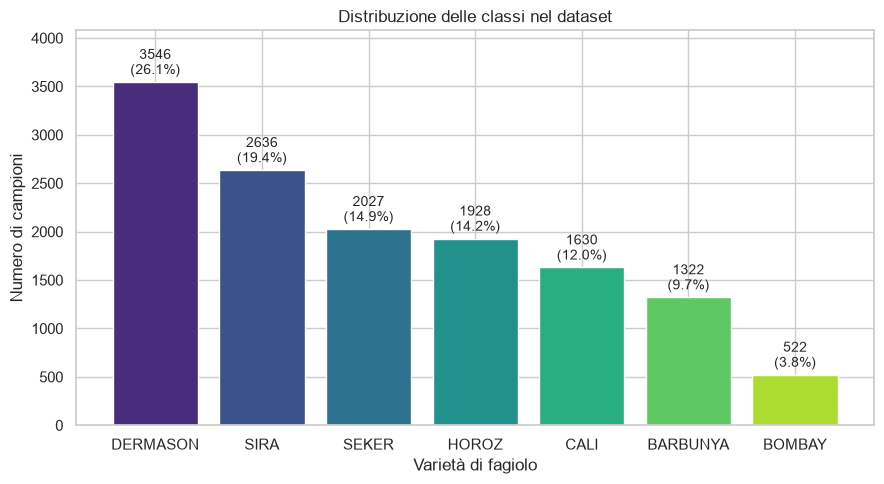

Rapporto tra classe più numerosa (DERMASON) e meno numerosa (BOMBAY): 6.8


In [8]:
conteggi = df["Class"].value_counts()
percentuali = conteggi / conteggi.sum() * 100

fig, ax = plt.subplots(figsize=(9, 5))
barre = ax.bar(conteggi.index, conteggi.values, color=sns.color_palette("viridis", len(conteggi)))
for barra, n, p in zip(barre, conteggi.values, percentuali.values):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 40,
            f"{n}\n({p:.1f}%)", ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, conteggi.max() * 1.15)
ax.set_xlabel("Varietà di fagiolo")
ax.set_ylabel("Numero di campioni")
ax.set_title("Distribuzione delle classi nel dataset")
fig.tight_layout()
salva_figura(fig, "01_distribuzione_classi")
plt.show()

rapporto = conteggi.max() / conteggi.min()
print(f"Rapporto tra classe più numerosa ({conteggi.idxmax()}) e meno numerosa ({conteggi.idxmin()}): {rapporto:.1f}")

Il dataset è **sbilanciato**: *Dermason* è la classe più numerosa, *Bombay* la meno rappresentata, con un
rapporto di circa 6,8 a 1. Di conseguenza l'*accuracy* da sola può essere fuorviante: nella valutazione si
useranno anche precision, recall ed F1 in media **macro** (ogni classe pesa allo stesso modo), oltre alle
matrici di confusione e alle curve ROC per classe. Lo split sarà **stratificato** per mantenere le stesse
proporzioni di classe in train, validation e test.

### 1.6 Distribuzione delle feature

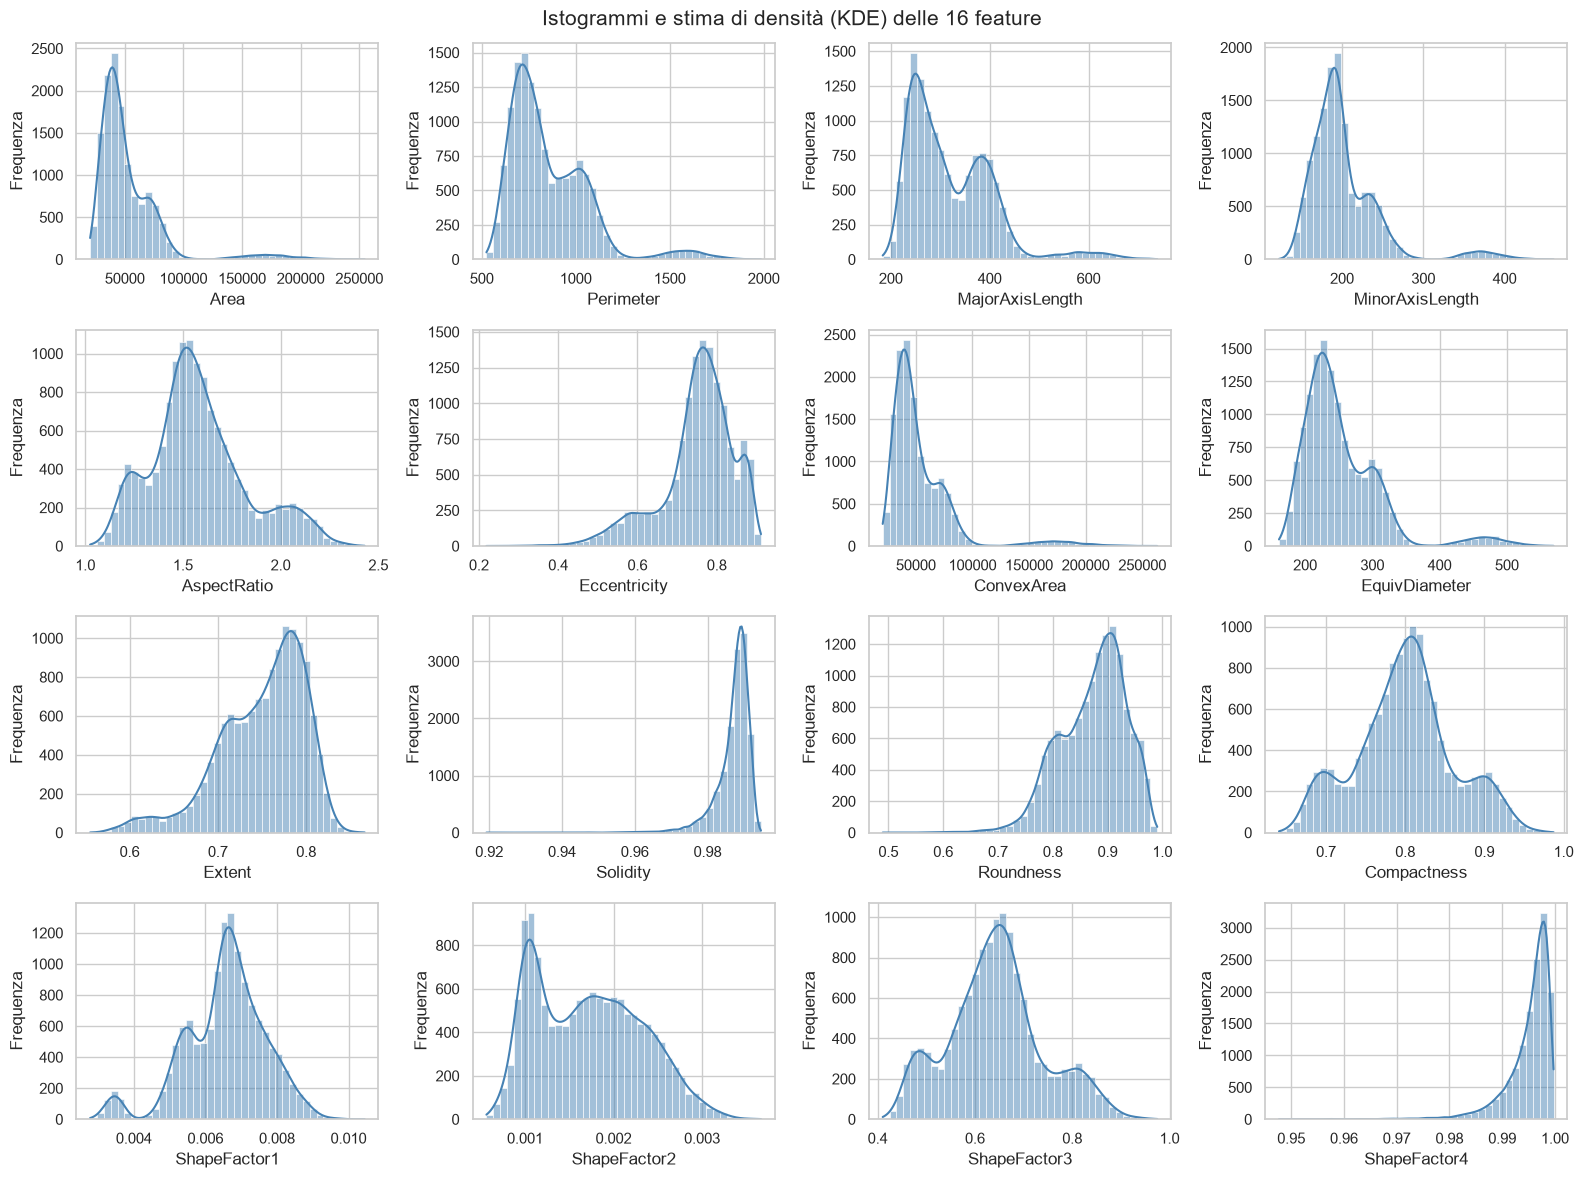

In [9]:
fig, assi = plt.subplots(4, 4, figsize=(16, 12))
for ax, feat in zip(assi.ravel(), FEATURES):
    sns.histplot(df[feat], kde=True, bins=40, color="steelblue", ax=ax)
    ax.set_xlabel(feat)
    ax.set_ylabel("Frequenza")
fig.suptitle("Istogrammi e stima di densità (KDE) delle 16 feature", fontsize=15)
fig.tight_layout()
salva_figura(fig, "01_istogrammi_feature")
plt.show()

In [10]:
asimmetria = df[FEATURES].skew().sort_values(key=abs, ascending=False)
asimmetria.rename("asimmetria (skewness)").to_frame().T

,Area,ConvexArea,ShapeFactor4,Solidity,MinorAxisLength,EquivDiameter,Perimeter,MajorAxisLength,Eccentricity,Extent,Roundness,AspectRatio,ShapeFactor1,ShapeFactor2,ShapeFactor3,Compactness
asimmetria (skewness),2.9529,2.9418,-2.7595,-2.5501,2.2382,1.949,1.6261,1.3578,-1.0628,-0.8953,-0.6357,0.5826,-0.5341,0.3012,0.2425,0.0371


Molte feature non hanno una distribuzione simmetrica. Le grandezze dimensionali (`Area`, `ConvexArea`,
`MinorAxisLength`) hanno una coda lunga a destra; `Solidity` e `ShapeFactor4` sono invece concentrate vicino al
valore massimo, con una coda verso sinistra. Diverse distribuzioni risultano inoltre **multimodali**: i picchi
corrispondono ai raggruppamenti per varietà, un primo segnale che le classi sono almeno in parte separabili.

### 1.7 Confronto tra le classi
Boxplot per classe di sei feature, scelte per coprire sia la dimensione (`Area`, `MajorAxisLength`) sia la
forma (`AspectRatio`, `Roundness`, `ShapeFactor1`, `Solidity`).

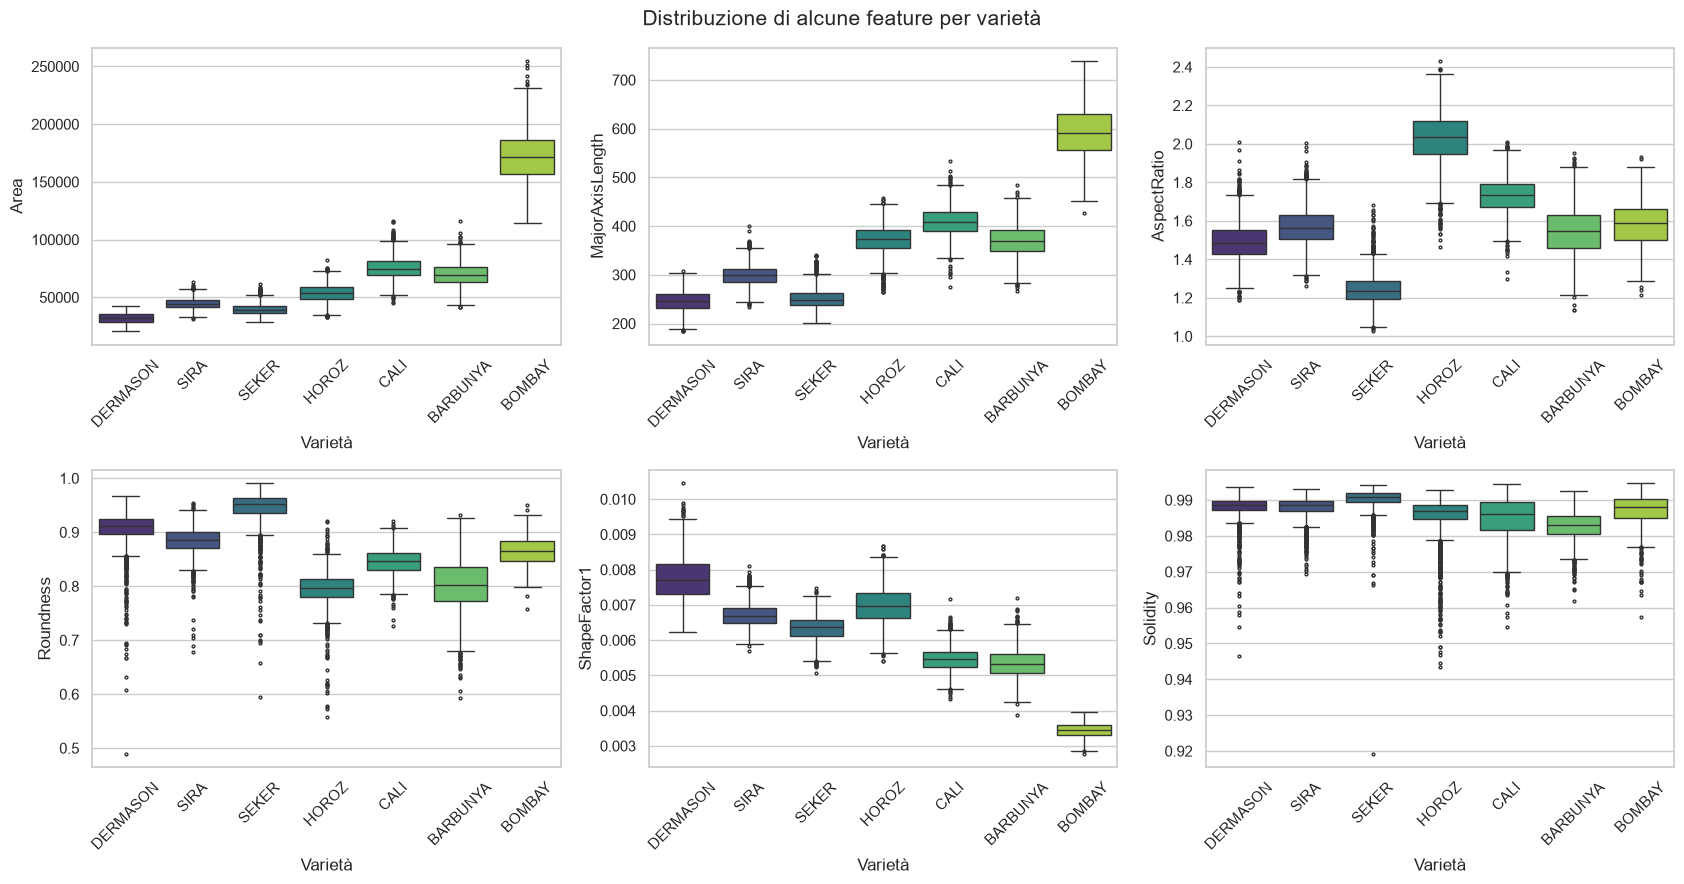

In [11]:
FEATURE_BOXPLOT = ["Area", "MajorAxisLength", "AspectRatio", "Roundness", "ShapeFactor1", "Solidity"]
ordine_classi = list(conteggi.index)

fig, assi = plt.subplots(2, 3, figsize=(17, 9))
for ax, feat in zip(assi.ravel(), FEATURE_BOXPLOT):
    sns.boxplot(data=df, x="Class", y=feat, order=ordine_classi, hue="Class", hue_order=ordine_classi,
                palette="viridis", legend=False, fliersize=2, ax=ax)
    ax.set_xlabel("Varietà")
    ax.set_ylabel(feat)
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Distribuzione di alcune feature per varietà", fontsize=15)
fig.tight_layout()
salva_figura(fig, "01_boxplot_per_classe")
plt.show()

Le varietà si distinguono bene su alcune feature: *Bombay* ha semi nettamente più grandi delle altre (`Area`,
`MajorAxisLength`), *Horoz* è la più allungata (`AspectRatio` elevato) e *Seker* la più tondeggiante.
Altre classi hanno invece distribuzioni che si sovrappongono in molte feature: ad esempio *Dermason* e *Sira*
in `AspectRatio`, `Roundness` e `Solidity`, oppure *Barbunya* e *Cali* in `Area`. Su queste coppie ci aspettiamo
la maggior parte degli errori di classificazione, da verificare con le matrici di confusione.

### 1.8 Correlazioni tra le feature

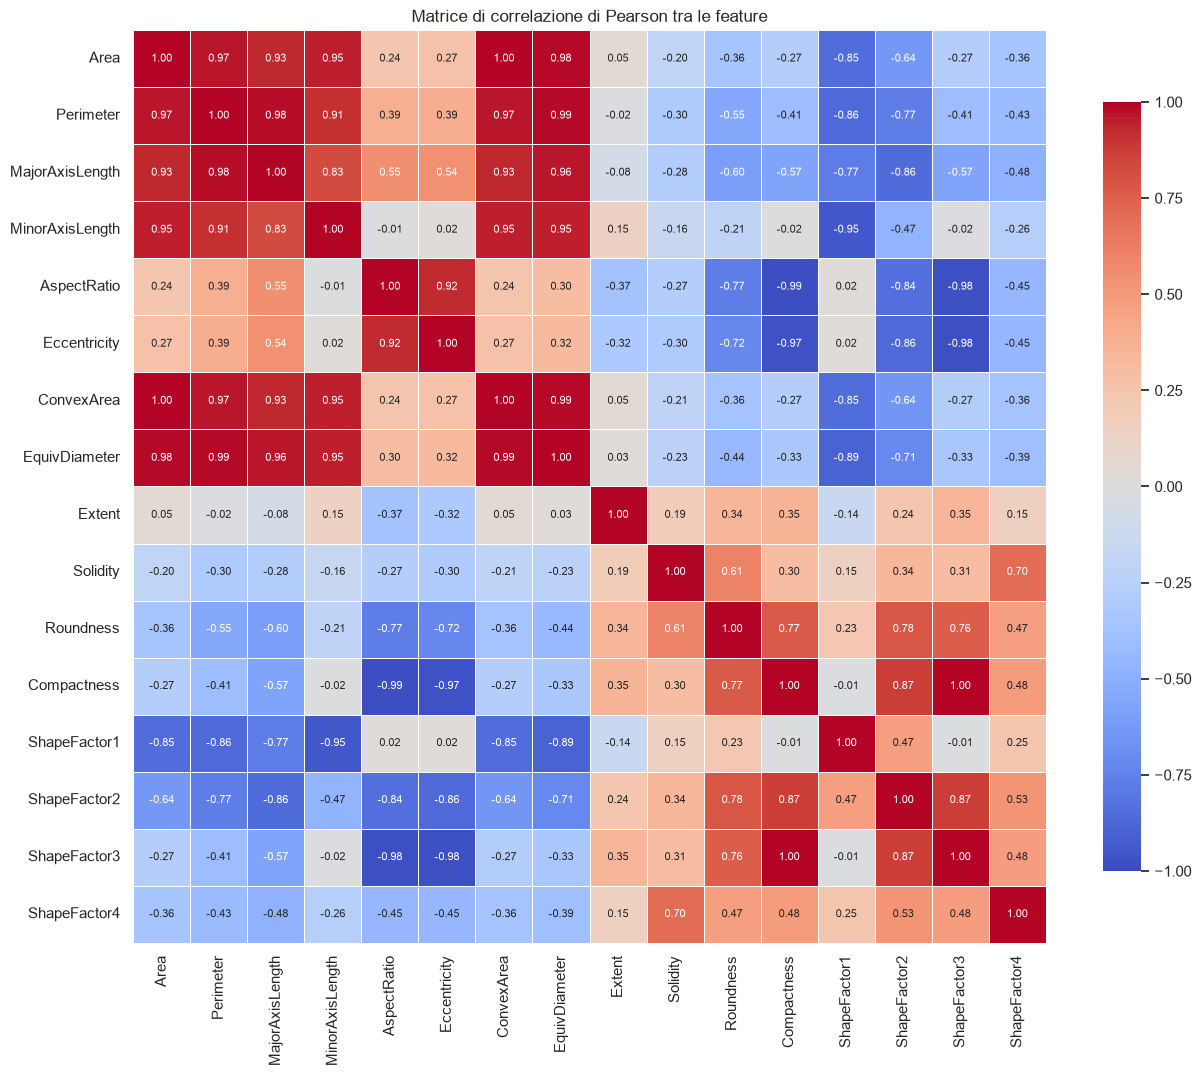

Coppie di feature: 120
Coppie con |r| > 0.90: 21
Coppie con |r| > 0.95: 15

Le 8 coppie più correlate:


,,r
Area,ConvexArea,0.9999
Compactness,ShapeFactor3,0.9987
Perimeter,EquivDiameter,0.9914
AspectRatio,Compactness,-0.9877
ConvexArea,EquivDiameter,0.9852
Area,EquivDiameter,0.9850
Eccentricity,ShapeFactor3,-0.9811
AspectRatio,ShapeFactor3,-0.9786


In [12]:
corr = df[FEATURES].corr()

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, annot_kws={"size": 8}, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Matrice di correlazione di Pearson tra le feature")
fig.tight_layout()
salva_figura(fig, "01_correlazioni")
plt.show()

# coppie di feature distinte, ordinate per correlazione assoluta
triangolo = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()
n_coppie = len(triangolo)
print(f"Coppie di feature: {n_coppie}")
print(f"Coppie con |r| > 0.90: {int((triangolo.abs() > 0.90).sum())}")
print(f"Coppie con |r| > 0.95: {int((triangolo.abs() > 0.95).sum())}")
print("\nLe 8 coppie più correlate:")
triangolo.reindex(triangolo.abs().sort_values(ascending=False).index).head(8).rename("r").to_frame()

La matrice mostra una **forte collinearità**: molte coppie hanno correlazione quasi perfetta, in particolare
`Area`, `ConvexArea` e `EquivDiameter` (che misurano di fatto la stessa grandezza), e `Compactness`,
`ShapeFactor3`, `AspectRatio`, `Eccentricity` (descrivono tutte quanto il seme è allungato). Le 16 feature
contengono quindi molta informazione ridondante e il numero di dimensioni realmente indipendenti è molto
inferiore a 16. Questo giustifica il **Task 1**: la **PCA** permette di rappresentare i dati con poche
componenti incorrelate che catturano quasi tutta la varianza. La collinearità può inoltre disturbare i modelli
lineari, come la regressione logistica, e distorcere le distanze nel KNN.

## 2. Suddivisione dei dati: train, validation e test
Tutti i modelli del notebook (PCA, classificatori shallow e rete neurale) usano **la stessa suddivisione**,
in modo che i confronti siano equi:

- **train (70%)**: addestramento dei modelli e adattamento di scaler e PCA;
- **validation (15%)**: scelta degli iperparametri e *early stopping* della rete neurale;
- **test (15%)**: valutazione finale, usato una sola volta a modello scelto.

Lo split è **stratificato** (stessa proporzione di classi in ogni sottoinsieme) e lavora sugli **indici** delle
righe, che vengono salvati in `results/split_indices.npz` per poterlo riprodurre in qualunque sezione.

### 2.1 Rimozione dei duplicati
Come visto nell'analisi esplorativa, il dataset contiene righe duplicate. Vanno eliminate **prima** dello split:
se una riga e la sua copia finissero in sottoinsiemi diversi, il campione di test sarebbe già stato visto
durante l'addestramento (*data leakage*) e le metriche risulterebbero artificialmente più alte.
Si conserva la prima occorrenza di ciascun gruppo di righe identiche.

In [13]:
df_originale = df                       # dataset completo, come letto dal CSV
n_prima = len(df_originale)
df = df_originale.drop_duplicates().reset_index(drop=True)
n_dopo = len(df)

print(f"Righe prima della rimozione dei duplicati: {n_prima}")
print(f"Righe rimosse:                             {n_prima - n_dopo}")
print(f"Righe dopo la rimozione:                   {n_dopo}")
assert df.duplicated().sum() == 0

confronto_classi = pd.DataFrame({
    "prima": df_originale["Class"].value_counts(),
    "dopo": df["Class"].value_counts(),
})
confronto_classi["rimosse"] = confronto_classi["prima"] - confronto_classi["dopo"]
confronto_classi

Righe prima della rimozione dei duplicati: 13611
Righe rimosse:                             68
Righe dopo la rimozione:                   13543


,prima,dopo,rimosse
Class,,,
DERMASON,3546,3546,0
SIRA,2636,2636,0
SEKER,2027,2027,0
HOROZ,1928,1860,68
CALI,1630,1630,0
BARBUNYA,1322,1322,0
BOMBAY,522,522,0


I duplicati rimossi appartengono tutti a una sola classe, *Horoz*; le proporzioni tra le classi restano
praticamente invariate. Da qui in avanti `df` indica il dataset **senza duplicati** e gli indici dello split
si riferiscono alle sue righe (`df_originale` conserva la versione completa).

### 2.2 Codifica delle etichette
`LabelEncoder` trasforma i nomi delle varietà in interi da 0 a 6, in ordine alfabetico. L'elenco `NOMI_CLASSI`
segue lo stesso ordine ed è usato da tutte le sezioni per le etichette di matrici di confusione e curve ROC.

In [14]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

encoder = LabelEncoder()
y = encoder.fit_transform(df["Class"])
NOMI_CLASSI = list(encoder.classes_)
X = df[FEATURES].to_numpy(dtype=float)

print("Codifica delle classi:", {i: nome for i, nome in enumerate(NOMI_CLASSI)})
print(f"X: {X.shape}, y: {y.shape}")

Codifica delle classi: {0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}
X: (13543, 16), y: (13543,)


### 2.3 Split stratificato 70 / 15 / 15
Due chiamate successive a `train_test_split`: la prima separa il 70% per il train, la seconda divide a metà
il 30% rimanente tra validation e test. Entrambe sono stratificate e usano `random_state=SEED`.

In [15]:
indici = np.arange(len(df))

idx_train, idx_temp = train_test_split(
    indici, test_size=0.30, stratify=y, random_state=SEED)
idx_val, idx_test = train_test_split(
    idx_temp, test_size=0.50, stratify=y[idx_temp], random_state=SEED)

np.savez(CARTELLA_RISULTATI / "split_indices.npz",
         idx_train=idx_train, idx_val=idx_val, idx_test=idx_test)

# verifiche: sottoinsiemi disgiunti e che coprono tutto il dataset
assert len(set(idx_train) & set(idx_val)) == 0
assert len(set(idx_train) & set(idx_test)) == 0
assert len(set(idx_val) & set(idx_test)) == 0
assert np.array_equal(np.sort(np.concatenate([idx_train, idx_val, idx_test])), indici)

X_train, X_val, X_test = X[idx_train], X[idx_val], X[idx_test]
y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]

riepilogo = pd.DataFrame({
    "campioni": [len(idx_train), len(idx_val), len(idx_test), len(df)],
    "percentuale": [100 * len(i) / len(df) for i in (idx_train, idx_val, idx_test, df)],
}, index=["train", "validation", "test", "totale"])
riepilogo

,campioni,percentuale
train,9480,69.9993
validation,2031,14.9967
test,2032,15.0041
totale,13543,100.0000


### 2.4 Controllo delle proporzioni di classe
Tabella con la percentuale di ogni classe in ciascun sottoinsieme: grazie alla stratificazione le colonne
devono coincidere, a meno di piccole differenze dovute all'arrotondamento.

In [16]:
proporzioni = pd.DataFrame({
    "dataset": pd.Series(y).value_counts(normalize=True).sort_index(),
    "train": pd.Series(y_train).value_counts(normalize=True).sort_index(),
    "validation": pd.Series(y_val).value_counts(normalize=True).sort_index(),
    "test": pd.Series(y_test).value_counts(normalize=True).sort_index(),
}) * 100
proporzioni.index = NOMI_CLASSI

conteggi_split = pd.DataFrame({
    "train": np.bincount(y_train, minlength=len(NOMI_CLASSI)),
    "validation": np.bincount(y_val, minlength=len(NOMI_CLASSI)),
    "test": np.bincount(y_test, minlength=len(NOMI_CLASSI)),
}, index=NOMI_CLASSI)
conteggi_split.loc["totale"] = conteggi_split.sum()

# ogni classe è presente in tutti i sottoinsiemi e la proporzione differisce al più di 0,5 punti percentuali
assert (conteggi_split.drop(index="totale") > 0).all().all()
assert (proporzioni[["train", "validation", "test"]].sub(proporzioni["dataset"], axis=0).abs() < 0.5).all().all()

print("Numero di campioni per classe e sottoinsieme")
display(conteggi_split)
print("\nPercentuale di ogni classe (%)")
proporzioni

Numero di campioni per classe e sottoinsieme


,train,validation,test
BARBUNYA,925,199,198
BOMBAY,366,78,78
CALI,1141,244,245
DERMASON,2482,532,532
HOROZ,1302,279,279
SEKER,1419,304,304
SIRA,1845,395,396
totale,9480,2031,2032



Percentuale di ogni classe (%)


,dataset,train,validation,test
BARBUNYA,9.7615,9.7574,9.7981,9.7441
BOMBAY,3.8544,3.8608,3.8405,3.8386
CALI,12.0357,12.0359,12.0138,12.0571
DERMASON,26.1833,26.1814,26.1940,26.1811
HOROZ,13.7340,13.7342,13.7371,13.7303
SEKER,14.9671,14.9684,14.9680,14.9606
SIRA,19.4639,19.4620,19.4485,19.4882


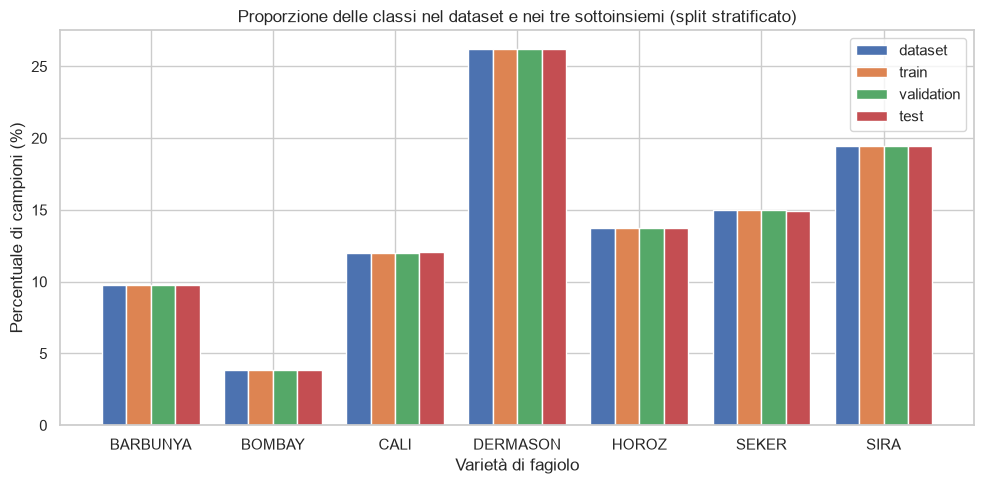

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))
larghezza = 0.2
posizioni = np.arange(len(NOMI_CLASSI))
for k, colonna in enumerate(["dataset", "train", "validation", "test"]):
    ax.bar(posizioni + (k - 1.5) * larghezza, proporzioni[colonna], width=larghezza, label=colonna)
ax.set_xticks(posizioni)
ax.set_xticklabels(NOMI_CLASSI)
ax.set_xlabel("Varietà di fagiolo")
ax.set_ylabel("Percentuale di campioni (%)")
ax.set_title("Proporzione delle classi nel dataset e nei tre sottoinsiemi (split stratificato)")
ax.legend()
fig.tight_layout()
salva_figura(fig, "02_proporzioni_split")
plt.show()

### 2.5 Standardizzazione
Lo `StandardScaler` sottrae la media e divide per la deviazione standard di ogni feature. Viene **fittato
solo sul train** e poi applicato a validation e test: usare media e deviazione di tutto il dataset farebbe
filtrare nel training informazioni sui dati di valutazione.

Restano disponibili sia le versioni non scalate (`X_train`, `X_val`, `X_test`, utili ad esempio per gli
alberi, che non risentono della scala) sia quelle scalate (`X_train_s`, `X_val_s`, `X_test_s`).

In [18]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)      # fit solo sul train
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

# sul train la media è ~0 e la deviazione standard ~1; su val e test no (come previsto)
assert np.allclose(X_train_s.mean(axis=0), 0, atol=1e-8)
assert np.allclose(X_train_s.std(axis=0), 1, atol=1e-8)

print(f"X_train_s: {X_train_s.shape}   X_val_s: {X_val_s.shape}   X_test_s: {X_test_s.shape}")
pd.DataFrame({
    "media": [X_train_s.mean(), X_val_s.mean(), X_test_s.mean()],
    "dev. standard": [X_train_s.std(), X_val_s.std(), X_test_s.std()],
}, index=["train (scalato)", "validation (scalato)", "test (scalato)"])

X_train_s: (9480, 16)   X_val_s: (2031, 16)   X_test_s: (2032, 16)


,media,dev. standard
train (scalato),-6.5265e-14,1.0000
validation (scalato),-8.7142e-04,0.9978
test (scalato),4.0385e-03,1.0064


## 3. Task 1 – Analisi delle feature con PCA
### 3.1 Perché la PCA

L'**analisi delle componenti principali** (PCA, *Principal Component Analysis*) cerca una nuova base ortogonale
dello spazio delle feature: le **componenti principali** sono combinazioni lineari delle feature originali,
tra loro incorrelate e ordinate per **varianza** decrescente. La prima componente è la direzione lungo cui i dati
variano di più, la seconda è la direzione di massima varianza ortogonale alla prima, e così via. Tenendo solo le
prime componenti si ottiene una rappresentazione compatta che conserva la maggior parte dell'informazione.

Le scelte di questa sezione:
- **Standardizzazione.** La PCA massimizza la varianza, quindi è sensibile alla scala: senza standardizzare,
  `Area` e `ConvexArea` (decine di migliaia di pixel) dominerebbero le componenti solo per via dell'unità di
  misura. Si usano per questo i dati già standardizzati (`X_train_s`): su dati a media 0 e varianza 1 la PCA
  equivale a diagonalizzare la **matrice di correlazione**.
- **Nessun leakage.** La PCA è **fittata solo sul training set**; validation e test vengono poi proiettati con
  la stessa trasformazione, esattamente come avviene per lo scaler. Il test set non viene mai usato in questa sezione
  (nemmeno proiettato); il confronto extra della sezione 3.7 usa solo il validation.
- **Perché ha senso qui.** L'analisi esplorativa ha mostrato una forte collinearità (21 coppie di feature su 120
  con |r| > 0,90): molte feature misurano la stessa grandezza, quindi il numero di dimensioni realmente
  indipendenti è molto minore di 16.

Obiettivi: quantificare quante componenti servono, **visualizzare** le varietà nello spazio ridotto e
**interpretare** le componenti tramite i loro *loadings*.

### 3.2 Implementazione della PCA
Prima di usare la libreria, l'algoritmo è implementato "a mano" con la sola libreria numpy, nella classe
`PCAManuale`. Sia $X$ la matrice $n \times p$ dei dati di training (qui $p = 16$ feature standardizzate). I passi sono:

1. **Centratura.** Si sottrae a ogni colonna la media del train: $\tilde{X} = X - \mu$. I dati standardizzati
   sono già centrati, ma la media $\mu$ viene comunque calcolata e salvata, perché la stessa trasformazione deve
   poter essere applicata a validation e test.
2. **Matrice di covarianza.** $C = \dfrac{\tilde{X}^\top \tilde{X}}{n-1}$, matrice $p \times p$ simmetrica. Su dati
   standardizzati coincide con la matrice di correlazione.
3. **Autovalori e autovettori.** Si risolve $C\,w_i = \lambda_i\,w_i$ con `np.linalg.eigh`, indicata per le matrici
   simmetriche: restituisce autovalori reali e autovettori ortonormali.
4. **Ordinamento.** Gli autovalori sono ordinati in senso decrescente, $\lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_p$, e gli
   autovettori $w_i$ (le componenti principali) di conseguenza.
5. **Varianza spiegata.** La componente $i$ spiega la frazione $\dfrac{\lambda_i}{\sum_{j=1}^{p} \lambda_j}$ della varianza totale.
6. **Proiezione.** I dati si proiettano sulle prime $k$ componenti: $Z = (X - \mu)\,W_k$, dove $W_k$ ha come colonne
   $w_1, \dots, w_k$.

Un autovettore è definito solo **a meno del segno** ($w_i$ e $-w_i$ sono entrambi validi). Per rendere il risultato
deterministico e confrontabile, si sceglie il segno in modo che la componente di **valore assoluto massimo** di ogni autovettore
sia positiva. Come in scikit-learn, `componenti_` ha un autovettore per riga.

In [19]:
class PCAManuale:
    """PCA scritta con la sola libreria numpy (centratura, covarianza, autovalori/autovettori, proiezione)."""

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        n = X.shape[0]
        self.media_ = X.mean(axis=0)
        Xc = X - self.media_                                  # 1. centratura con la media del train
        C = Xc.T @ Xc / (n - 1)                               # 2. matrice di covarianza (p x p, simmetrica)
        autovalori, autovettori = np.linalg.eigh(C)           # 3. autovalori/autovettori (autovettori in colonna)
        ordine = np.argsort(autovalori)[::-1]                 # 4. ordine decrescente di autovalore
        autovalori, autovettori = autovalori[ordine], autovettori[:, ordine]
        # segno deterministico: la componente di valore assoluto massimo di ogni autovettore è positiva
        idx_max = np.argmax(np.abs(autovettori), axis=0)
        segni = np.sign(autovettori[idx_max, np.arange(autovettori.shape[1])])
        segni[segni == 0] = 1.0
        autovettori = autovettori * segni
        self.autovalori_ = autovalori
        self.componenti_ = autovettori.T                      # un autovettore per riga, come in sklearn
        self.varianza_spiegata_ratio_ = autovalori / autovalori.sum()   # 5. varianza spiegata
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return (X - self.media_) @ self.componenti_.T         # 6. Z = (X - mu) W


# fit sul solo train standardizzato, come per il resto della sezione
pca_manuale = PCAManuale().fit(X_train_s)

**Confronto con scikit-learn.** La PCA di libreria (`sklearn.decomposition.PCA`, con tutte le 16 componenti) viene
fittata sugli stessi dati e confrontata con quella manuale: varianza spiegata, componenti (a meno del segno) e
proiezioni del train. Il fit di scikit-learn è quello che resta poi in `pca_completa`.

In [20]:
import itertools

from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

COLORI_CLASSI = sns.color_palette("tab10", len(NOMI_CLASSI))

# PCA completa di libreria: tutte le 16 componenti, fittata SOLO sul train standardizzato
pca_completa = PCA(n_components=None, random_state=SEED)
pca_completa.fit(X_train_s)

# 1) varianza spiegata delle prime componenti nelle due implementazioni
var_man = pca_manuale.varianza_spiegata_ratio_
var_sk = pca_completa.explained_variance_ratio_
confronto_varianza = pd.DataFrame({
    "sklearn (%)": (var_sk[:6] * 100).round(4),
    "manuale (%)": (var_man[:6] * 100).round(4),
    "differenza assoluta (frazione di varianza)": [f"{d:.1e}" for d in np.abs(var_sk[:6] - var_man[:6])],
}, index=[f"PC{i + 1}" for i in range(6)])
display(confronto_varianza)

# 2) componenti: gli autovettori sono definiti a meno del segno, quindi si allinea il segno di ciascuna
#    componente manuale a quella di sklearn tramite il prodotto scalare
segno_comp = np.sign(np.sum(pca_manuale.componenti_ * pca_completa.components_, axis=1))
diff_comp = np.abs(pca_manuale.componenti_ * segno_comp[:, None] - pca_completa.components_).max()

# 3) proiezioni del train: confronto colonna per colonna, sempre a meno del segno
Z_man = pca_manuale.transform(X_train_s)
Z_sk = pca_completa.transform(X_train_s)
segno_proj = np.sign(np.sum(Z_man * Z_sk, axis=0))
diff_proj = np.abs(Z_man * segno_proj - Z_sk).max()
diff_var = np.abs(var_man - var_sk).max()
diff_autoval = np.abs(pca_manuale.autovalori_ - pca_completa.explained_variance_).max()

assert np.allclose(var_man, var_sk, rtol=0, atol=1e-10), "varianza spiegata diversa"
assert np.allclose(pca_manuale.autovalori_, pca_completa.explained_variance_, rtol=1e-8, atol=1e-10), "autovalori diversi"
assert np.allclose(np.abs(pca_manuale.componenti_), np.abs(pca_completa.components_), atol=1e-6), "componenti diverse"
assert np.allclose(pca_manuale.componenti_ * segno_comp[:, None], pca_completa.components_, atol=1e-6), "componenti diverse (segno allineato)"
assert np.allclose(Z_man * segno_proj, Z_sk, atol=1e-6), "proiezioni del train diverse"

print(f"Differenza massima, varianza spiegata (16 componenti): {diff_var:.2e}")
print(f"Differenza massima, autovalori:                       {diff_autoval:.2e}")
print(f"Differenza massima, componenti (segno allineato):     {diff_comp:.2e}")
print(f"Differenza massima, proiezioni del train:             {diff_proj:.2e}")
print(f"Componenti con segno discorde tra le due implementazioni: {int((segno_comp < 0).sum())} su {len(segno_comp)}")
print("Controlli superati: le due implementazioni coincidono.")

,sklearn (%),manuale (%),differenza assoluta (frazione di varianza)
PC1,55.5443,55.5443,0.0e+00
PC2,26.3680,26.3680,5.6e-17
PC3,8.0263,8.0263,2.8e-17
PC4,5.1294,5.1294,6.9e-18
PC5,2.6960,2.6960,3.5e-17
PC6,1.1398,1.1398,1.4e-17


Differenza massima, varianza spiegata (16 componenti): 5.55e-17
Differenza massima, autovalori:                       1.78e-15
Differenza massima, componenti (segno allineato):     5.65e-10
Differenza massima, proiezioni del train:             2.38e-11
Componenti con segno discorde tra le due implementazioni: 0 su 16
Controlli superati: le due implementazioni coincidono.


**Risultato del confronto.** Le due implementazioni coincidono: la varianza spiegata è identica fino alla
precisione di macchina (differenza massima sulle 16 componenti 5,6e-17, sugli autovalori 1,8e-15), le componenti
differiscono al più di 5,7e-10 e le proiezioni del train di 2,4e-11, cioè solo per errori numerici di arrotondamento
(le due librerie usano algoritmi diversi: `eigh` sulla matrice di covarianza contro la SVD dei dati centrati). Con la
convenzione adottata (componente di valore assoluto massimo positiva) i segni coincidono su tutte e 16
le componenti; il confronto è comunque fatto a meno del segno, che per un autovettore è arbitrario. Gli `assert` della cella
precedente verificano queste uguaglianze.

Poiché le due versioni sono equivalenti, nel resto della sezione si usa l'oggetto di libreria `pca_completa`, che
resta anche la variabile esposta alle altre sezioni; `pca_manuale` è esposta in più come dimostrazione
dell'implementazione. Tutti i numeri e le figure seguenti sono quelli della PCA di libreria.

### 3.3 PCA completa e varianza spiegata
La PCA con tutte le 16 componenti, fittata sopra sul train standardizzato (`pca_completa`), fornisce la varianza
spiegata di ciascuna componente. `varianza_spiegata` contiene la frazione di varianza di ciascuna componente e
`n_comp_95` il numero minimo di componenti che ne spiega almeno il 95%.

In [21]:
varianza_spiegata = pca_completa.explained_variance_ratio_      # frazione di varianza per componente
varianza_cumulata = np.cumsum(varianza_spiegata)
autovalori = pca_completa.explained_variance_                   # autovalori della matrice di covarianza (= correlazione)

n_comp_90 = int(np.searchsorted(varianza_cumulata, 0.90) + 1)
n_comp_95 = int(np.searchsorted(varianza_cumulata, 0.95) + 1)

# proiezione di train e validation nello spazio delle componenti (trasformazione fittata sul train)
Z_train = pca_completa.transform(X_train_s)
Z_val = pca_completa.transform(X_val_s)

nomi_pc = [f"PC{i + 1}" for i in range(len(varianza_spiegata))]
tabella_varianza = pd.DataFrame({
    "autovalore": autovalori,
    "varianza spiegata (%)": varianza_spiegata * 100,
    "varianza cumulata (%)": varianza_cumulata * 100,
}, index=nomi_pc)
display(tabella_varianza.round(3))

print(f"Componenti per spiegare almeno il 90% della varianza: {n_comp_90}")
print(f"Componenti per spiegare almeno il 95% della varianza: {n_comp_95}")
print(f"Componenti con autovalore > 1 (criterio di Kaiser): {int((autovalori > 1).sum())}")

,autovalore,varianza spiegata (%),varianza cumulata (%)
PC1,8.888,55.544,55.544
PC2,4.219,26.368,81.912
PC3,1.284,8.026,89.939
PC4,0.821,5.129,95.068
PC5,0.431,2.696,97.764
PC6,0.182,1.140,98.904
PC7,0.112,0.702,99.606
PC8,0.052,0.325,99.931
PC9,0.008,0.051,99.982
PC10,0.001,0.009,99.991


Componenti per spiegare almeno il 90% della varianza: 4
Componenti per spiegare almeno il 95% della varianza: 4
Componenti con autovalore > 1 (criterio di Kaiser): 3


**Scree plot.** Le barre mostrano la varianza spiegata da ogni componente, la linea quella cumulata; le tratteggiate
indicano le soglie del 90% e del 95%.

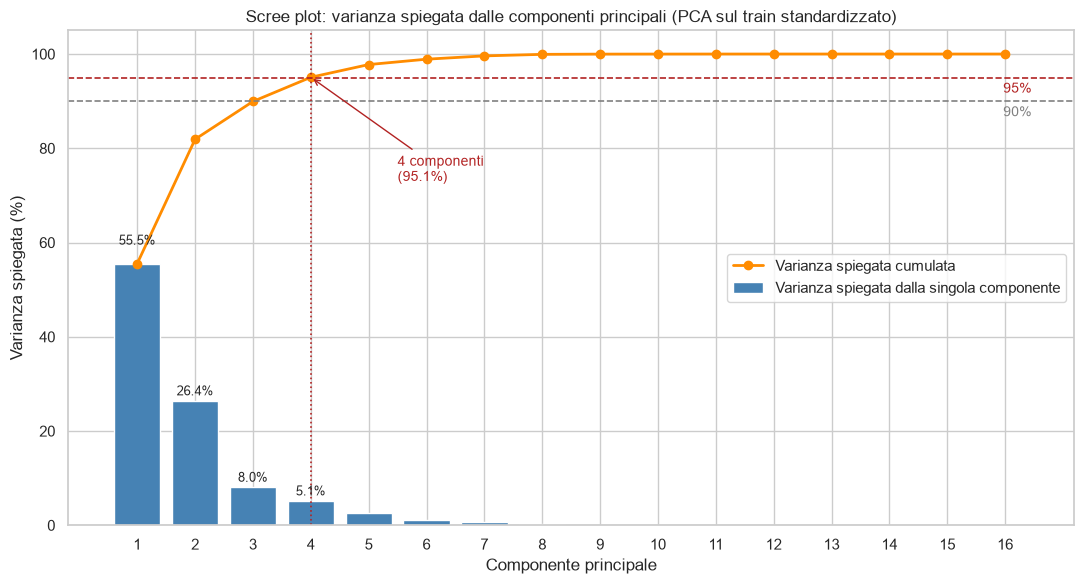

In [22]:
fig, ax = plt.subplots(figsize=(11, 6))
posizioni = np.arange(1, len(varianza_spiegata) + 1)
ax.bar(posizioni, varianza_spiegata * 100, color="steelblue", label="Varianza spiegata dalla singola componente")
ax.plot(posizioni, varianza_cumulata * 100, "o-", color="darkorange", lw=2, label="Varianza spiegata cumulata")
for soglia, colore in ((90, "grey"), (95, "firebrick")):
    ax.axhline(soglia, color=colore, ls="--", lw=1.2)
    ax.text(len(posizioni) + 0.45, soglia - 3.2, f"{soglia}%", color=colore, ha="right", fontsize=10)
ax.axvline(n_comp_95, color="firebrick", ls=":", lw=1.2)
ax.annotate(f"{n_comp_95} componenti\n({varianza_cumulata[n_comp_95 - 1] * 100:.1f}%)",
            xy=(n_comp_95, varianza_cumulata[n_comp_95 - 1] * 100),
            xytext=(n_comp_95 + 1.5, varianza_cumulata[n_comp_95 - 1] * 100 - 22),
            arrowprops={"arrowstyle": "->", "color": "firebrick"}, color="firebrick", fontsize=10)
for p, v in zip(posizioni[:4], varianza_spiegata[:4]):
    ax.text(p, v * 100 + (4 if p == 1 else 1.2), f"{v * 100:.1f}%", ha="center", fontsize=9)
ax.set_xticks(posizioni)
ax.set_xlabel("Componente principale")
ax.set_ylabel("Varianza spiegata (%)")
ax.set_ylim(0, 105)
ax.set_title("Scree plot: varianza spiegata dalle componenti principali (PCA sul train standardizzato)")
ax.legend(loc="center right")
fig.tight_layout()
salva_figura(fig, "03_pca_scree")
plt.show()

La varianza è concentrata in poche componenti: **PC1 spiega il 55,5%** della varianza totale, **PC2 il 26,4%** e
**PC3 l'8,0%**; già le prime due ne raccolgono l'81,9% e le prime tre l'89,9%, appena sotto il 90%. Servono
**4 componenti** per superare la soglia del 95% (95,1%, dunque di poco): `n_comp_95 = 4`, e per lo stesso motivo
anche la soglia del 90% richiede 4 componenti. Con 5 componenti si arriva al 97,8% e con 8 al 99,9%; dalla nona in
poi ogni componente spiega meno dello 0,06% e rappresenta in pratica rumore o ridondanza. Il criterio di Kaiser
(autovalore > 1) indicherebbe invece 3 componenti: la quarta ha autovalore 0,82, ma contribuisce con un ulteriore 5,1%.
In sintesi, le 16 feature si riducono a **circa 4 dimensioni effettive**, in accordo con la collinearità osservata
nell'EDA.

### 3.4 Proiezione dei dati nello spazio delle componenti
Il training set viene proiettato sulle prime due e tre componenti e colorato per varietà. Il colore non entra
nella PCA (è non supervisionata): serve solo a vedere se le classi si separano da sole.

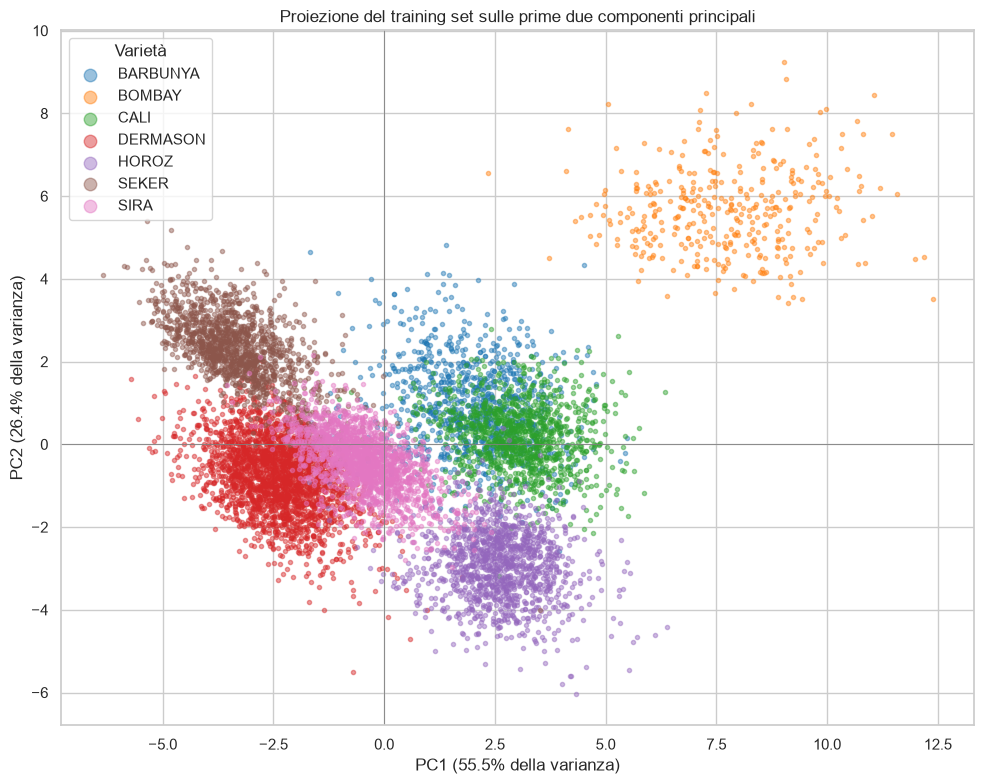

In [23]:
fig, ax = plt.subplots(figsize=(10, 8))
for k, nome in enumerate(NOMI_CLASSI):
    m = y_train == k
    ax.scatter(Z_train[m, 0], Z_train[m, 1], s=9, alpha=0.45, color=COLORI_CLASSI[k], label=nome)
ax.axhline(0, color="grey", lw=0.6)
ax.axvline(0, color="grey", lw=0.6)
ax.set_xlabel(f"PC1 ({varianza_spiegata[0] * 100:.1f}% della varianza)")
ax.set_ylabel(f"PC2 ({varianza_spiegata[1] * 100:.1f}% della varianza)")
ax.set_title("Proiezione del training set sulle prime due componenti principali")
ax.legend(title="Varietà", markerscale=3, loc="best")
fig.tight_layout()
salva_figura(fig, "03_pca_scatter_2d")
plt.show()

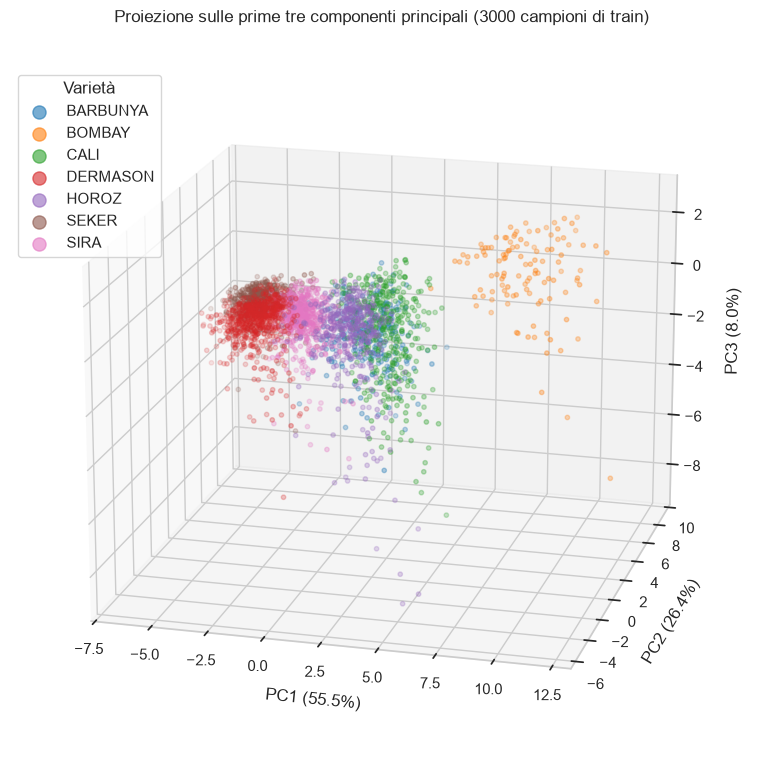

In [24]:
# per la leggibilità, nel grafico 3D si mostra un sottoinsieme casuale (riproducibile) del train
rng = np.random.default_rng(SEED)
idx_3d = rng.choice(len(Z_train), size=3000, replace=False)

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(1, 1, 1, projection="3d")
for k, nome in enumerate(NOMI_CLASSI):
    m = y_train[idx_3d] == k
    ax.scatter(Z_train[idx_3d][m, 0], Z_train[idx_3d][m, 1], Z_train[idx_3d][m, 2],
               s=10, alpha=0.6, color=COLORI_CLASSI[k], label=nome)
ax.set_xlabel(f"PC1 ({varianza_spiegata[0] * 100:.1f}%)", labelpad=8)
ax.set_ylabel(f"PC2 ({varianza_spiegata[1] * 100:.1f}%)", labelpad=8)
ax.set_zlabel(f"PC3 ({varianza_spiegata[2] * 100:.1f}%)", labelpad=10)
ax.tick_params(axis="z", pad=3)
ax.view_init(elev=18, azim=-75)
ax.set_title("Proiezione sulle prime tre componenti principali (3000 campioni di train)")
ax.legend(title="Varietà", loc="upper left", bbox_to_anchor=(0.0, 0.95), markerscale=3)
fig.tight_layout()
salva_figura(fig, "03_pca_scatter_3d")
plt.show()

In [25]:
# posizione media (centroide) e dispersione di ogni varietà sulle prime tre componenti, sul train
centroidi = pd.DataFrame(
    {nome: np.r_[Z_train[y_train == k, :3].mean(axis=0), Z_train[y_train == k, :3].std(axis=0)]
     for k, nome in enumerate(NOMI_CLASSI)},
    index=["PC1 media", "PC2 media", "PC3 media", "PC1 dev.st.", "PC2 dev.st.", "PC3 dev.st."]).T
centroidi

,PC1 media,PC2 media,PC3 media,PC1 dev.st.,PC2 dev.st.,PC3 dev.st.
BARBUNYA,1.9944,0.9414,-0.6345,1.1003,1.1088,0.9779
BOMBAY,7.7402,5.6568,0.6852,1.5994,1.0251,1.2157
CALI,3.0666,0.1900,-0.2125,0.9722,0.7833,1.4163
DERMASON,-2.3990,-0.7596,0.0613,0.8769,0.8924,0.7402
HOROZ,2.5819,-2.8982,0.2651,0.9849,0.8682,1.8319
SEKER,-3.3084,2.3119,-0.1843,0.9833,0.8422,0.7995
SIRA,-0.4821,-0.4226,0.1858,0.8428,0.7190,0.7420


**Lettura dei grafici.** Nel piano PC1-PC2 (82% della varianza) diverse varietà risultano ben separate:
- *Bombay* è isolata in alto a destra (centroide PC1 = 7,7, PC2 = 5,7), lontana da tutte le altre: sono i semi
  molto più grandi;
- *Seker* occupa l'angolo in alto a sinistra (PC1 = -3,3, PC2 = 2,3) e *Horoz* la zona in basso (PC2 = -2,9);
- *Cali* e *Barbunya* stanno a destra dell'origine, con PC1 intorno a 3,1 e 2,0.

La separazione **non è completa**: *Dermason* e *Sira* (centroidi a PC1 = -2,4 e -0,5, con deviazioni standard
tra 0,7 e 0,9 su entrambe le componenti) si sovrappongono molto, e lo stesso vale per *Barbunya* e *Cali*, i cui centroidi distano meno
di una deviazione standard su PC2. Sono le stesse coppie che l'EDA indicava come difficili, e prevedibilmente
quelle su cui i classificatori commetteranno più errori.

La terza componente aggiunge poca separazione tra le classi: le medie di PC3 sono comprese tra -0,6 e 0,7, contro
deviazioni standard fino a 1,8 (*Horoz*) e 1,4 (*Cali*). PC3 descrive quindi soprattutto la variabilità interna
alle varietà, con alcuni campioni isolati a valori molto negativi; il grafico 3D, da un unico punto di vista, mostra la
stessa struttura del piano PC1-PC2: *Bombay* è nettamente separata dal resto, mentre le altre varietà formano
una nuvola continua in cui *Seker* e *Dermason* stanno a sinistra, *Sira* al centro, *Horoz*, *Cali* e *Barbunya* a destra,
e la dispersione verticale (PC3) è maggiore per *Horoz* e *Cali*.

### 3.5 Interpretazione delle componenti: i loadings
I *loadings* indicano quanto ogni feature originale contribuisce a una componente. Qui sono calcolati come
autovettori moltiplicati per la radice dell'autovalore: poiché i dati sono standardizzati, il valore coincide con
la **correlazione** tra la feature e la componente (tra -1 e 1), facile da leggere in una heatmap. Si mostrano le
prime 5 componenti, che insieme spiegano il 97,8% della varianza.

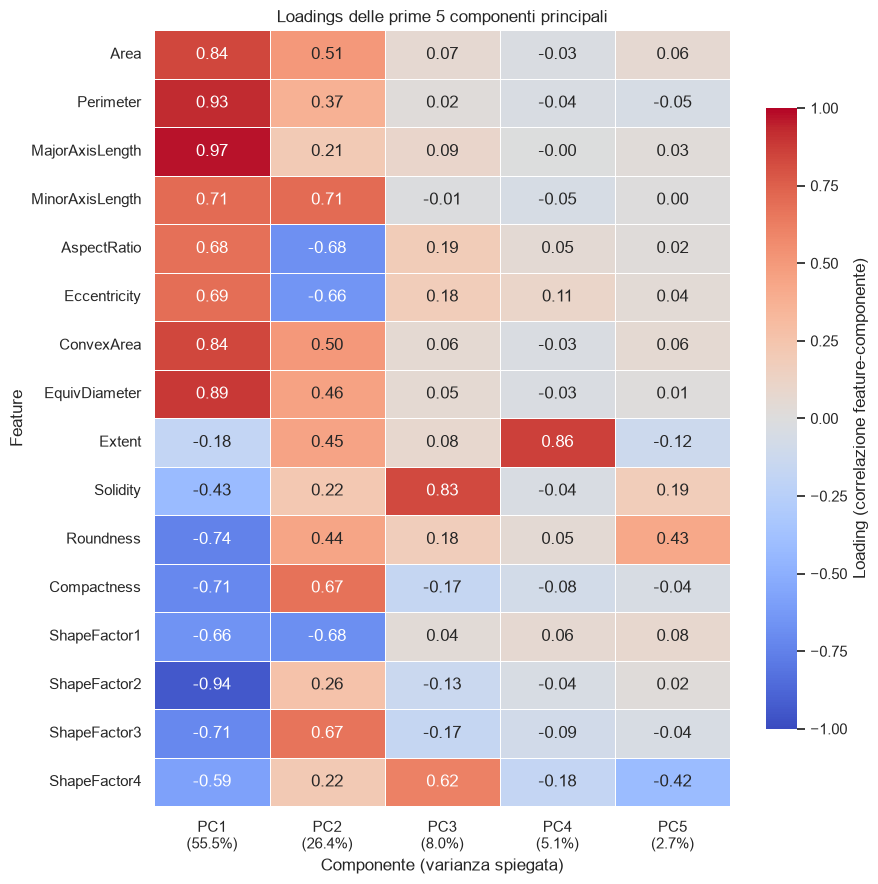

PC1: MajorAxisLength (+0.97), ShapeFactor2 (-0.94), Perimeter (+0.93), EquivDiameter (+0.89), ConvexArea (+0.84)
PC2: MinorAxisLength (+0.71), ShapeFactor1 (-0.68), AspectRatio (-0.68), Compactness (+0.67), ShapeFactor3 (+0.67)
PC3: Solidity (+0.83), ShapeFactor4 (+0.62), AspectRatio (+0.19), Eccentricity (+0.18), Roundness (+0.18)
PC4: Extent (+0.86), ShapeFactor4 (-0.18), Eccentricity (+0.11), ShapeFactor3 (-0.09), Compactness (-0.08)
PC5: Roundness (+0.43), ShapeFactor4 (-0.42), Solidity (+0.19), Extent (-0.12), ShapeFactor1 (+0.08)


In [26]:
# loadings = autovettori scalati con la radice dell'autovalore: per dati standardizzati sono le
# correlazioni tra ciascuna feature originale e la componente (valori in [-1, 1])
loadings = pca_completa.components_.T * np.sqrt(autovalori)
K_LOAD = 5
tabella_loadings = pd.DataFrame(loadings[:, :K_LOAD], index=FEATURES, columns=nomi_pc[:K_LOAD])

fig, ax = plt.subplots(figsize=(9, 9))
sns.heatmap(tabella_loadings, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0,
            linewidths=0.5, cbar_kws={"label": "Loading (correlazione feature-componente)", "shrink": 0.8}, ax=ax)
ax.set_xticklabels([f"{n}\n({v * 100:.1f}%)" for n, v in zip(nomi_pc[:K_LOAD], varianza_spiegata[:K_LOAD])])
ax.set_title(f"Loadings delle prime {K_LOAD} componenti principali")
ax.set_xlabel("Componente (varianza spiegata)")
ax.set_ylabel("Feature")
fig.tight_layout()
salva_figura(fig, "03_pca_loadings")
plt.show()

# feature con il contributo maggiore (|loading|) a ciascuna delle prime componenti
for c in range(K_LOAD):
    ordine = np.argsort(-np.abs(loadings[:, c]))[:5]
    elenco = ", ".join(f"{FEATURES[i]} ({loadings[i, c]:+.2f})" for i in ordine)
    print(f"{nomi_pc[c]}: {elenco}")

**Interpretazione** (basata sui loadings ottenuti):
- **PC1 (55,5%) – dimensione del seme**, con una componente di forma. I contributi maggiori sono positivi e
  dimensionali: `MajorAxisLength` (0,97), `Perimeter` (0,93), `EquivDiameter` (0,89), `Area` e `ConvexArea` (0,84),
  `MinorAxisLength` (0,71). Compare però anche `ShapeFactor2` con -0,94 (è un fattore di forma che decresce al crescere
  delle dimensioni), e le feature di rotondità hanno segno negativo (`Roundness` -0,74, `Compactness` e
  `ShapeFactor3` -0,71), mentre `AspectRatio` e `Eccentricity` sono positive (circa 0,7). In questo dataset, quindi,
  i semi più grandi sono anche mediamente più allungati e meno circolari: PC1 non è una pura misura di taglia.
- **PC2 (26,4%) – forma: tondeggiante contro allungato.** Pesano positivamente `MinorAxisLength` (0,71),
  `Compactness` e `ShapeFactor3` (0,67) e negativamente `ShapeFactor1`, `AspectRatio` (-0,68) ed `Eccentricity`
  (-0,66). Valori alti di PC2 indicano semi larghi e tondeggianti (*Seker*, PC2 medio 2,3; *Bombay*, 5,7), valori
  bassi semi stretti e allungati (*Horoz*, -2,9). Anche le feature di taglia hanno un contributo positivo
  (`Area` 0,51), ma più debole che su PC1.
- **PC3 (8,0%) – convessità del contorno**: dominano `Solidity` (0,83) e `ShapeFactor4` (0,62); le altre feature
  hanno valori assoluti inferiori a 0,2.
- **PC4 (5,1%) – riempimento del rettangolo di inviluppo**: quasi solo `Extent` (0,86).
- **PC5 (2,7%)** contrappone `Roundness` (0,43) a `ShapeFactor4` (-0,42): un affinamento sulla regolarità del contorno.

Le prime due componenti riassumono quindi **dimensione** e **forma (tondo/allungato)**; PC3 e PC4 catturano due
aspetti più sottili, che sono quelli che portano da 82% a 95% di varianza. Il fatto che PC4 sia legata quasi
soltanto a `Extent` indica che quella feature porta un'informazione in gran parte indipendente dalle altre
(su PC1 e PC2 i suoi loadings sono -0,18 e 0,45), e che per questo non viene assorbita dalle prime componenti:
serve una quarta componente per raggiungere il 95%.

### 3.6 Biplot PC1-PC2
Il biplot sovrappone ai campioni di train le frecce delle feature, con le coordinate date dai loadings su PC1 e
PC2 (la lunghezza delle frecce è ridimensionata per stare nel grafico, la direzione no). Frecce vicine indicano
feature correlate. Ogni etichetta è posta sul prolungamento della propria freccia, collegata alla punta da una linea
tratteggiata; le etichette di frecce quasi coincidenti (`Area`, `ConvexArea`, `EquivDiameter`; `AspectRatio`,
`Eccentricity`; `Compactness`, `ShapeFactor3`) sono raggruppate in un unico riquadro.

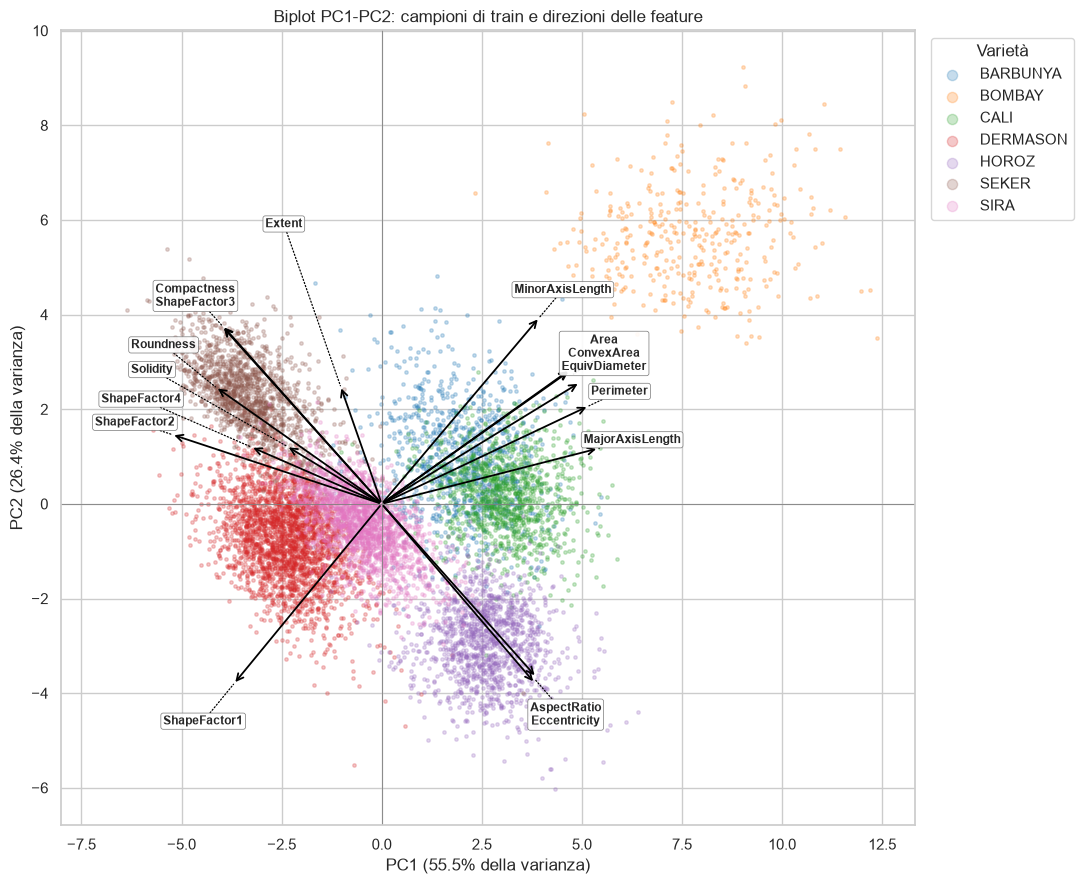

In [27]:
# le frecce sono scalate per stare dentro la nuvola di punti (solo la lunghezza cambia, non la direzione)
fattore = 0.9 * min(-Z_train[:, 0].min(), -Z_train[:, 1].min()) / np.abs(loadings[:, :2]).max()
punte = loadings[:, :2] * fattore

# feature con frecce quasi coincidenti (es. Area e ConvexArea) condividono un'unica etichetta
gruppi = []
for i in range(len(FEATURES)):
    for g in gruppi:
        if np.linalg.norm(loadings[i, :2] - loadings[g[0], :2]) < 0.10:
            g.append(i)
            break
    else:
        gruppi.append([i])

fig, ax = plt.subplots(figsize=(11, 9))
for k, nome in enumerate(NOMI_CLASSI):
    m = y_train == k
    ax.scatter(Z_train[m, 0], Z_train[m, 1], s=6, alpha=0.25, color=COLORI_CLASSI[k], label=nome)
for i in range(len(FEATURES)):
    ax.annotate("", xy=punte[i], xytext=(0, 0), arrowprops={"arrowstyle": "->", "color": "black", "lw": 1.3})
# posizione delle etichette: su una circonferenza che circonda tutte le punte, nella direzione di ciascuna
# freccia (la linea guida tratteggiata ne è il prolungamento). Se due etichette si sovrappongono le si
# allontana a vicenda lungo la circonferenza, quindi ogni etichetta resta sulla direzione della propria freccia
raggio_et = 6.4
larg_et, alt_riga = 2.3, 0.32          # ingombro approssimato di un'etichetta, in unità dei dati
etichette_biplot = []
for g in gruppi:
    p = punte[g].mean(axis=0)
    etichette_biplot.append({"testo": "\n".join(FEATURES[i] for i in g), "punta": p,
                             "pos": raggio_et * p / np.linalg.norm(p), "righe": len(g)})
for _ in range(500):
    for a, b in itertools.combinations(etichette_biplot, 2):
        d = a["pos"] - b["pos"]
        sov_x = larg_et - abs(d[0])
        sov_y = alt_riga * (a["righe"] + b["righe"]) / 2 + 0.08 - abs(d[1])
        if sov_x > 0 and sov_y > 0:      # sovrapposte: si separano lungo la circonferenza
            tang = np.array([-a["pos"][1], a["pos"][0]]) / raggio_et
            verso = np.sign(d @ tang) or 1.0
            a["pos"] = a["pos"] + verso * 0.1 * tang
            b["pos"] = b["pos"] - verso * 0.1 * tang
    for e in etichette_biplot:           # si riporta ogni etichetta sulla circonferenza
        e["pos"] = raggio_et * e["pos"] / np.linalg.norm(e["pos"])
for e in etichette_biplot:
    ax.annotate(e["testo"], xy=e["punta"], xytext=e["pos"], fontsize=8.5, ha="center", va="center",
                fontweight="bold", zorder=5,
                bbox={"boxstyle": "round,pad=0.2", "fc": "white", "ec": "dimgrey", "lw": 0.5, "alpha": 0.9},
                arrowprops={"arrowstyle": "-", "color": "black", "lw": 0.9, "ls": ":", "shrinkA": 0, "shrinkB": 0})
ax.axhline(0, color="grey", lw=0.6)
ax.axvline(0, color="grey", lw=0.6)
ax.set_xlabel(f"PC1 ({varianza_spiegata[0] * 100:.1f}% della varianza)")
ax.set_ylabel(f"PC2 ({varianza_spiegata[1] * 100:.1f}% della varianza)")
ax.set_xlim(left=-8)
ax.set_title("Biplot PC1-PC2: campioni di train e direzioni delle feature")
ax.legend(title="Varietà", markerscale=3, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
salva_figura(fig, "03_pca_biplot")
plt.show()

**Lettura del biplot.** Le frecce confermano l'interpretazione dei loadings:
- `Area`, `ConvexArea`, `EquivDiameter`, `Perimeter`, `MajorAxisLength` e `MinorAxisLength` puntano tutte verso
  destra/alto: sono correlate tra loro e crescono verso *Bombay*, il gruppo dei semi grandi;
- `AspectRatio` ed `Eccentricity` puntano in basso a destra, verso *Horoz* (i semi più allungati), mentre
  `Compactness` e `ShapeFactor3` puntano nella direzione opposta, in alto a sinistra, verso *Seker* (i più tondi);
- `Roundness`, `Solidity` e `ShapeFactor4` puntano a sinistra, verso la zona di *Seker*; `ShapeFactor2` punta a
  sinistra, in direzione opposta alle feature di dimensione, e `ShapeFactor1` in basso a sinistra, opposta a quelle
  di taglia e larghezza;
- `Extent` ha una freccia corta e quasi verticale: è poco rappresentata nel piano PC1-PC2, coerentemente con il fatto
  che il suo contributo principale è su PC4.

Frecce quasi sovrapposte (`Area`/`ConvexArea`/`EquivDiameter`, `AspectRatio`/`Eccentricity`,
`Compactness`/`ShapeFactor3`) corrispondono a feature fortemente correlate (alcune di queste coppie sono tra
quelle con |r| > 0,95 viste nell'EDA), cioè a informazione ridondante.

### 3.7 Confronto extra: Logistic Regression con e senza PCA
Per valutare quanta informazione utile si perde riducendo le dimensioni, si addestra una **Logistic Regression** su
tre rappresentazioni: le 16 feature standardizzate, le prime `n_comp_95` componenti (PCA fittata sul train) e, per
riferimento, le prime 2 componenti. Il confronto è fatto sul **validation set**: il test set resta riservato alla
valutazione finale dei modelli (sezioni successive). Il modello usa gli iperparametri di default, senza tuning, perché
lo scopo è confrontare le rappresentazioni e non ottenere il miglior risultato.

In [28]:
# Confronto sul VALIDATION set (il test non viene toccato): Logistic Regression su
#  - tutte le 16 feature standardizzate,
#  - le prime n_comp_95 componenti principali (PCA fittata sul train),
#  - le prime 2 componenti (solo per riferimento).
def confronta_lr(nome, Xtr, Xva):
    modello = LogisticRegression(max_iter=5000, random_state=SEED)
    modello.fit(Xtr, y_train)
    pred = modello.predict(Xva)
    return {"Rappresentazione": nome, "N. variabili": Xtr.shape[1],
            "Accuracy (val)": accuracy_score(y_val, pred),
            "F1 macro (val)": f1_score(y_val, pred, average="macro")}


confronto_pca = pd.DataFrame([
    confronta_lr("Feature standardizzate complete", X_train_s, X_val_s),
    confronta_lr(f"Prime {n_comp_95} componenti (95% varianza)", Z_train[:, :n_comp_95], Z_val[:, :n_comp_95]),
    confronta_lr("Prime 2 componenti", Z_train[:, :2], Z_val[:, :2]),
]).set_index("Rappresentazione")
confronto_pca

,N. variabili,Accuracy (val),F1 macro (val)
Rappresentazione,,,
Feature standardizzate complete,16,0.9202,0.9302
Prime 4 componenti (95% varianza),4,0.8897,0.8917
Prime 2 componenti,2,0.8730,0.8703


**Commento.** Sul validation set la regressione logistica sulle 16 feature standardizzate raggiunge un'accuracy di
0,920 e un F1 macro di 0,930. Con le prime 4 componenti (95,1% della varianza) i valori scendono a 0,890 e 0,892,
cioè **-3,1 punti di accuracy e -3,9 di F1 macro** a fronte di una riduzione da 16 a 4 variabili. Con sole 2
componenti si ottengono 0,873 e 0,870.

La PCA conserva la varianza ma non necessariamente l'informazione utile a distinguere le classi: le componenti
scartate hanno poca varianza, e tuttavia una parte del segnale discriminante (ad esempio le differenze sottili
tra *Dermason* e *Sira*) può trovarsi proprio lì. D'altra parte il risultato è notevole: con 2 componenti,
l'82% della varianza, si riconosce correttamente l'87% dei campioni di validation, a conferma della buona
separabilità visibile negli scatter plot. Il confronto è condotto con un solo modello e un solo split: non si
deve quindi dare alla differenza più peso di quello di un'indicazione.

### 3.8 Sintesi del Task 1
- Le 16 feature, fortemente ridondanti, sono riassunte da **4 componenti principali** che spiegano il 95,1% della
  varianza (`n_comp_95 = 4`); PC1 e PC2 da sole l'81,9%.
- **PC1** rappresenta soprattutto la dimensione del seme (con una quota di forma), **PC2** la forma
  (tondeggiante contro allungato), **PC3** la convessità del contorno e **PC4** il riempimento del rettangolo
  di inviluppo (`Extent`).
- Le varietà *Bombay*, *Seker* e *Horoz* si separano bene già nel piano PC1-PC2, mentre *Dermason*/*Sira* e
  *Barbunya*/*Cali* si sovrappongono: sono le coppie candidate agli errori di classificazione.
- La PCA ha qui scopo di **analisi e visualizzazione**: i classificatori delle sezioni successive usano tutte le
  16 feature standardizzate, perché il confronto extra mostra che ridurre a 4 componenti fa perdere qualche punto
  di accuracy.

Variabili esposte alle sezioni successive: `pca_completa`, `n_comp_95`, `varianza_spiegata` e, in più, `pca_manuale`
(l'implementazione manuale della sezione 3.2).

## 4. Task 2 – Classificatori shallow
Si confrontano cinque classificatori "classici" del corso, tutti addestrati sulle feature
**standardizzate** (`X_train_s`, `X_val_s`, `X_test_s`) e sullo stesso split della sezione 2:

1. **Logistic Regression** – modello lineare che stima le probabilità di classe con la funzione softmax;
   il parametro `C` è l'inverso della regolarizzazione L2 (valori piccoli = modello più vincolato).
2. **K-Nearest Neighbors (KNN)** – classifica un campione in base alle classi dei suoi *k* vicini più prossimi
   nello spazio delle feature; si regolano il numero di vicini e il peso dato ai vicini (uniforme o inversamente
   proporzionale alla distanza). Richiede feature sulla stessa scala, per questo si usano quelle standardizzate.
3. **SVM con kernel RBF** – cerca l'iperpiano a margine massimo in uno spazio trasformato dal kernel gaussiano,
   ottenendo confini di decisione non lineari; `C` regola la penalità sugli errori, `gamma` l'ampiezza del kernel
   (gamma grande = confini molto locali, a rischio di sovradattamento).
4. **Decision Tree** – partiziona lo spazio con una sequenza di soglie sulle singole feature; profondità massima
   e numero minimo di campioni per foglia controllano la complessità e quindi l'overfitting.
5. **Random Forest** – insieme di alberi addestrati su campioni *bootstrap* e su sottoinsiemi casuali di feature;
   la media dei voti riduce la varianza del singolo albero.

**Protocollo di scelta degli iperparametri.** Per ogni modello si definisce una piccola griglia di configurazioni.
Ognuna viene **addestrata sul train e valutata sul validation** con l'**F1 macro**, scelta perché le classi sono
sbilanciate (Bombay è circa il 4% dei campioni, Dermason il 26%) e la macro-media dà lo stesso peso a tutte.
La configurazione con F1 macro di validation più alta viene poi **riaddestrata sul solo train**: il test set non
interviene in nessuna scelta ed è usato soltanto nella sezione 5. Le griglie sono volutamente contenute
(poche decine di configurazioni in tutto) per mantenere tempi di esecuzione ragionevoli; per la SVM, durante il
tuning, si disattiva il calcolo delle probabilità (`probability=False`), che richiede una cross-validation
interna e rallenta molto l'addestramento, e lo si attiva solo nel modello finale (servono per la ROC).

In [29]:
import time
import itertools

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Per ogni modello: classe, parametri fissi, parametri fissi solo per il tuning, griglia da esplorare
CONFIGURAZIONI_SHALLOW = {
    "Logistic Regression": {
        "classe": LogisticRegression,
        "fissi": {"max_iter": 2000, "random_state": SEED},
        "tuning": {},
        "griglia": {"C": [0.01, 0.1, 1, 10, 100]},
    },
    "KNN": {
        "classe": KNeighborsClassifier,
        "fissi": {"n_jobs": -1},
        "tuning": {},
        "griglia": {"n_neighbors": [3, 5, 7, 11, 15, 21], "weights": ["uniform", "distance"]},
    },
    "SVM (RBF)": {
        "classe": SVC,
        "fissi": {"kernel": "rbf", "random_state": SEED},
        "tuning": {"probability": False},
        "griglia": {"C": [1, 10, 100], "gamma": ["scale", 0.01, 0.1]},
    },
    "Decision Tree": {
        "classe": DecisionTreeClassifier,
        "fissi": {"random_state": SEED},
        "tuning": {},
        "griglia": {"max_depth": [3, 5, 8, 12, None], "min_samples_leaf": [1, 5, 10]},
    },
    "Random Forest": {
        "classe": RandomForestClassifier,
        "fissi": {"random_state": SEED, "n_jobs": -1},
        "tuning": {},
        "griglia": {"n_estimators": [100, 300], "max_depth": [10, 20, None], "min_samples_leaf": [1, 3]},
    },
}

for nome, conf in CONFIGURAZIONI_SHALLOW.items():
    n_conf = int(np.prod([len(v) for v in conf["griglia"].values()]))
    print(f"{nome:20s} {n_conf:2d} configurazioni  ->  {conf['griglia']}")

Logistic Regression   5 configurazioni  ->  {'C': [0.01, 0.1, 1, 10, 100]}
KNN                  12 configurazioni  ->  {'n_neighbors': [3, 5, 7, 11, 15, 21], 'weights': ['uniform', 'distance']}
SVM (RBF)             9 configurazioni  ->  {'C': [1, 10, 100], 'gamma': ['scale', 0.01, 0.1]}
Decision Tree        15 configurazioni  ->  {'max_depth': [3, 5, 8, 12, None], 'min_samples_leaf': [1, 5, 10]}
Random Forest        12 configurazioni  ->  {'n_estimators': [100, 300], 'max_depth': [10, 20, None], 'min_samples_leaf': [1, 3]}


### 4.1 Tuning sul validation set
Per ogni configurazione si registrano F1 macro e accuracy sul validation e il tempo di addestramento.
Nessuna delle funzioni usa `X_test_s` o `y_test`.

In [30]:
def esegui_tuning(nome):
    """Addestra ogni configurazione della griglia sul train e la valuta sul validation (F1 macro)."""
    conf = CONFIGURAZIONI_SHALLOW[nome]
    chiavi = list(conf["griglia"].keys())
    righe, lista_parametri = [], []
    for valori in itertools.product(*conf["griglia"].values()):
        parametri = dict(zip(chiavi, valori))
        modello = conf["classe"](**conf["fissi"], **conf["tuning"], **parametri)
        t0 = time.perf_counter()
        modello.fit(X_train_s, y_train)
        durata = time.perf_counter() - t0
        pred_val = modello.predict(X_val_s)
        lista_parametri.append(parametri)
        righe.append({"F1 macro (val)": f1_score(y_val, pred_val, average="macro"),
                      "Accuracy (val)": accuracy_score(y_val, pred_val),
                      "Tempo fit (s)": durata})
    # colonne dei parametri come 'object', così interi e None restano tali (niente 3.0 / NaN)
    tabella = pd.concat([pd.DataFrame(lista_parametri, dtype=object), pd.DataFrame(righe)], axis=1)
    ordine = tabella["F1 macro (val)"].sort_values(ascending=False, kind="stable").index
    tabella = tabella.loc[ordine].reset_index(drop=True)
    # parametri originali (con i loro tipi: pandas trasformerebbe gli interi in float se c'è None), in ordine di punteggio
    tabella.attrs["parametri"] = [lista_parametri[i] for i in ordine]
    return tabella


TABELLE_TUNING = {}
TEMPI_TUNING = {}
for nome in CONFIGURAZIONI_SHALLOW:
    t0 = time.perf_counter()
    TABELLE_TUNING[nome] = esegui_tuning(nome)
    TEMPI_TUNING[nome] = time.perf_counter() - t0
    print(f"{nome}: {len(TABELLE_TUNING[nome])} configurazioni in {TEMPI_TUNING[nome]:.1f} s")

Logistic Regression: 5 configurazioni in 0.8 s


KNN: 12 configurazioni in 0.3 s


SVM (RBF): 9 configurazioni in 4.0 s


Decision Tree: 15 configurazioni in 1.2 s


Random Forest: 12 configurazioni in 6.1 s


Risultati del tuning, modello per modello, ordinati per F1 macro di validation decrescente
(la prima riga di ogni tabella è la configurazione scelta).

In [31]:
for nome, tabella in TABELLE_TUNING.items():
    print(f"\n=== {nome} ===")
    display(tabella)


=== Logistic Regression ===


,C,F1 macro (val),Accuracy (val),Tempo fit (s)
0,100,0.9324,0.9227,0.3513
1,10,0.9319,0.9222,0.1599
2,1,0.9302,0.9202,0.0978
3,0.1,0.9273,0.9173,0.0758
4,0.01,0.9215,0.9099,0.0580



=== KNN ===


,n_neighbors,weights,F1 macro (val),Accuracy (val),Tempo fit (s)
0,15,distance,0.9336,0.9217,0.0006
1,15,uniform,0.9332,0.9212,0.0006
2,11,distance,0.9330,0.9217,0.0007
3,21,distance,0.9311,0.9188,0.0007
4,11,uniform,0.9300,0.9183,0.0006
5,21,uniform,0.9297,0.9173,0.0005
6,7,distance,0.9295,0.9173,0.0007
7,7,uniform,0.9269,0.9138,0.0006
8,5,distance,0.9263,0.9143,0.0006
9,5,uniform,0.9253,0.9124,0.0007



=== SVM (RBF) ===


,C,gamma,F1 macro (val),Accuracy (val),Tempo fit (s)
0,1,0.1,0.9395,0.9291,0.2334
1,1,scale,0.9386,0.9281,0.2244
2,100,scale,0.9385,0.9281,0.3265
3,10,scale,0.9381,0.9281,0.2185
4,10,0.01,0.9379,0.9281,0.2143
5,100,0.01,0.9373,0.9276,0.2527
6,10,0.1,0.9369,0.9271,0.2521
7,100,0.1,0.9361,0.9247,0.3715
8,1,0.01,0.9298,0.9188,0.2641



=== Decision Tree ===


,max_depth,min_samples_leaf,F1 macro (val),Accuracy (val),Tempo fit (s)
0,12,10,0.9182,0.9050,0.0931
1,None,10,0.9182,0.9050,0.1038
2,None,5,0.9154,0.9010,0.1170
3,12,1,0.9147,0.8996,0.1065
4,12,5,0.9138,0.8996,0.0975
5,8,1,0.9121,0.9010,0.0878
6,None,1,0.9117,0.8966,0.1161
7,8,5,0.9112,0.9015,0.0794
8,8,10,0.9108,0.9005,0.0819
9,5,1,0.8843,0.8799,0.0514



=== Random Forest ===


,n_estimators,max_depth,min_samples_leaf,F1 macro (val),Accuracy (val),Tempo fit (s)
0,300,None,1,0.9337,0.9217,0.7339
1,100,None,1,0.9331,0.9207,0.2627
2,300,None,3,0.9328,0.9212,0.6887
3,100,20,3,0.9325,0.9207,0.2619
4,300,20,3,0.9325,0.9207,0.6577
5,300,20,1,0.9317,0.9193,0.6896
6,100,10,3,0.9316,0.9207,0.2271
7,300,10,3,0.9316,0.9207,0.6498
8,100,20,1,0.9315,0.9193,0.2677
9,300,10,1,0.9312,0.9202,0.6995


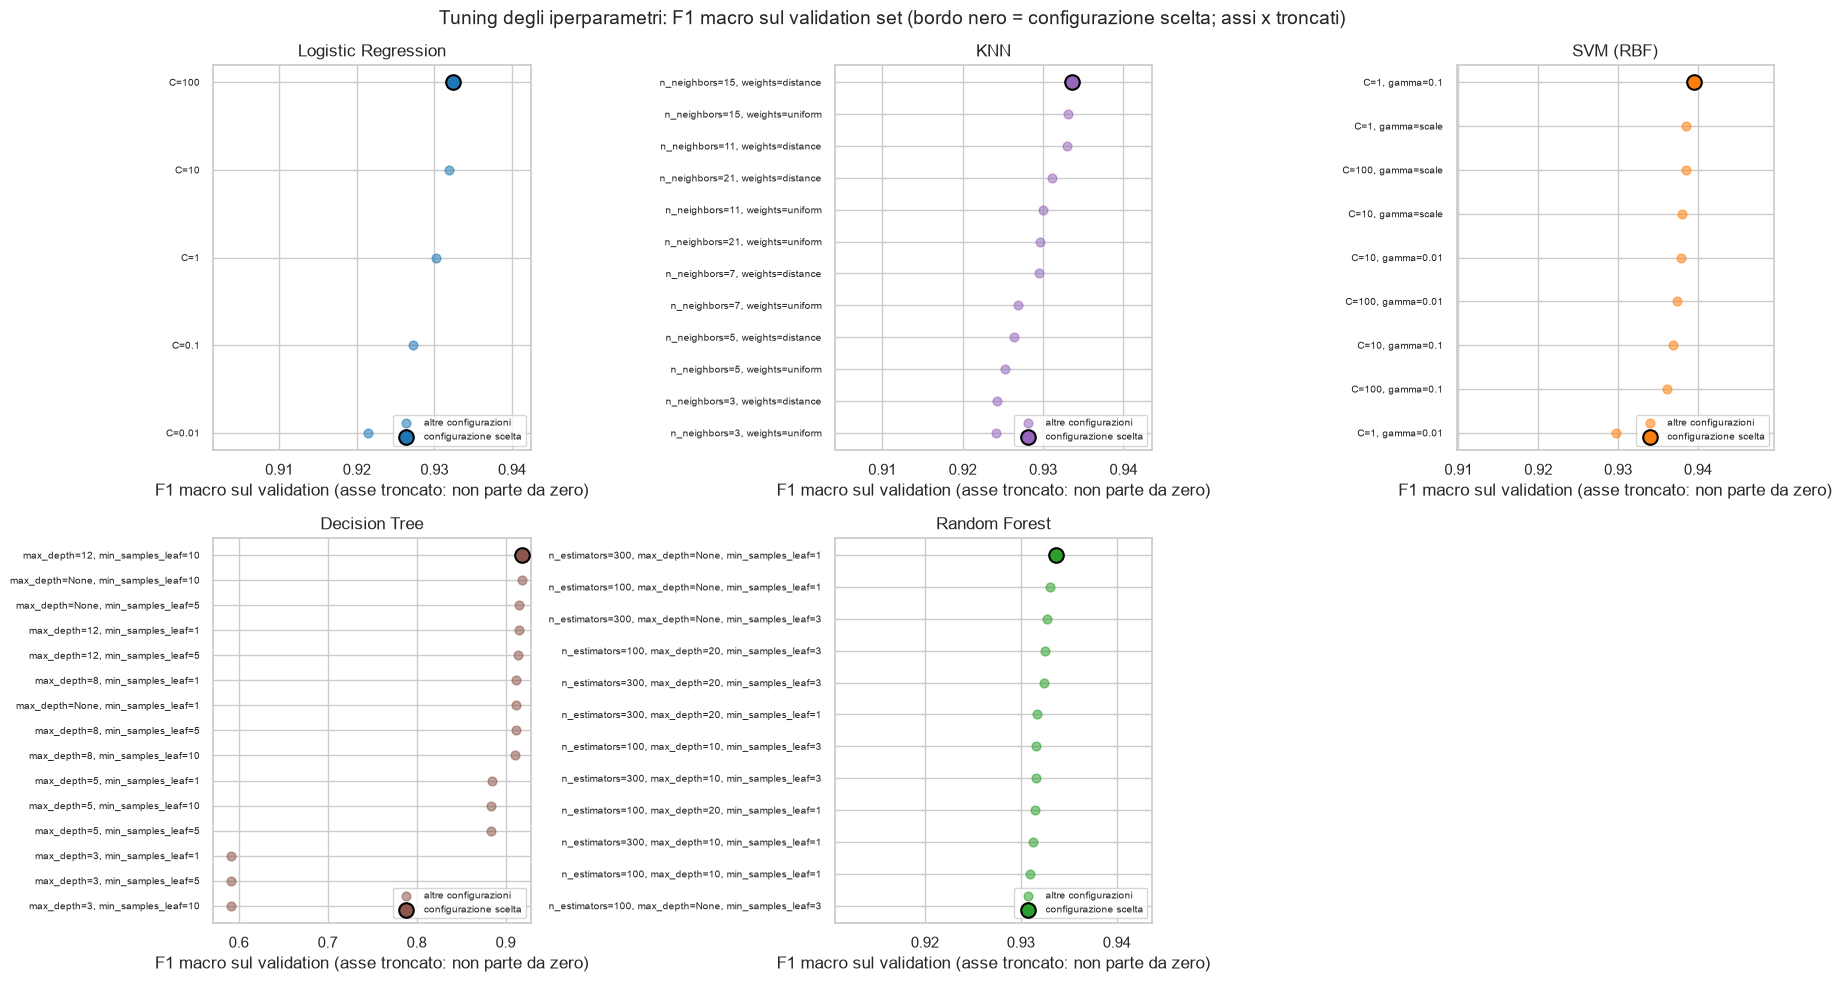

In [32]:
fig, assi = plt.subplots(2, 3, figsize=(18, 10))
assi = assi.ravel()
for ax, (nome, tabella) in zip(assi, TABELLE_TUNING.items()):
    chiavi = [c for c in tabella.columns if c not in ("F1 macro (val)", "Accuracy (val)", "Tempo fit (s)")]
    etichette = [", ".join(f"{k}={riga[k]}" for k in chiavi) for _, riga in tabella.iterrows()]
    # grafico a punti (non a barre): l'asse parte dal valore minimo e non da zero, ma i punti non esagerano le differenze
    posizioni = np.arange(len(tabella))
    punteggi = tabella["F1 macro (val)"].to_numpy()
    colore = COLORI_MODELLI[nome]
    ax.scatter(punteggi[1:], posizioni[1:], s=40, color=colore, alpha=0.55, label="altre configurazioni")
    ax.scatter(punteggi[:1], posizioni[:1], s=110, color=colore, edgecolor="black", linewidth=1.5, zorder=3,
               label="configurazione scelta")      # la prima riga è la migliore
    ax.set_yticks(posizioni)
    ax.set_yticklabels(etichette, fontsize=7)
    ax.invert_yaxis()
    ax.set_xlim(max(0, punteggi.min() - 0.02), min(1.0, punteggi.max() + 0.01))
    ax.set_xlabel("F1 macro sul validation (asse troncato: non parte da zero)")
    ax.set_title(nome)
    ax.legend(loc="lower right", fontsize=7)
for ax in assi[len(TABELLE_TUNING):]:
    ax.axis("off")
fig.suptitle("Tuning degli iperparametri: F1 macro sul validation set "
             "(bordo nero = configurazione scelta; assi x troncati)", fontsize=14)
fig.tight_layout()
salva_figura(fig, "04_tuning_validation")
plt.show()

### 4.2 Scelta della configurazione migliore e riaddestramento sul train
Per ogni modello si prende la riga con F1 macro di validation più alta (a parità di punteggio resta la prima
dell'ordinamento, quindi la scelta è deterministica).
Il modello finale è riaddestrato **soltanto sul train** con quei parametri; per la SVM, in questa fase,
`probability=True`. I migliori iperparametri sono salvati in `results/best_params.json`.

In [33]:
def a_tipo_python(valore):
    """Converte i tipi numpy/NaN in tipi serializzabili in JSON (NaN -> None)."""
    if isinstance(valore, np.generic):
        valore = valore.item()
    if isinstance(valore, float) and np.isnan(valore):
        return None
    return valore


BEST_PARAMS = {}
MODELLI_SHALLOW = {}
TEMPI_ADDESTRAMENTO = {}      # secondi di fit del modello finale sul train
riepilogo_validation = []

for nome, conf in CONFIGURAZIONI_SHALLOW.items():
    tabella = TABELLE_TUNING[nome]
    parametri = {k: a_tipo_python(v) for k, v in tabella.attrs["parametri"][0].items()}
    BEST_PARAMS[nome] = parametri

    modello = conf["classe"](**conf["fissi"], **({"probability": True} if nome == "SVM (RBF)" else {}), **parametri)
    t0 = time.perf_counter()
    modello.fit(X_train_s, y_train)
    TEMPI_ADDESTRAMENTO[nome] = time.perf_counter() - t0
    MODELLI_SHALLOW[nome] = modello

    pred_val = modello.predict(X_val_s)
    riepilogo_validation.append({
        "Modello": nome,
        "Iperparametri scelti": ", ".join(f"{k}={v}" for k, v in parametri.items()),
        "F1 macro (val)": f1_score(y_val, pred_val, average="macro"),
        "Accuracy (val)": accuracy_score(y_val, pred_val),
        "Tempo fit finale (s)": TEMPI_ADDESTRAMENTO[nome],
    })

with open(CARTELLA_RISULTATI / "best_params.json", "w", encoding="utf-8") as f:
    json.dump(BEST_PARAMS, f, ensure_ascii=False, indent=2)

riepilogo_validation = pd.DataFrame(riepilogo_validation).set_index("Modello")
print("Migliori iperparametri salvati in", CARTELLA_RISULTATI / "best_params.json")
riepilogo_validation

Migliori iperparametri salvati in results\best_params.json


,Iperparametri scelti,F1 macro (val),Accuracy (val),Tempo fit finale (s)
Modello,,,,
Logistic Regression,C=100,0.9324,0.9227,0.3435
KNN,"n_neighbors=15, weights=distance",0.9336,0.9217,0.0006
SVM (RBF),"C=1, gamma=0.1",0.9395,0.9291,1.4777
Decision Tree,"max_depth=12, min_samples_leaf=10",0.9182,0.9050,0.0995
Random Forest,"n_estimators=300, max_depth=None, min_samples_...",0.9337,0.9217,0.7008


### 4.3 Commento sul tuning
- **Differenze piccole tra le configurazioni migliori.** Per Logistic Regression, KNN, SVM e Random Forest le prime
  configurazioni della classifica differiscono per meno di due millesimi di F1 macro: la scelta dell'iperparametro
  conta poco finché non si scende in zone chiaramente sotto- o sovra-regolarizzate (ad esempio `C = 0,01` per la
  regressione logistica o `gamma = 0,01` con `C = 1` per la SVM). Con un validation di circa 2000 campioni queste
  differenze sono dello stesso ordine del rumore statistico, quindi la configurazione "migliore" va letta come una
  scelta ragionevole più che come un ottimo netto.
- **Bordi della griglia.** Alcune scelte cadono sul bordo della griglia (Logistic Regression con `C = 100`, valore più
  alto provato; SVM con `C = 1`, il più basso, e `gamma = 0,1`, il più alto). Il guadagno rispetto alla seconda
  configurazione in classifica è però inferiore a un decimo di punto di F1 macro: +0,05 punti per la regressione
  logistica (0,9324 con `C = 100` contro 0,9319 con `C = 10`) e +0,09 punti per la SVM (0,9395 contro 0,9386 con
  `gamma = 'scale'`). Per questo non si è ritenuto utile ampliare la griglia a scapito dei tempi.
- **Decision Tree.** È il modello più sensibile: con `max_depth = 3` l'albero non ha foglie a sufficienza per
  rappresentare le 7 classi (F1 macro 0,59 e accuracy 0,77 sul validation); da profondità 8 in su le prestazioni si
  stabilizzano intorno a 0,91-0,92. Con profondità 12 o illimitata le foglie di almeno 10 campioni sono la scelta
  migliore (0,9182, contro 0,9154 al massimo con foglie da 5 e 0,9147 al massimo con foglie da 1: circa 0,3 punti di
  vantaggio, forse grazie a un po' meno overfitting), mentre a profondità 8 non c'è alcun vantaggio: le foglie da 10
  sono anzi le ultime (0,9108 contro 0,9121 con foglie da 1).
  Il pareggio tra `max_depth = 12` e `max_depth = None` con `min_samples_leaf = 10` è risolto dall'ordine della griglia.
- **Ranking sul validation** (F1 macro): SVM (0,9395) > Random Forest (0,9337) ≈ KNN (0,9336) > Logistic Regression
  (0,9324) > Decision Tree (0,9182). La valutazione definitiva su dati mai visti è nella sezione 5.

## 5. Task 3 e 4 – Metriche, matrici di confusione e curve ROC
I cinque modelli scelti nella sezione 4 sono valutati **una sola volta sul test set** (`X_test_s`, `y_test`),
mai usato finora per decisioni di modello. Le metriche calcolate da `valuta_modello` sono:

- **accuracy**: frazione di campioni classificati correttamente;
- **precision**, **recall** ed **F1** (*F-measure*) in media **macro** (media semplice sulle 7 classi, ogni classe pesa
  uguale) e **weighted** (pesata per il numero di campioni di ciascuna classe);
- **ROC AUC** *one-vs-rest* in media macro, calcolata sulle probabilità predette.

Seguono il `classification_report` per classe, le matrici di confusione (conteggi e normalizzate per riga) e le curve
ROC *one-vs-rest* per ogni classe con media micro e macro.

In [34]:
from sklearn.metrics import classification_report

PREVISIONI_SHALLOW = {}     # nome modello -> (y_pred, y_proba) sul test
metriche_modelli = []
for nome, modello in MODELLI_SHALLOW.items():
    y_pred = modello.predict(X_test_s)
    y_proba = modello.predict_proba(X_test_s)
    PREVISIONI_SHALLOW[nome] = (y_pred, y_proba)
    metriche_modelli.append(valuta_modello(nome, y_test, y_pred, y_proba))

tabella_shallow = pd.DataFrame(metriche_modelli)
tabella_shallow.index.name = "Modello"
print("Metriche sul test set (2032 campioni)")
tabella_shallow

Metriche sul test set (2032 campioni)


,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),ROC AUC (OvR macro)
Modello,,,,,,,,
Logistic Regression,0.9222,0.9353,0.9360,0.9355,0.9227,0.9222,0.9224,0.9944
KNN,0.9158,0.9310,0.9284,0.9295,0.9166,0.9158,0.9161,0.9911
SVM (RBF),0.9213,0.9356,0.9345,0.9350,0.9215,0.9213,0.9214,0.9943
Decision Tree,0.9011,0.9165,0.9108,0.9135,0.9010,0.9011,0.9009,0.9754
Random Forest,0.9178,0.9300,0.9309,0.9304,0.9177,0.9178,0.9177,0.9931


### 5.1 Report di classificazione per classe
Precision, recall, F1 e numero di campioni di test (*support*) per ciascuna varietà, per ogni modello.

In [35]:
REPORT_PER_CLASSE = {}
for nome, (y_pred, _) in PREVISIONI_SHALLOW.items():
    rep = classification_report(y_test, y_pred, target_names=NOMI_CLASSI, digits=4, output_dict=True, zero_division=0)
    REPORT_PER_CLASSE[nome] = pd.DataFrame(rep).T
    print(f"\n=== {nome} ===")
    print(classification_report(y_test, y_pred, target_names=NOMI_CLASSI, digits=4, zero_division=0))

# F1 per classe di tutti i modelli, a confronto
f1_per_classe = pd.DataFrame({nome: rep.loc[NOMI_CLASSI, "f1-score"] for nome, rep in REPORT_PER_CLASSE.items()})
print("F1 per classe sul test")
f1_per_classe


=== Logistic Regression ===
              precision    recall  f1-score   support

    BARBUNYA     0.9340    0.9293    0.9316       198
      BOMBAY     1.0000    1.0000    1.0000        78
        CALI     0.9385    0.9347    0.9366       245
    DERMASON     0.9226    0.8966    0.9094       532
       HOROZ     0.9534    0.9534    0.9534       279
       SEKER     0.9446    0.9539    0.9493       304
        SIRA     0.8537    0.8838    0.8685       396

    accuracy                         0.9222      2032
   macro avg     0.9353    0.9360    0.9355      2032
weighted avg     0.9227    0.9222    0.9224      2032


=== KNN ===
              precision    recall  f1-score   support

    BARBUNYA     0.9468    0.8990    0.9223       198
      BOMBAY     1.0000    1.0000    1.0000        78
        CALI     0.9197    0.9347    0.9271       245
    DERMASON     0.9140    0.8985    0.9062       532
       HOROZ     0.9462    0.9462    0.9462       279
       SEKER     0.9503    0.9441   

,Logistic Regression,KNN,SVM (RBF),Decision Tree,Random Forest
BARBUNYA,0.9316,0.9223,0.9309,0.8969,0.9200
BOMBAY,1.0000,1.0000,1.0000,0.9870,1.0000
CALI,0.9366,0.9271,0.9429,0.9095,0.9237
DERMASON,0.9094,0.9062,0.9074,0.8994,0.9087
HOROZ,0.9534,0.9462,0.9500,0.9372,0.9498
SEKER,0.9493,0.9472,0.9474,0.9294,0.9462
SIRA,0.8685,0.8578,0.8664,0.8351,0.8644


### 5.2 Matrici di confusione
Per ogni modello: a sinistra i conteggi assoluti, a destra i valori normalizzati per riga, cioè la frazione dei
campioni di ciascuna classe reale assegnata a ogni classe predetta (la diagonale è la recall per classe).

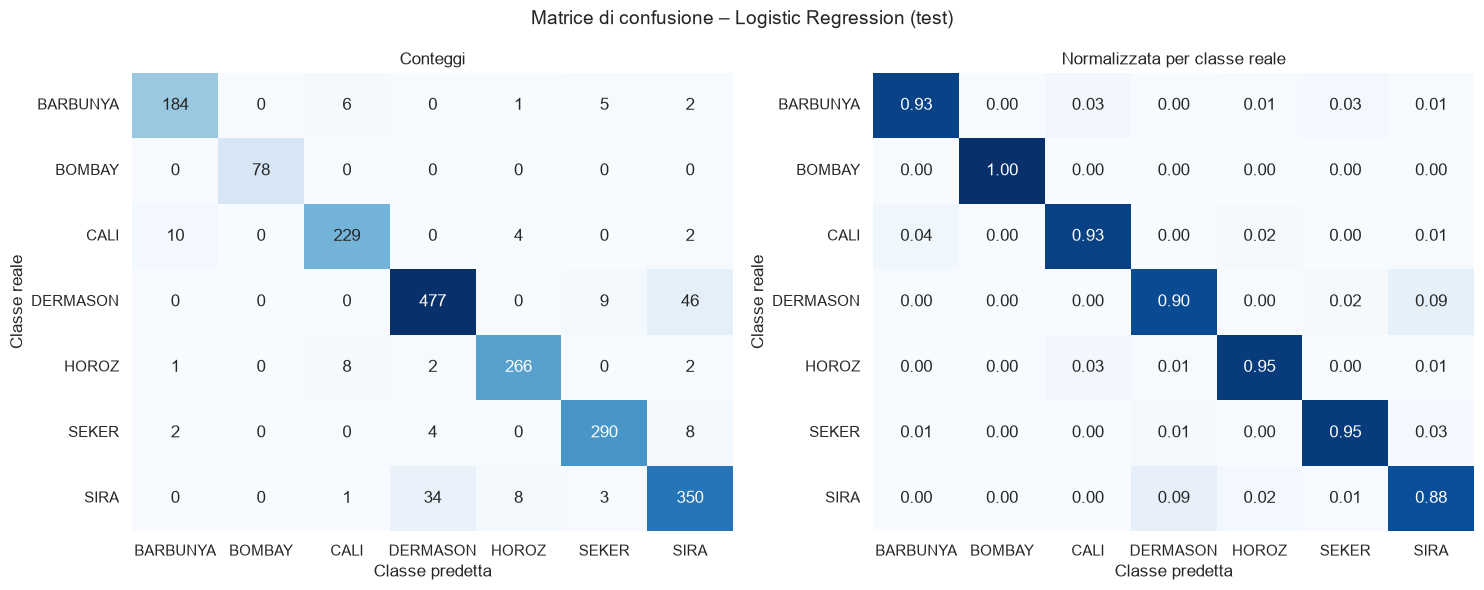

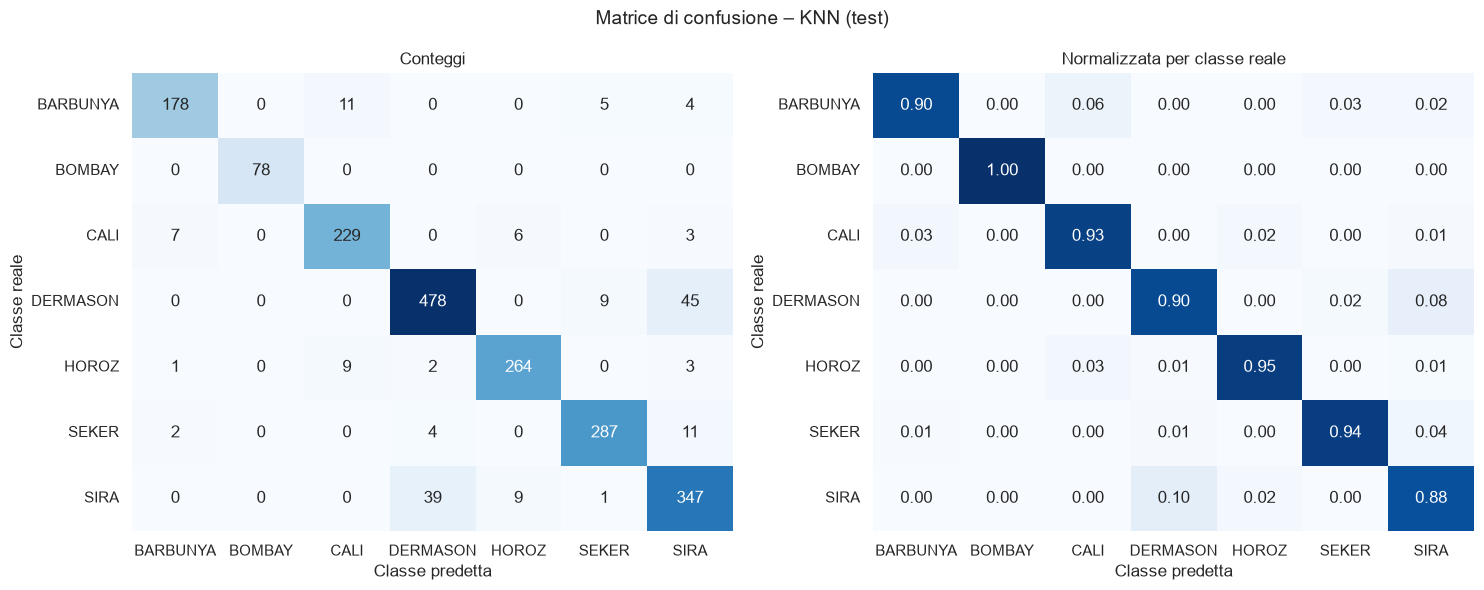

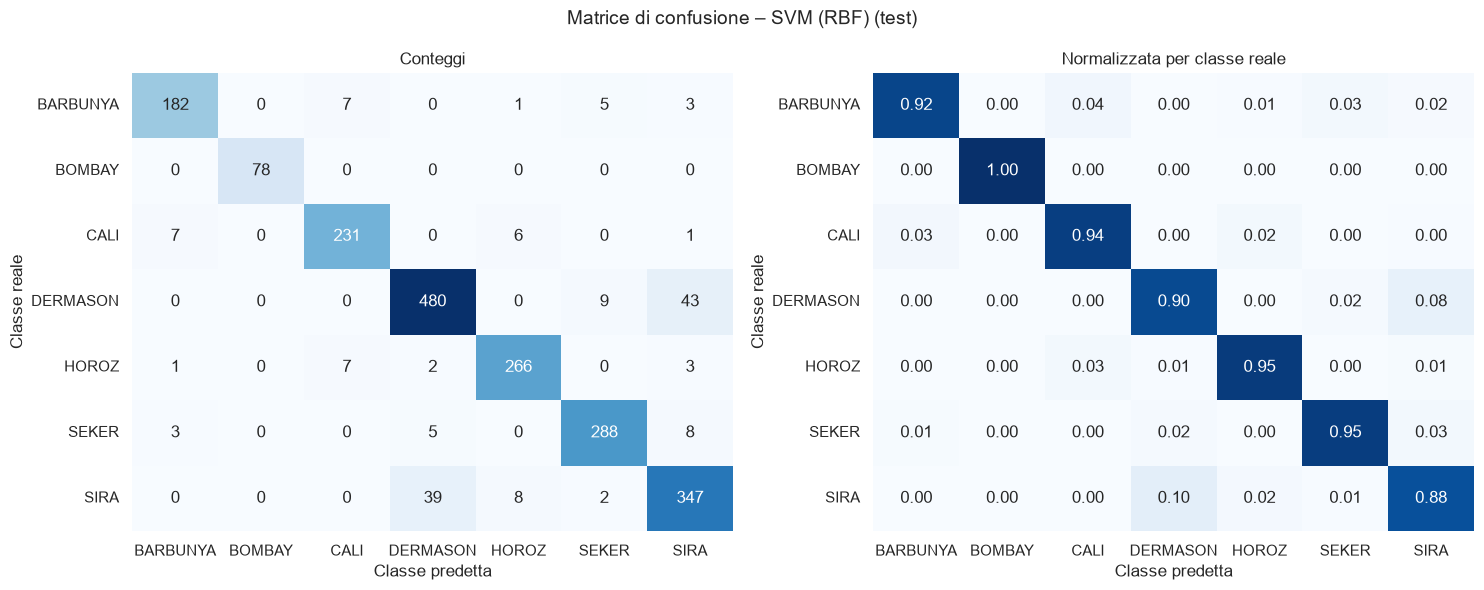

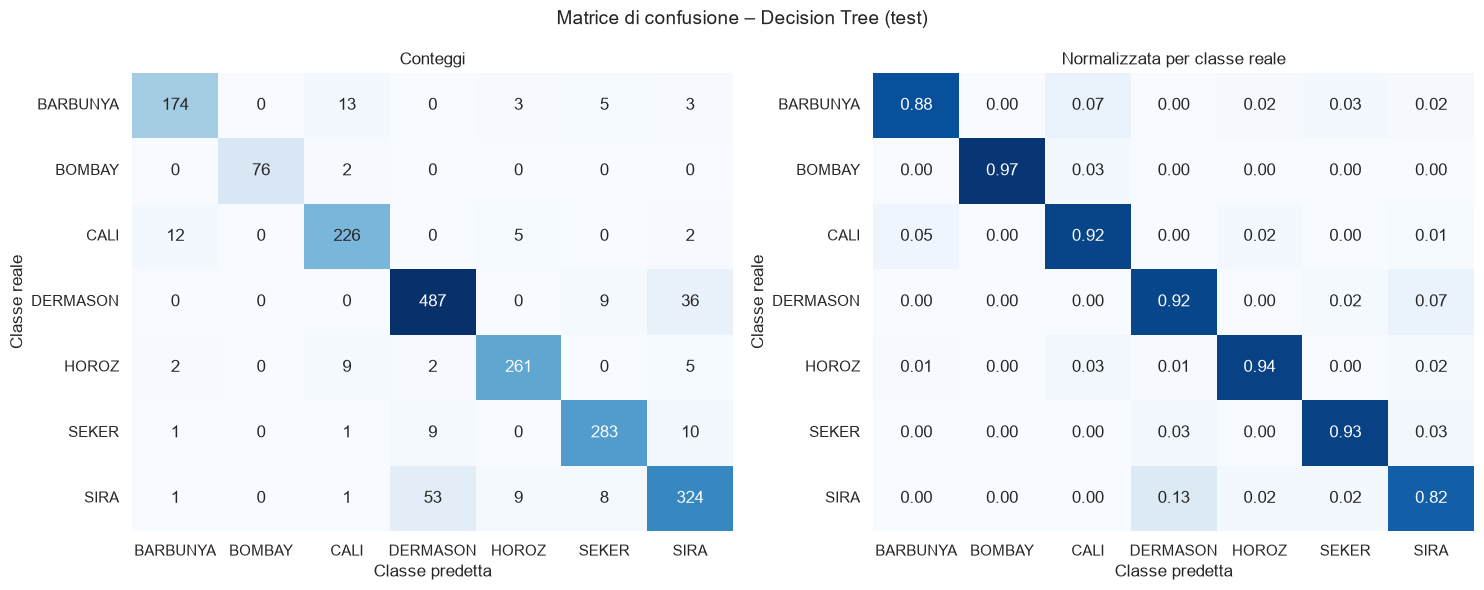

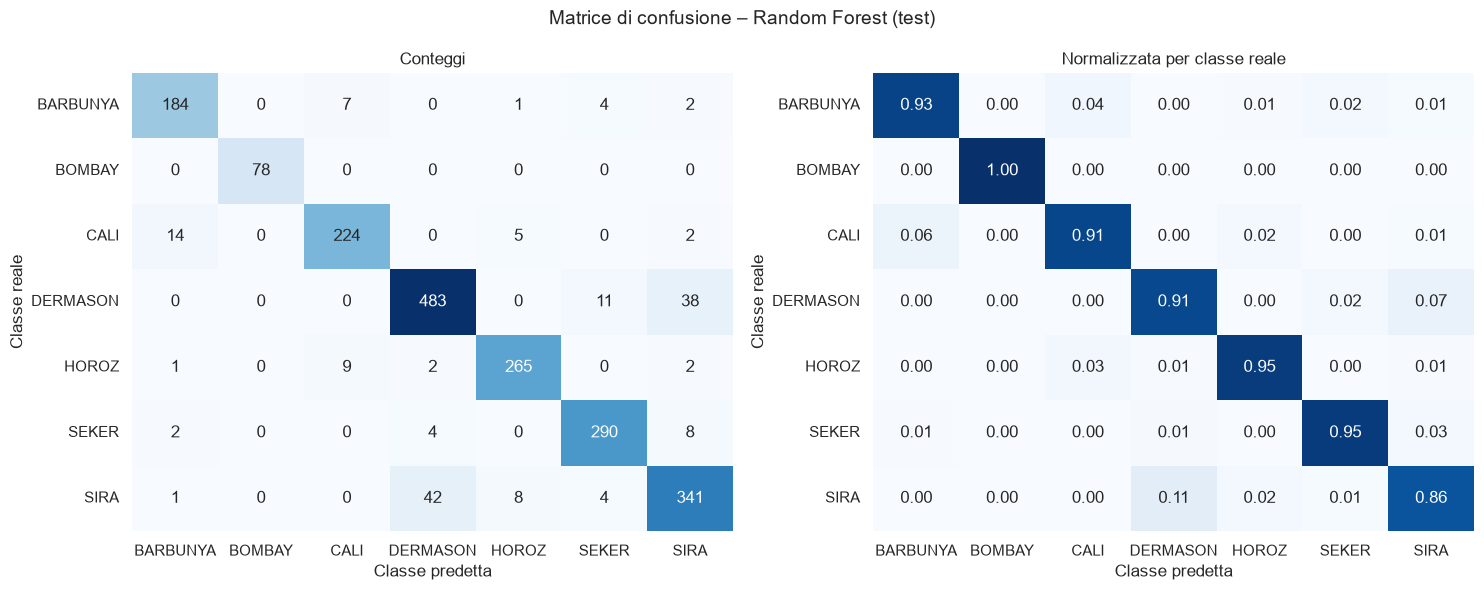

In [36]:
SLUG_MODELLI = {
    "Logistic Regression": "logistic_regression",
    "KNN": "knn",
    "SVM (RBF)": "svm_rbf",
    "Decision Tree": "decision_tree",
    "Random Forest": "random_forest",
}
MATRICI_CONFUSIONE = {}
for nome, (y_pred, _) in PREVISIONI_SHALLOW.items():
    MATRICI_CONFUSIONE[nome] = plot_confusion(
        y_test, y_pred, NOMI_CLASSI, f"Matrice di confusione – {nome} (test)", f"05_cm_{SLUG_MODELLI[nome]}")

### 5.3 Curve ROC one-vs-rest
Per ogni classe si considera "quella classe contro tutte le altre" e si traccia TPR in funzione di FPR al variare
della soglia sulla probabilità. Le medie **micro** (tutte le coppie campione-classe insieme) e **macro**
(media delle curve di classe) riassumono il comportamento complessivo.

**Due valori per la ROC AUC macro.** La ROC AUC della prima tabella della sezione (`roc_auc_score`) è la media delle
7 AUC *one-vs-rest*, ciascuna calcolata sulla curva esatta di quella classe. L'AUC "Media macro" della tabella qui
sotto e delle legende dei grafici è invece l'area sotto la curva macro, ottenuta interpolando le 7 curve su una
griglia comune di 1000 valori di FPR e mediandole punto per punto: è un'approssimazione, per cui i due numeri non
coincidono esattamente.
La differenza è piccola (da 0,0001 a 0,0003 sui cinque modelli; per la regressione logistica 0,9944 contro 0,9941).
Nel commento e nella tabella riepilogativa si usa il valore di `roc_auc_score`.

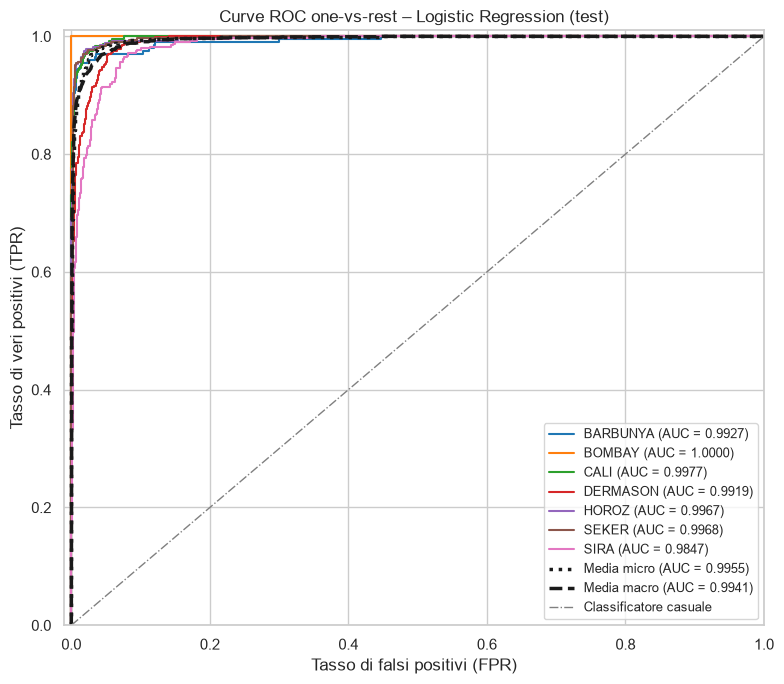

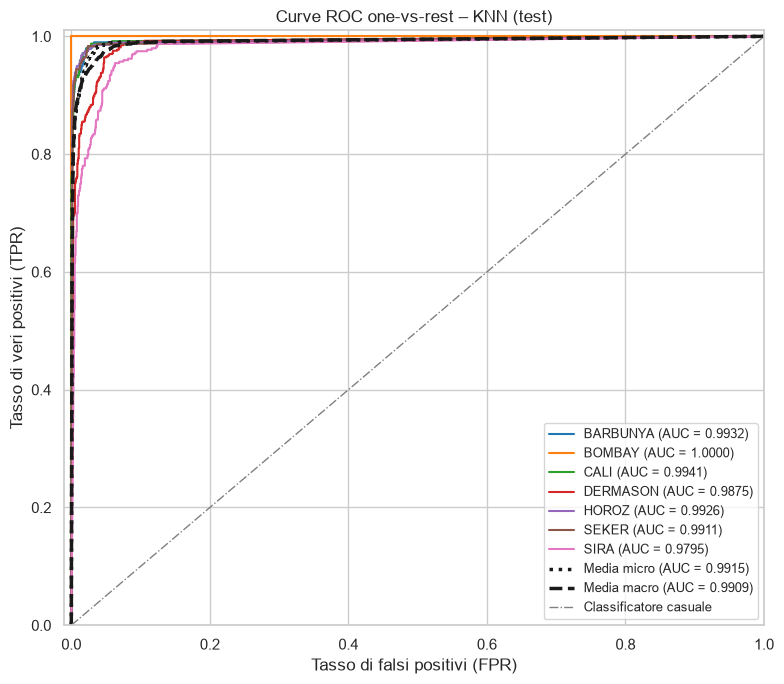

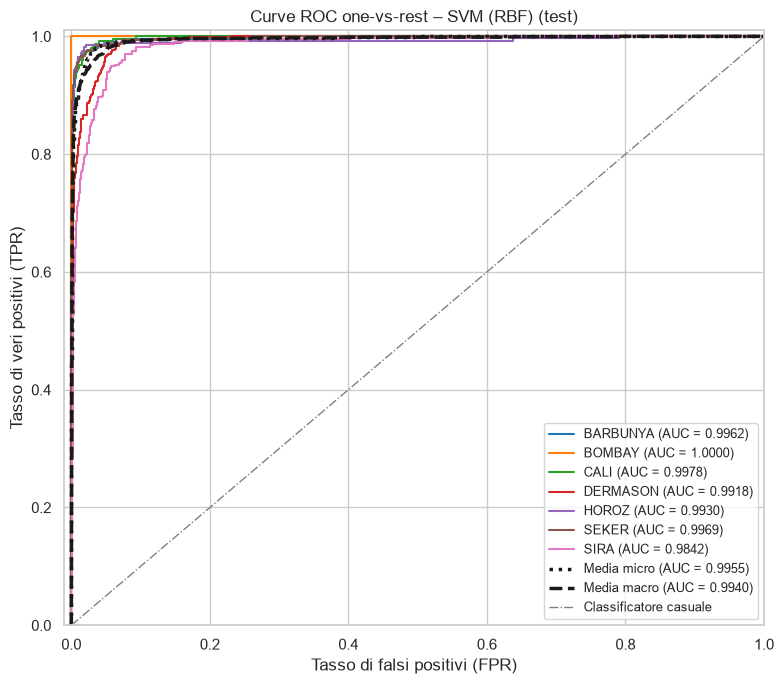

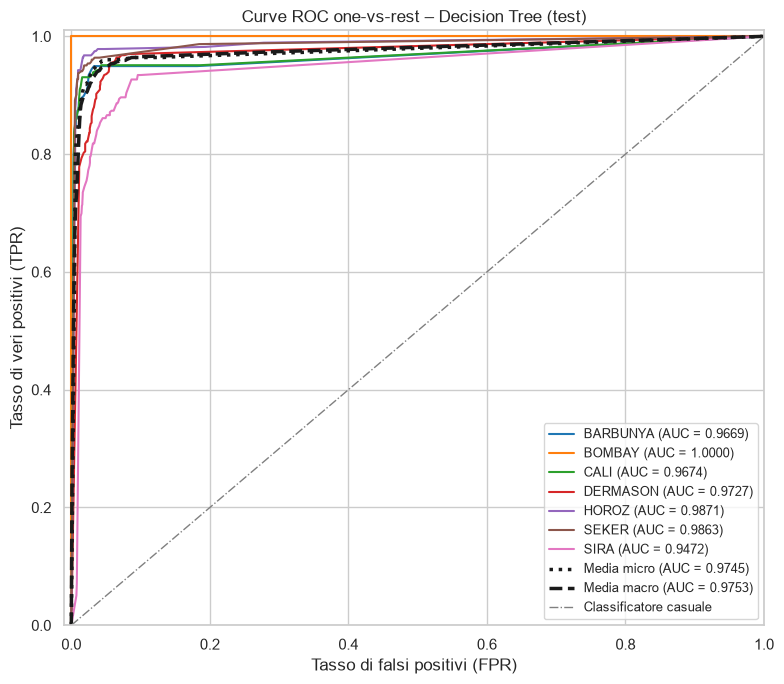

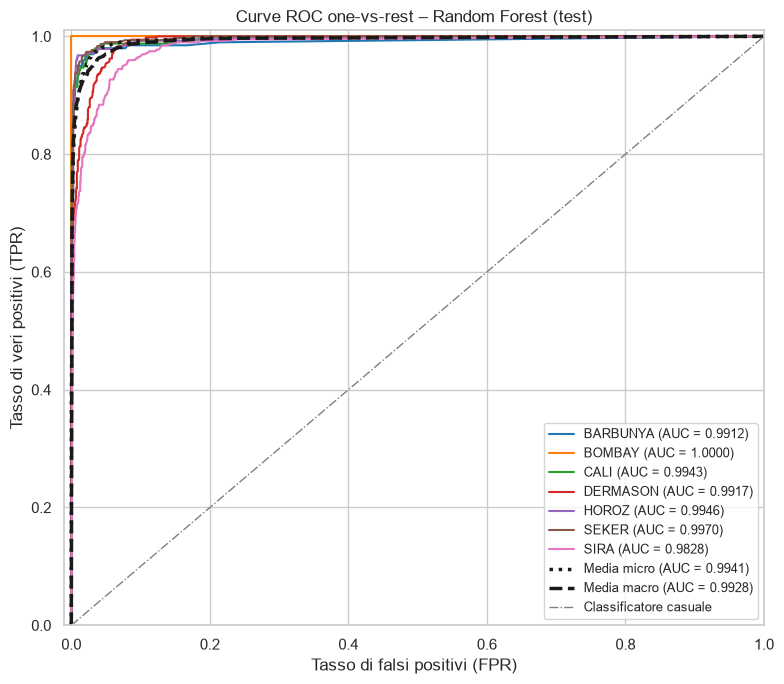

AUC delle curve ROC sul test, per classe e in media


,Logistic Regression,KNN,SVM (RBF),Decision Tree,Random Forest
BARBUNYA,0.9927,0.9932,0.9962,0.9669,0.9912
BOMBAY,1.0000,1.0000,1.0000,1.0000,1.0000
CALI,0.9977,0.9941,0.9978,0.9674,0.9943
DERMASON,0.9919,0.9875,0.9918,0.9727,0.9917
HOROZ,0.9967,0.9926,0.9930,0.9871,0.9946
SEKER,0.9968,0.9911,0.9969,0.9863,0.9970
SIRA,0.9847,0.9795,0.9842,0.9472,0.9828
Media micro,0.9955,0.9915,0.9955,0.9745,0.9941
Media macro,0.9941,0.9909,0.9940,0.9753,0.9928


In [37]:
AUC_ROC = {}
for nome, (_, y_proba) in PREVISIONI_SHALLOW.items():
    AUC_ROC[nome] = plot_roc(
        y_test, y_proba, NOMI_CLASSI, f"Curve ROC one-vs-rest – {nome} (test)",
        f"05_roc_{SLUG_MODELLI[nome]}", nome_modello=nome)

auc_per_classe = pd.DataFrame({nome: pd.Series(r["auc_per_classe"]) for nome, r in AUC_ROC.items()})
auc_per_classe.index = NOMI_CLASSI
auc_per_classe.loc["Media micro"] = [r["auc_micro"] for r in AUC_ROC.values()]
auc_per_classe.loc["Media macro"] = [r["auc_macro"] for r in AUC_ROC.values()]
print("AUC delle curve ROC sul test, per classe e in media")
auc_per_classe

### 5.4 Confronto delle curve ROC macro
Le curve macro di tutti i modelli shallow nello stesso grafico; a destra un ingrandimento nella zona in alto a
sinistra, dove le curve sono quasi indistinguibili.

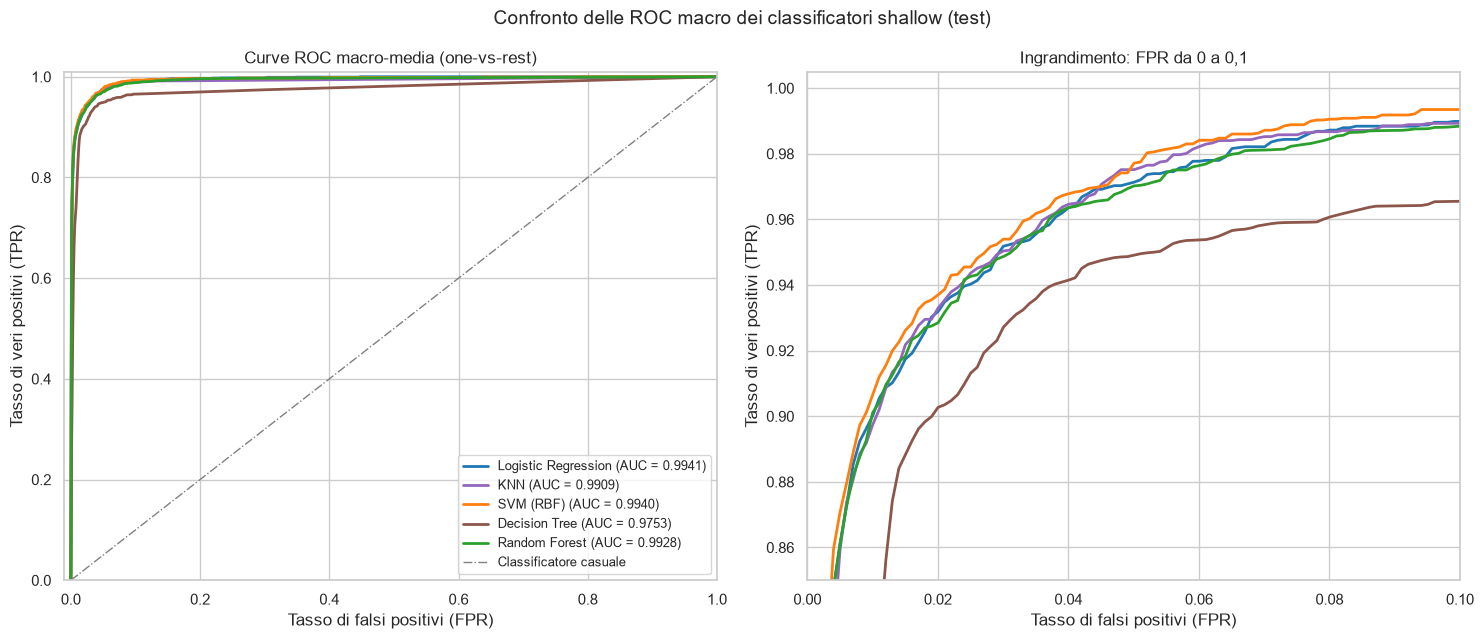

In [38]:
fig, assi = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, zoom in zip(assi, (False, True)):
    for nome in MODELLI_SHALLOW:
        fpr_m, tpr_m, auc_m = CURVE_ROC[nome]
        ax.plot(fpr_m, tpr_m, color=COLORI_MODELLI[nome], lw=2, label=f"{nome} (AUC = {auc_m:.4f})")
    if not zoom:
        ax.plot([0, 1], [0, 1], color="grey", lw=1, linestyle="-.", label="Classificatore casuale")
        ax.set_xlim(-0.01, 1.0)
        ax.set_ylim(0.0, 1.01)
        ax.set_title("Curve ROC macro-media (one-vs-rest)")
        ax.legend(loc="lower right", fontsize=9)
    else:
        ax.set_xlim(0, 0.1)
        ax.set_ylim(0.85, 1.005)
        ax.set_title("Ingrandimento: FPR da 0 a 0,1")
    ax.set_xlabel("Tasso di falsi positivi (FPR)")
    ax.set_ylabel("Tasso di veri positivi (TPR)")
fig.suptitle("Confronto delle ROC macro dei classificatori shallow (test)", fontsize=14)
fig.tight_layout()
salva_figura(fig, "05_confronto_roc")
plt.show()

### 5.5 Tabella riepilogativa e confronto delle metriche
Tutte le metriche sul test per i cinque modelli, ordinate per F1 macro, con in evidenza il valore migliore di
ciascuna colonna e il confronto grafico di accuracy, F1 macro e ROC AUC (un grafico a punti per metrica, con
l'asse orizzontale che non parte da zero, così da rendere visibili le differenze senza ingrandirle con barre troncate).

In [39]:
riepilogo_shallow = tabella_shallow.sort_values("F1 (macro)", ascending=False)
riepilogo_shallow.style.format("{:.4f}").highlight_max(axis=0, color="#cfe8cf")

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),ROC AUC (OvR macro)
Modello,,,,,,,,
Logistic Regression,0.9222,0.9353,0.9360,0.9355,0.9227,0.9222,0.9224,0.9944
SVM (RBF),0.9213,0.9356,0.9345,0.9350,0.9215,0.9213,0.9214,0.9943
Random Forest,0.9178,0.9300,0.9309,0.9304,0.9177,0.9178,0.9177,0.9931
KNN,0.9158,0.9310,0.9284,0.9295,0.9166,0.9158,0.9161,0.9911
Decision Tree,0.9011,0.9165,0.9108,0.9135,0.9010,0.9011,0.9009,0.9754


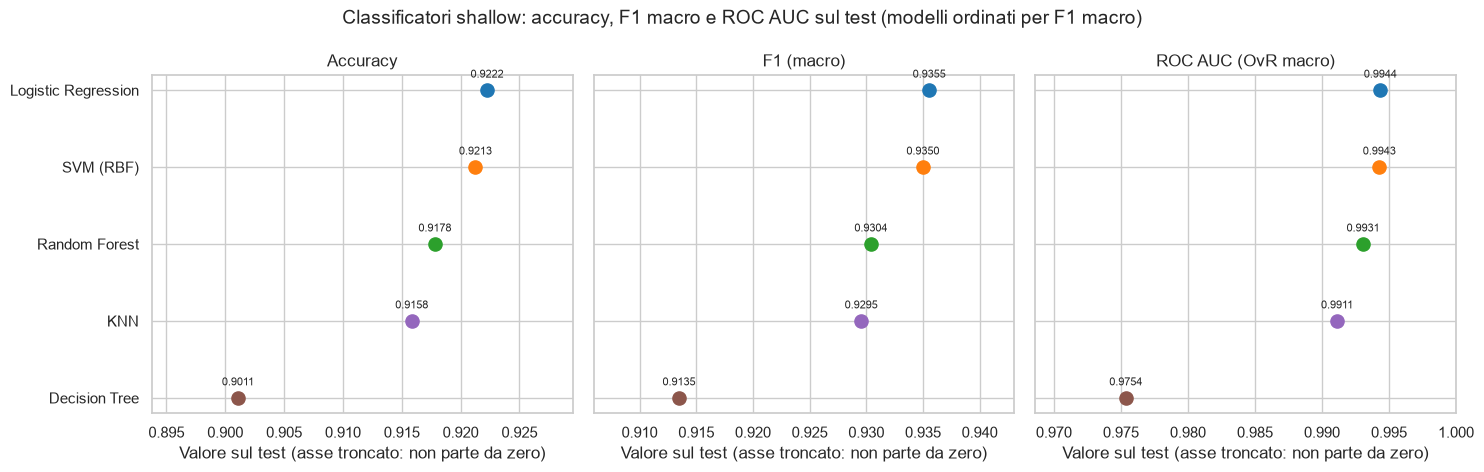

In [40]:
metriche_grafico = ["Accuracy", "F1 (macro)", "ROC AUC (OvR macro)"]
fig, assi = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
posizioni = np.arange(len(riepilogo_shallow))
for ax, metrica in zip(assi, metriche_grafico):
    valori = riepilogo_shallow[metrica].to_numpy()
    for pos, nome, valore in zip(posizioni, riepilogo_shallow.index, valori):
        ax.scatter(valore, pos, s=90, color=COLORI_MODELLI[nome], zorder=3)
        ax.annotate(f"{valore:.4f}", (valore, pos), textcoords="offset points", xytext=(0, 9),
                    ha="center", fontsize=8)
    margine = (valori.max() - valori.min()) * 0.25 + 0.002
    ax.set_xlim(valori.min() - margine, min(1.0, valori.max() + margine))      # mai oltre 1
    ax.set_title(metrica)
    ax.set_xlabel("Valore sul test (asse troncato: non parte da zero)")
assi[0].set_yticks(posizioni)
assi[0].set_yticklabels(riepilogo_shallow.index)
assi[0].invert_yaxis()
fig.suptitle("Classificatori shallow: accuracy, F1 macro e ROC AUC sul test (modelli ordinati per F1 macro)",
             fontsize=14)
fig.tight_layout()
salva_figura(fig, "05_confronto_metriche")
plt.show()

### 5.6 Classi più confuse
Dalle matrici di confusione si estraggono le coppie di classi (reale -> predetta) con più errori. Per rendere
il confronto indipendente dall'ordine, le due direzioni di errore di ogni coppia sono sommate.

In [41]:
def coppie_confuse(cm, nomi, top=5):
    """Coppie non ordinate di classi con più errori totali (somma dei due versi)."""
    righe = []
    for i in range(len(nomi)):
        for j in range(i + 1, len(nomi)):
            righe.append({"Coppia": f"{nomi[i]} - {nomi[j]}",
                          "Errori totali": int(cm[i, j] + cm[j, i]),
                          f"prima -> seconda": int(cm[i, j]),
                          f"seconda -> prima": int(cm[j, i])})
    tab = pd.DataFrame(righe).sort_values("Errori totali", ascending=False)
    return tab.head(top).reset_index(drop=True)


COPPIE_CONFUSE = {}
for nome, cm in MATRICI_CONFUSIONE.items():
    COPPIE_CONFUSE[nome] = coppie_confuse(cm, NOMI_CLASSI, top=3)
    print(f"\n=== {nome}: errori totali {int(cm.sum() - np.trace(cm))} su {int(cm.sum())} ===")
    display(COPPIE_CONFUSE[nome])

# somma degli errori per coppia su tutti e cinque i modelli
somma_confusione = sum(MATRICI_CONFUSIONE.values())
print("Coppie più confuse, sommando i cinque modelli")
coppie_confuse(somma_confusione, NOMI_CLASSI, top=6)


=== Logistic Regression: errori totali 158 su 2032 ===


,Coppia,Errori totali,prima -> seconda,seconda -> prima
0,DERMASON - SIRA,80,46,34
1,BARBUNYA - CALI,16,6,10
2,DERMASON - SEKER,13,9,4



=== KNN: errori totali 171 su 2032 ===


,Coppia,Errori totali,prima -> seconda,seconda -> prima
0,DERMASON - SIRA,84,45,39
1,BARBUNYA - CALI,18,11,7
2,CALI - HOROZ,15,6,9



=== SVM (RBF): errori totali 160 su 2032 ===


,Coppia,Errori totali,prima -> seconda,seconda -> prima
0,DERMASON - SIRA,82,43,39
1,DERMASON - SEKER,14,9,5
2,BARBUNYA - CALI,14,7,7


... (2 outputs left out)


=== Random Forest: errori totali 167 su 2032 ===


,Coppia,Errori totali,prima -> seconda,seconda -> prima
0,DERMASON - SIRA,80,38,42
1,BARBUNYA - CALI,21,7,14
2,DERMASON - SEKER,15,11,4


Coppie più confuse, sommando i cinque modelli


,Coppia,Errori totali,prima -> seconda,seconda -> prima
0,DERMASON - SIRA,415,208,207
1,BARBUNYA - CALI,94,44,50
2,DERMASON - SEKER,73,47,26
3,CALI - HOROZ,68,26,42
4,SEKER - SIRA,63,45,18
5,HOROZ - SIRA,57,15,42


### 5.7 Commento sui risultati
**Prestazioni complessive (test, 2032 campioni).**
- Quattro modelli su cinque sono molto vicini: **Logistic Regression** (accuracy 0,9222, F1 macro 0,9355, ROC AUC
  0,9944), **SVM RBF** (0,9213 / 0,9350 / 0,9943), **Random Forest** (0,9178 / 0,9304 / 0,9931) e **KNN**
  (0,9158 / 0,9295 / 0,9911). Il divario tra il primo e il quarto è di circa 0,6 punti percentuali di accuracy,
  dello stesso ordine di grandezza dell'incertezza di una singola stima di accuracy su 2032 campioni (errore
  standard di circa 0,6 punti): questo dà solo un ordine di grandezza e non è un criterio per giudicare la
  differenza tra due modelli, valutati sugli stessi campioni. Il confronto formale tra i modelli è il test di
  McNemar della sezione 7 (§7.5). Qui, in base ai soli valori, **non si dichiara un vincitore netto** tra questi
  quattro. Il fatto che la regressione logistica, un modello lineare, sia al livello
  dei modelli non lineari suggerisce che le classi siano in gran parte separabili con confini quasi lineari nello
  spazio standardizzato; l'ordine ottenuto sul validation (SVM prima) non si è conservato sul test, altro indizio
  che le differenze siano nel rumore.
- Il **Decision Tree** è il più debole su tutte le metriche (accuracy 0,9011, F1 macro 0,9135, ROC AUC 0,9754): un
  singolo albero produce probabilità poco graduate (le foglie hanno proporzioni di classe grossolane), per questo la
  sua AUC è sensibilmente più bassa pur con un'accuracy solo 1-2 punti inferiore agli altri.
- **Media macro e weighted.** La F1 macro supera la weighted di circa 1,3 punti per tutti i modelli (da 1,26 a 1,36
  punti: ad esempio 0,9355 contro 0,9224 per la regressione logistica). La ragione è nei pesi: nella media macro la
  classe facile **Bombay**, riconosciuta in modo (quasi) perfetto, pesa 1/7 (circa 14%) come ogni altra classe, mentre
  nella weighted pesa solo il 3,8% (78 campioni su 2032). Nella weighted contano invece di più le classi grandi e
  difficili: **Dermason** (532 campioni, 26%) e **Sira** (396, 19%), con F1 tra 0,835 e 0,909. La media weighted
  risulta quindi più bassa della macro.
- La ROC AUC è alta per tutti (0,975-0,994) e le curve macro nell'ingrandimento sono quasi sovrapposte tranne
  quella dell'albero.

**Classi più confuse.**
- La coppia **Dermason - Sira** concentra circa metà degli errori: 80-89 errori per modello (415 sommando i cinque
  modelli, su 857 errori totali, cioè il 48%), in entrambe le direzioni quasi in egual misura (ad esempio Random
  Forest: 38 Dermason classificati Sira e 42 Sira classificati Dermason). **Sira** è infatti la classe con F1 più
  basso in tutti i modelli (0,835-0,869) e con la AUC più bassa (0,947-0,985). La seconda classe peggiore per F1 è
  Dermason in quattro modelli su cinque (F1 0,906-0,909); nel Decision Tree è Barbunya (0,897), appena sotto
  Dermason (0,899).
- Seguono, con molti meno errori, **Barbunya - Cali** (94 errori sui cinque modelli), **Dermason - Seker** (73),
  **Cali - Horoz** (68), **Seker - Sira** (63) e **Horoz - Sira** (57). Sono forme geometricamente simili e
  coerenti con la sovrapposizione delle distribuzioni già osservata nei boxplot dell'analisi esplorativa.
- **Bombay** è riconosciuta perfettamente (F1 = 1,0 per quattro modelli su cinque e 0,987 per l'albero; AUC = 1,0 per tutti e cinque):
  è molto più grande delle altre varietà (le feature dimensionali come `Area` la separano nettamente) e il suo
  scarso numero di campioni (78 nel test) non ne penalizza il riconoscimento.

**Cautele.** I valori sono ottenuti da un singolo split; le differenze di pochi decimi di punto tra modelli vicini
non vanno lette come significative (il test di McNemar è nella sezione 7) e andrebbero confermate, ad esempio, con
una cross-validation ripetuta.

## 6. Task 5a – Approccio di deep learning (MLP in PyTorch)
Per il punto 5 della traccia si sceglie l'opzione **(a)**: una rete neurale profonda addestrata sulla
**stessa suddivisione train / validation / test** usata dai classificatori shallow, con lo stesso
`StandardScaler` fittato sul solo train.

La rete è un **percettrone multistrato** (MLP, *multilayer perceptron*) per dati tabellari: le 16 feature
geometriche non hanno una struttura spaziale o sequenziale da sfruttare, quindi non servono architetture
convolutive o ricorrenti.

- il **validation** guida l'*early stopping* e la scelta della funzione di perdita;
- il **test** non viene mai usato durante l'addestramento: compare solo nella valutazione finale (sezione 6.6).

### 6.1 Riproducibilità e verifica dello split
Tutto viene eseguito su **CPU**, con semi fissi e algoritmi deterministici:

- `torch.manual_seed(SEED)` per l'inizializzazione dei pesi e per il dropout;
- un `torch.Generator` con seme fisso per il `DataLoader`, che decide l'ordine dei mini-batch;
- `torch.use_deterministic_algorithms(True)`, che fa fallire le operazioni non deterministiche invece di
  eseguirle in silenzio;
- `torch.set_num_threads(1)`: con più thread le somme in virgola mobile possono essere eseguite in ordini
  diversi e produrre differenze nell'ultima cifra, che l'addestramento amplifica. La rete è piccola
  (circa 13 mila parametri), quindi un solo thread non rallenta in modo percepibile e rende i risultati
  identici da un'esecuzione all'altra.

Prima di addestrare si controlla che gli indici di train, validation e test coincidano con quelli salvati
nella sezione 2: è la garanzia che la rete veda **esattamente gli stessi dati** dei modelli shallow.

In [42]:
import copy
import time

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import classification_report, f1_score

torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)
torch.set_num_threads(1)
DISPOSITIVO = torch.device("cpu")

# lo split usato qui deve essere quello salvato dalla sezione 2
indici_salvati = np.load(CARTELLA_RISULTATI / "split_indices.npz")
assert np.array_equal(idx_train, indici_salvati["idx_train"])
assert np.array_equal(idx_val, indici_salvati["idx_val"])
assert np.array_equal(idx_test, indici_salvati["idx_test"])
assert X_train_s.shape[0] == len(idx_train) and X_val_s.shape[0] == len(idx_val)

N_FEATURE = X_train_s.shape[1]
N_CLASSI = len(NOMI_CLASSI)
print(f"PyTorch {torch.__version__} | dispositivo: {DISPOSITIVO} | thread: {torch.get_num_threads()}")
print(f"Split coerente con results/split_indices.npz -> "
      f"train {len(idx_train)}, validation {len(idx_val)}, test {len(idx_test)}")
print(f"Feature in ingresso: {N_FEATURE} | classi: {N_CLASSI}")

PyTorch 2.15.0+cpu | dispositivo: cpu | thread: 1
Split coerente con results/split_indices.npz -> train 9480, validation 2031, test 2032
Feature in ingresso: 16 | classi: 7


### 6.2 Dati in formato tensore
Gli array NumPy (già standardizzati) diventano tensori `float32`, con le etichette come interi `int64` come
richiede `CrossEntropyLoss`. Il `DataLoader` del train mescola i campioni a ogni epoca con un generatore
seedato; validation e test si valutano in un unico blocco, senza mescolamento.
Il test non viene convertito ora: lo sarà solo nella valutazione finale.

In [43]:
BATCH_SIZE = 256

def a_tensori(X_, y_):
    return torch.tensor(X_, dtype=torch.float32), torch.tensor(y_, dtype=torch.long)

Xt_train, yt_train = a_tensori(X_train_s, y_train)
Xt_val, yt_val = a_tensori(X_val_s, y_val)
dataset_train = TensorDataset(Xt_train, yt_train)

print(f"Train: {tuple(Xt_train.shape)}, validation: {tuple(Xt_val.shape)}, "
      f"mini-batch da {BATCH_SIZE} -> {int(np.ceil(len(dataset_train) / BATCH_SIZE))} passi per epoca")

Train: (9480, 16), validation: (2031, 16), mini-batch da 256 -> 38 passi per epoca


### 6.3 Architettura
La rete ha tre strati nascosti con dimensioni decrescenti, **16 → 128 → 64 → 32 → 7**. Ogni blocco
nascosto è `Linear` → `BatchNorm1d` → `ReLU` → `Dropout`:

- **`Linear`**: trasformazione affine; il primo strato espande le 16 feature in 128 combinazioni, gli
  strati successivi le comprimono verso la decisione;
- **`BatchNorm1d`**: normalizza le attivazioni di ogni mini-batch, rende l'addestramento più stabile e
  consente un learning rate più alto;
- **`ReLU`**: non linearità, poco costosa e senza saturazione per valori positivi;
- **`Dropout`** (probabilità 0,25): spegne a caso il 25% dei neuroni durante l'addestramento come
  regolarizzazione.

L'uscita è uno strato `Linear` a 7 **logit** senza softmax: `CrossEntropyLoss` applica internamente la
`log_softmax`, mentre le probabilità per ROC AUC e curve ROC si ottengono con una softmax esplicita
in fase di valutazione. La tabella seguente è **calcolata sul modello reale**, tramite hook sui moduli e
conteggio dei parametri.

In [44]:
class MLP(nn.Module):
    """MLP 16 -> 128 -> 64 -> 32 -> 7 con Linear + BatchNorm1d + ReLU + Dropout nei blocchi nascosti."""

    def __init__(self, n_ingresso=16, nascosti=(128, 64, 32), n_classi=7, p_dropout=0.25):
        super().__init__()
        strati, dim_precedente = [], n_ingresso
        for dim in nascosti:
            strati += [nn.Linear(dim_precedente, dim), nn.BatchNorm1d(dim), nn.ReLU(), nn.Dropout(p_dropout)]
            dim_precedente = dim
        strati.append(nn.Linear(dim_precedente, n_classi))
        self.rete = nn.Sequential(*strati)

    def forward(self, x):
        return self.rete(x)


def tabella_architettura(modello, n_ingresso):
    """Una riga per modulo foglia: tipo, dimensione di uscita e parametri addestrabili, letti dal modello."""
    righe, hook = [], []

    def registra(nome):
        def _hook(modulo, ingresso, uscita):
            righe.append({
                "Strato": nome,
                "Tipo": type(modulo).__name__,
                "Uscita": f"{tuple(ingresso[0].shape[1:])} → {tuple(uscita.shape[1:])}" if isinstance(modulo, nn.Linear)
                          else f"{tuple(uscita.shape[1:])}",
                "Parametri": sum(p.numel() for p in modulo.parameters()),
            })
        return _hook

    for nome, modulo in modello.named_modules():
        if len(list(modulo.children())) == 0:
            hook.append(modulo.register_forward_hook(registra(nome)))
    stato = modello.training
    modello.eval()
    with torch.no_grad():
        modello(torch.zeros(2, n_ingresso))
    modello.train(stato)
    for h in hook:
        h.remove()
    tab = pd.DataFrame(righe)
    totale = sum(p.numel() for p in modello.parameters())
    assert tab["Parametri"].sum() == totale
    return tab, totale


modello_prova = MLP(N_FEATURE, (128, 64, 32), N_CLASSI, p_dropout=0.25)
tab_architettura, n_parametri = tabella_architettura(modello_prova, N_FEATURE)
display(tab_architettura)
n_param_addestrabili = sum(p.numel() for p in modello_prova.parameters() if p.requires_grad)
print(f"Parametri totali: {n_parametri} (addestrabili: {n_param_addestrabili})")
del modello_prova

,Strato,Tipo,Uscita,Parametri
0,rete.0,Linear,"(16,) → (128,)",2176
1,rete.1,BatchNorm1d,"(128,)",256
2,rete.2,ReLU,"(128,)",0
3,rete.3,Dropout,"(128,)",0
4,rete.4,Linear,"(128,) → (64,)",8256
5,rete.5,BatchNorm1d,"(64,)",128
6,rete.6,ReLU,"(64,)",0
7,rete.7,Dropout,"(64,)",0
8,rete.8,Linear,"(64,) → (32,)",2080
9,rete.9,BatchNorm1d,"(32,)",64


Parametri totali: 13191 (addestrabili: 13191)


### 6.4 Addestramento con early stopping
**Iperparametri**

| Parametro | Valore |
|---|---|
| Ottimizzatore | Adam, learning rate iniziale 1e-3 |
| Mini-batch | 256 |
| Epoche massime | 300 |
| *Early stopping* | sulla **loss di validation**, pazienza 20 epoche, ripristino dei pesi migliori |
| Scheduler | `ReduceLROnPlateau` sulla loss di validation (fattore 0,5, pazienza 8) |
| Dropout | 0,25 |

La pazienza dello scheduler (8) è minore di quella dell'*early stopping* (20): prima di fermarsi, la rete ha
il tempo di provare un learning rate più basso. Le curve riportano loss e accuracy calcolate a fine epoca
**in modalità di valutazione** (senza dropout e con le statistiche di batch normalization congelate) sia sul
train sia sul validation, così sono confrontabili tra loro.

**Pesi di classe.** Le classi sono sbilanciate (Dermason è circa 6,8 volte più numerosa di Bombay) e le
metriche *macro* danno lo stesso peso a ogni classe. Si confrontano quindi due varianti, identiche tranne
che per la funzione di perdita:

- **A**: `CrossEntropyLoss` standard;
- **B**: `CrossEntropyLoss` con peso per classe $w_c = n / (K \cdot n_c)$, inversamente proporzionale alla
  frequenza nel train ($n$ campioni, $K$ classi, $n_c$ campioni della classe $c$).

L'*early stopping* e lo scheduler monitorano in entrambi i casi la loss di validation **non pesata**, così le
due varianti sono confrontabili. Il confronto avviene **solo sul validation**, scegliendo la variante con
F1 macro più alto; il test non interviene nella scelta. Ogni variante riparte dallo stesso seme.

In [45]:
MAX_EPOCHE = 300
PAZIENZA_ES = 20
LR = 1e-3


def valuta_su(modello, X_t, y_t):
    """Loss (non pesata), accuracy, predizioni e probabilità su un insieme, in modalità di valutazione."""
    modello.eval()
    with torch.no_grad():
        logit = modello(X_t)
        loss = nn.functional.cross_entropy(logit, y_t).item()
        proba = torch.softmax(logit, dim=1)
        pred = proba.argmax(dim=1)
    return loss, (pred == y_t).float().mean().item(), pred.numpy(), proba.numpy()


def addestra(pesi_classe=None, seed=SEED):
    """Addestra una MLP con early stopping sulla loss di validation e ripristina i pesi migliori."""
    torch.manual_seed(seed)
    generatore = torch.Generator()
    generatore.manual_seed(seed)
    loader = DataLoader(dataset_train, batch_size=BATCH_SIZE, shuffle=True, generator=generatore)

    modello = MLP(N_FEATURE, (128, 64, 32), N_CLASSI, p_dropout=0.25).to(DISPOSITIVO)
    criterio = nn.CrossEntropyLoss(weight=pesi_classe)
    ottimizzatore = torch.optim.Adam(modello.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(ottimizzatore, mode="min", factor=0.5, patience=8)

    storia = {"loss_train": [], "loss_val": [], "acc_train": [], "acc_val": [], "lr": []}
    migliore = {"loss": np.inf, "epoca": 0, "stato": None}
    senza_miglioramenti = 0
    inizio = time.perf_counter()

    for epoca in range(1, MAX_EPOCHE + 1):
        modello.train()
        for xb, yb in loader:
            ottimizzatore.zero_grad()
            criterio(modello(xb), yb).backward()
            ottimizzatore.step()

        loss_tr, acc_tr, _, _ = valuta_su(modello, Xt_train, yt_train)
        loss_va, acc_va, _, _ = valuta_su(modello, Xt_val, yt_val)
        storia["loss_train"].append(loss_tr)
        storia["loss_val"].append(loss_va)
        storia["acc_train"].append(acc_tr)
        storia["acc_val"].append(acc_va)
        storia["lr"].append(ottimizzatore.param_groups[0]["lr"])
        scheduler.step(loss_va)

        if loss_va < migliore["loss"] - 1e-5:
            migliore.update(loss=loss_va, epoca=epoca, stato=copy.deepcopy(modello.state_dict()))
            senza_miglioramenti = 0
        else:
            senza_miglioramenti += 1
            if senza_miglioramenti >= PAZIENZA_ES:
                break

    storia["tempo_s"] = time.perf_counter() - inizio
    storia["epoca_migliore"] = migliore["epoca"]
    storia["epoche_eseguite"] = epoca
    modello.load_state_dict(migliore["stato"])       # ripristino dei pesi dell'epoca migliore
    modello.eval()
    return modello, storia


# pesi di classe "balanced" calcolati sul solo train
conteggi_train = np.bincount(y_train, minlength=N_CLASSI)
pesi_balanced = torch.tensor(len(y_train) / (N_CLASSI * conteggi_train), dtype=torch.float32)
print("Pesi di classe (variante B):")
print(pd.Series(pesi_balanced.numpy(), index=NOMI_CLASSI).round(3).to_string())

varianti = {"A: loss standard": None, "B: loss con pesi di classe": pesi_balanced}
addestrati = {}
for nome_var, pesi in varianti.items():
    mod, storia_var = addestra(pesi)
    addestrati[nome_var] = (mod, storia_var)
    print(f"{nome_var}: epoca migliore {storia_var['epoca_migliore']} su {storia_var['epoche_eseguite']} "
          f"eseguite, {storia_var['tempo_s']:.1f} s")

confronto_varianti = pd.DataFrame({
    nome_var: {
        "Epoca migliore": s["epoca_migliore"],
        "Epoche eseguite": s["epoche_eseguite"],
        "Loss validation (non pesata)": s["loss_val"][s["epoca_migliore"] - 1],
        "Accuracy validation": s["acc_val"][s["epoca_migliore"] - 1],
        "F1 macro validation": f1_score(y_val, valuta_su(m, Xt_val, yt_val)[2], average="macro"),
        "Tempo (s)": s["tempo_s"],
    } for nome_var, (m, s) in addestrati.items()
}).T
display(confronto_varianti)

# scelta basata solo sul validation
scelta = confronto_varianti["F1 macro validation"].idxmax()
modello_mlp, storia_training = addestrati[scelta]
print(f"\nVariante scelta (F1 macro di validation più alto): {scelta}")

Pesi di classe (variante B):
BARBUNYA    1.464
BOMBAY      3.700
CALI        1.187
DERMASON    0.546
HOROZ       1.040
SEKER       0.954
SIRA        0.734


A: loss standard: epoca migliore 71 su 91 eseguite, 11.2 s


B: loss con pesi di classe: epoca migliore 34 su 54 eseguite, 6.0 s


,Epoca migliore,Epoche eseguite,Loss validation (non pesata),Accuracy validation,F1 macro validation,Tempo (s)
A: loss standard,71.0,91.0,0.2081,0.9311,0.9406,11.1528
B: loss con pesi di classe,34.0,54.0,0.2152,0.9286,0.9381,6.0093



Variante scelta (F1 macro di validation più alto): A: loss standard


### 6.5 Curve di addestramento
Loss e accuracy su train e validation per epoca, con l'epoca migliore (quella i cui pesi vengono
ripristinati) segnata da una linea verticale.

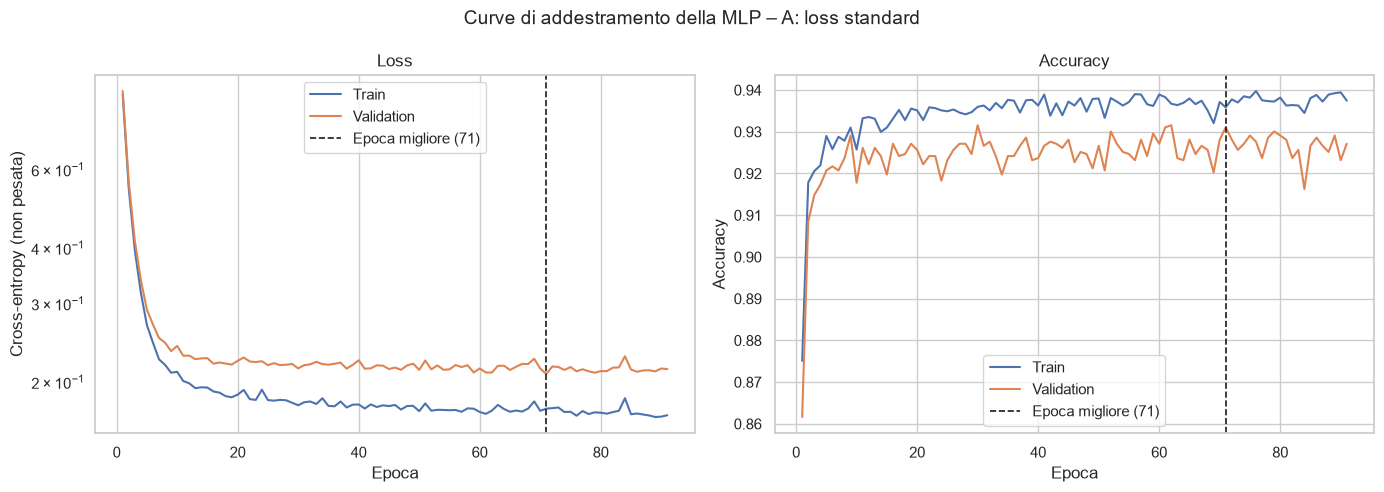

Epoca migliore: 71 | epoche eseguite: 91 | tempo di addestramento: 11.2 s
Alla migliore epoca -> loss train 0.1740, loss val 0.2081, acc train 0.9359, acc val 0.9311


In [46]:
epoche = np.arange(1, storia_training["epoche_eseguite"] + 1)
ep_best = storia_training["epoca_migliore"]

fig, assi = plt.subplots(1, 2, figsize=(14, 5))
assi[0].plot(epoche, storia_training["loss_train"], label="Train")
assi[0].plot(epoche, storia_training["loss_val"], label="Validation")
assi[0].set_ylabel("Cross-entropy (non pesata)")
assi[0].set_yscale("log")
assi[0].set_title("Loss")
assi[1].plot(epoche, storia_training["acc_train"], label="Train")
assi[1].plot(epoche, storia_training["acc_val"], label="Validation")
assi[1].set_ylabel("Accuracy")
assi[1].set_title("Accuracy")
for ax in assi:
    ax.axvline(ep_best, color="k", linestyle="--", lw=1.2, label=f"Epoca migliore ({ep_best})")
    ax.set_xlabel("Epoca")
    ax.legend()
fig.suptitle(f"Curve di addestramento della MLP – {scelta}", fontsize=14)
fig.tight_layout()
salva_figura(fig, "06_dl_curve")
plt.show()

print(f"Epoca migliore: {ep_best} | epoche eseguite: {storia_training['epoche_eseguite']} "
      f"| tempo di addestramento: {storia_training['tempo_s']:.1f} s")
print(f"Alla migliore epoca -> loss train {storia_training['loss_train'][ep_best - 1]:.4f}, "
      f"loss val {storia_training['loss_val'][ep_best - 1]:.4f}, "
      f"acc train {storia_training['acc_train'][ep_best - 1]:.4f}, "
      f"acc val {storia_training['acc_val'][ep_best - 1]:.4f}")

### 6.6 Valutazione sul test
Solo ora il test entra in gioco: i dati sono convertiti in tensori, la rete (con i pesi dell'epoca migliore)
produce i logit, da cui si ricavano le **probabilità** con la softmax e la classe predetta con l'`argmax`.
Le metriche si calcolano con la stessa funzione `valuta_modello` dei classificatori shallow, e la matrice di
confusione e la curva ROC con gli stessi helper.

In [47]:
Xt_test, yt_test = a_tensori(X_test_s, y_test)
_, _, y_pred_mlp, y_proba_mlp = valuta_su(modello_mlp, Xt_test, yt_test)

metriche_mlp = valuta_modello("MLP (PyTorch)", y_test, y_pred_mlp, y_proba_mlp)
display(metriche_mlp.to_frame())
print("Metriche a piena precisione:", {k: round(float(v), 10) for k, v in metriche_mlp.items()})
print(classification_report(y_test, y_pred_mlp, target_names=NOMI_CLASSI, digits=4))

,MLP (PyTorch)
Accuracy,0.9198
Precision (macro),0.9344
Recall (macro),0.9342
F1 (macro),0.9341
Precision (weighted),0.9207
Recall (weighted),0.9198
F1 (weighted),0.9201
ROC AUC (OvR macro),0.9949


Metriche a piena precisione: {'Accuracy': 0.9197834646, 'Precision (macro)': 0.9343683828, 'Recall (macro)': 0.9341582418, 'F1 (macro)': 0.934139692, 'Precision (weighted)': 0.9206617528, 'Recall (weighted)': 0.9197834646, 'F1 (weighted)': 0.9200564409, 'ROC AUC (OvR macro)': 0.9949390994}
              precision    recall  f1-score   support

    BARBUNYA     0.9394    0.9394    0.9394       198
      BOMBAY     1.0000    1.0000    1.0000        78
        CALI     0.9419    0.9265    0.9342       245
    DERMASON     0.9208    0.8966    0.9086       532
       HOROZ     0.9401    0.9570    0.9485       279
       SEKER     0.9597    0.9408    0.9502       304
        SIRA     0.8386    0.8788    0.8582       396

    accuracy                         0.9198      2032
   macro avg     0.9344    0.9342    0.9341      2032
weighted avg     0.9207    0.9198    0.9201      2032



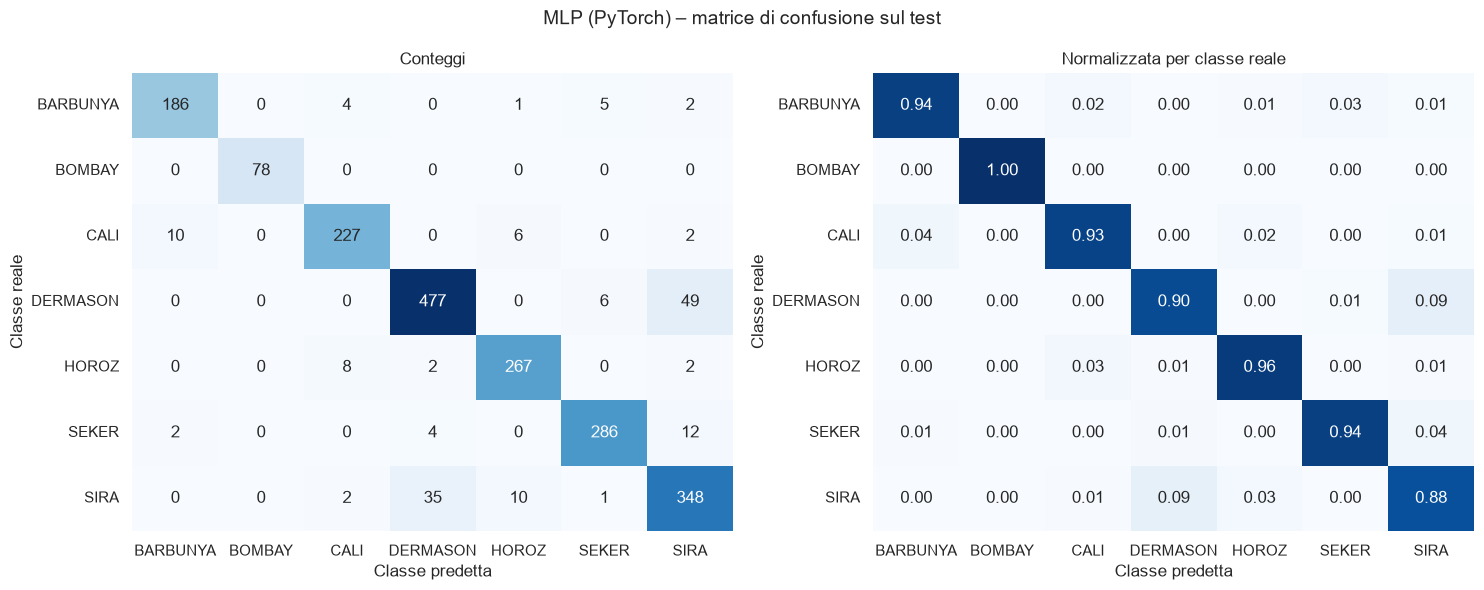

Campioni classificati male: 163 su 2032
Errori più frequenti (reale -> predetta):
  DERMASON -> SIRA: 49
  SIRA -> DERMASON: 35
  SEKER -> SIRA: 12
  CALI -> BARBUNYA: 10
  SIRA -> HOROZ: 10
  HOROZ -> CALI: 8


In [48]:
cm_mlp = plot_confusion(y_test, y_pred_mlp, NOMI_CLASSI,
                        "MLP (PyTorch) – matrice di confusione sul test", "06_cm_mlp")

# coppie di classi più spesso confuse (reale -> predetta), fuori diagonale
errori = [(NOMI_CLASSI[r], NOMI_CLASSI[c], int(cm_mlp[r, c]))
          for r in range(N_CLASSI) for c in range(N_CLASSI) if r != c and cm_mlp[r, c] > 0]
errori.sort(key=lambda t: -t[2])
print(f"Campioni classificati male: {sum(e[2] for e in errori)} su {len(y_test)}")
print("Errori più frequenti (reale -> predetta):")
for reale, predetta, n in errori[:6]:
    print(f"  {reale} -> {predetta}: {n}")

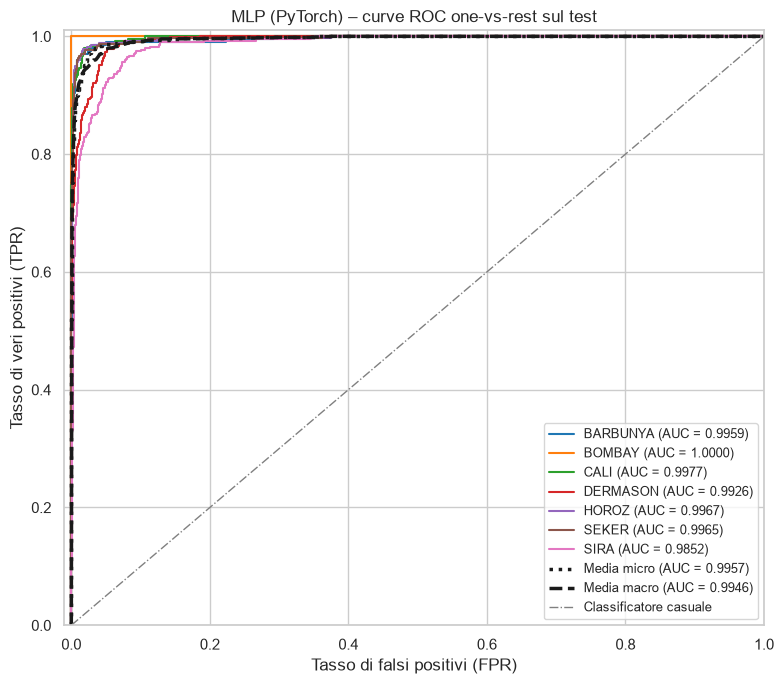

AUC macro: 0.9946 | AUC micro: 0.9957
AUC per classe: {'BARBUNYA': 0.9959, 'BOMBAY': 1.0, 'CALI': 0.9977, 'DERMASON': 0.9926, 'HOROZ': 0.9967, 'SEKER': 0.9965, 'SIRA': 0.9852}


In [49]:
roc_mlp = plot_roc(y_test, y_proba_mlp, NOMI_CLASSI,
                   "MLP (PyTorch) – curve ROC one-vs-rest sul test", "06_roc_mlp",
                   nome_modello="MLP (PyTorch)")
print(f"AUC macro: {roc_mlp['auc_macro']:.4f} | AUC micro: {roc_mlp['auc_micro']:.4f}")
print("AUC per classe:", {NOMI_CLASSI[i]: round(v, 4) for i, v in roc_mlp["auc_per_classe"].items()})

### 6.7 Commento ai risultati
**Scelta della funzione di perdita**
- Le due varianti sono molto vicine sul validation: F1 macro 0,9406 con la loss standard (A) contro 0,9381
  con i pesi di classe (B), accuracy 0,9311 contro 0,9286. La differenza (circa 0,0025 di F1 su 2031 campioni)
  è dentro la normale variabilità di campionamento: i pesi non portano un vantaggio misurabile.
- Si usa quindi la **loss standard**, più semplice e con l'F1 macro di validation più alto; la rete
  addestrata con i pesi si ferma anche prima (epoca 34 contro 71), senza ottenere un risultato migliore.

**Addestramento**
- La loss di validation scende rapidamente nelle prime ~10 epoche e poi si stabilizza intorno a 0,21;
  l'epoca migliore è la **71**, la rete si ferma all'epoca 91 per la pazienza di 20 epoche.
  L'addestramento dura **circa 9 secondi** su CPU con un solo thread (8–10 s in esecuzioni ripetute; il
  tempo varia, i risultati no).
- All'epoca migliore l'accuracy è 0,936 sul train e 0,931 sul validation, con loss 0,174 e 0,208:
  il divario è piccolo, quindi **non c'è overfitting marcato**. Dropout e batch normalization contengono lo
  scarto, mentre l'accuracy si ferma intorno al 93% perché alcune varietà hanno caratteristiche geometriche
  che si sovrappongono, non per mancanza di capacità della rete.
- Dopo l'epoca ~30 il miglioramento della loss di validation è marginale: l'*early stopping* evita di
  addestrare più a lungo senza benefici.

**Risultati sul test (2032 campioni, mai usati prima)**
- Accuracy **0,9198**; precision, recall e F1 macro sono 0,9344, 0,9342 e 0,9341; F1 weighted 0,9201.
  L'accuracy sul test è un po' inferiore a quella sul validation (0,9311): la differenza di circa 1,1 punti
  è compatibile con l'errore standard di una stima su circa 2000 campioni (circa 0,6 punti).
- La **ROC AUC** one-vs-rest macro è **0,9949** (calcolata sulle probabilità da `valuta_modello`); la curva
  macro interpolata del grafico riporta 0,9946, una lieve differenza dovuta al metodo di media. In ogni caso
  le curve di tutte le classi sono molto vicine all'angolo in alto a sinistra: le probabilità prodotte dalla
  rete ordinano bene i campioni anche quando la classe predetta è sbagliata.
- **Bombay** è riconosciuta perfettamente (precision, recall e F1 pari a 1,0; AUC 1,0): nello spazio delle feature è
  nettamente distinta dalle altre varietà. Anche Seker, Horoz, Barbunya e
  Cali hanno F1 tra 0,93 e 0,95.
- Le classi più difficili sono **Sira** (F1 0,858, precision 0,839) e **Dermason** (F1 0,909, recall 0,897).
  Sui 163 campioni classificati male, 84 sono scambi tra queste due varietà (49 Dermason predetti come Sira
  e 35 Sira predetti come Dermason), cioè più della metà degli errori. Seguono errori isolati: Seker → Sira
  (12), Cali → Barbunya (10), Sira → Horoz (10), Horoz → Cali (8).
- Poiché le classi sono sbilanciate, accuracy e metriche weighted (dominate da Dermason e Sira) sono
  leggermente inferiori a quelle macro, che beneficiano delle prestazioni perfette su Bombay.

Il confronto quantitativo con i classificatori shallow, valutati sullo stesso test, è nella sezione 7.

## 7. Confronto finale e conclusioni
Questa sezione mette a confronto, **sullo stesso test set** (2.032 campioni mai usati per addestramento o
scelta degli iperparametri), i cinque classificatori shallow della sezione 4 e la rete neurale della sezione 6.
Le metriche vengono dal dizionario `RISULTATI`, alimentato da `valuta_modello`, e sono salvate in
`results/metrics_test.csv`.

### 7.1 Tabella riepilogativa delle metriche sul test

In [50]:
from scipy.stats import binomtest, norm
from sklearn.metrics import f1_score

TIPO_MODELLO = {nome: "shallow" for nome in MODELLI_SHALLOW}
TIPO_MODELLO["MLP (PyTorch)"] = "deep learning"

tabella_finale = pd.DataFrame(RISULTATI).T
tabella_finale.insert(0, "Tipo", pd.Series(TIPO_MODELLO))
tabella_finale = tabella_finale.sort_values("F1 (macro)", ascending=False)
tabella_finale.index.name = "Modello"
# piena precisione: chi legge il CSV arrotonda una volta sola, ottenendo gli stessi valori del notebook
tabella_finale.to_csv(CARTELLA_RISULTATI / "metrics_test.csv")

metriche_numeriche = tabella_finale.columns.drop("Tipo")
(tabella_finale.style
    .format("{:.4f}", subset=metriche_numeriche)
    .highlight_max(subset=metriche_numeriche, color="#c6e5c6"))

,Tipo,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),ROC AUC (OvR macro)
Modello,,,,,,,,,
Logistic Regression,shallow,0.9222,0.9353,0.9360,0.9355,0.9227,0.9222,0.9224,0.9944
SVM (RBF),shallow,0.9213,0.9356,0.9345,0.9350,0.9215,0.9213,0.9214,0.9943
MLP (PyTorch),deep learning,0.9198,0.9344,0.9342,0.9341,0.9207,0.9198,0.9201,0.9949
Random Forest,shallow,0.9178,0.9300,0.9309,0.9304,0.9177,0.9178,0.9177,0.9931
KNN,shallow,0.9158,0.9310,0.9284,0.9295,0.9166,0.9158,0.9161,0.9911
Decision Tree,shallow,0.9011,0.9165,0.9108,0.9135,0.9010,0.9011,0.9009,0.9754


### 7.2 Confronto grafico delle metriche principali
Per ciascun modello sono riportate accuracy, F1 macro e ROC AUC. L'asse orizzontale non parte da zero:
serve a rendere leggibili differenze che sono dell'ordine di qualche decimo di punto percentuale.

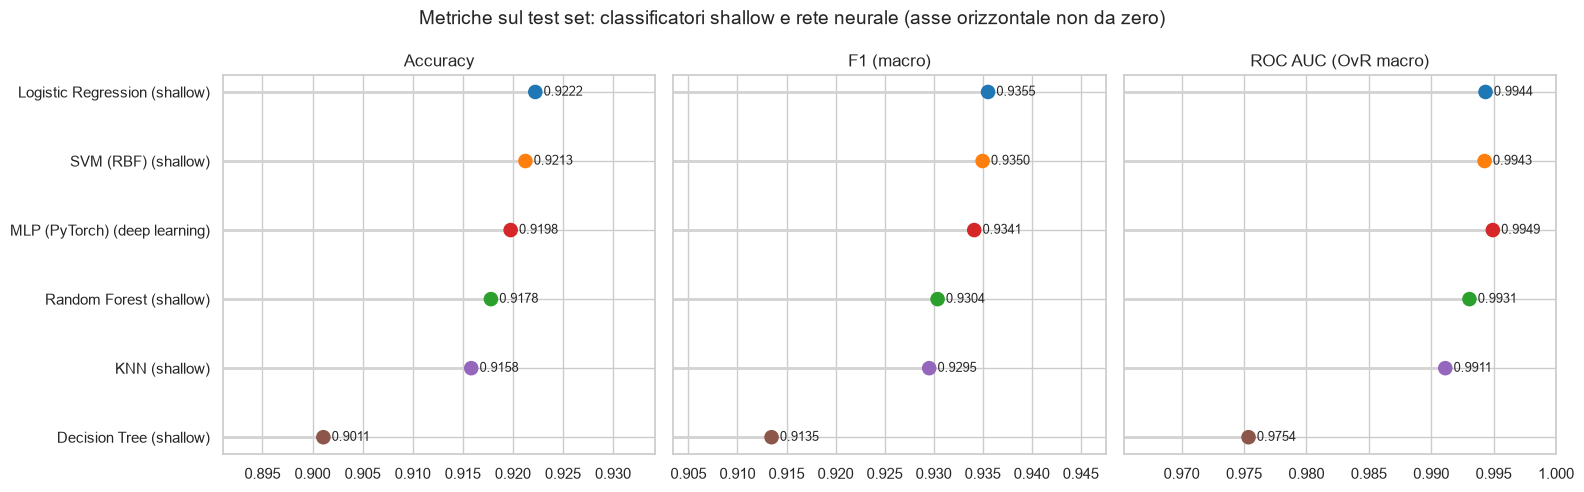

In [51]:
metriche_grafico = ["Accuracy", "F1 (macro)", "ROC AUC (OvR macro)"]
ordine = tabella_finale.index[::-1]           # il migliore in alto

fig, assi = plt.subplots(1, len(metriche_grafico), figsize=(16, 5), sharey=True)
for ax, metrica in zip(assi, metriche_grafico):
    valori = tabella_finale.loc[ordine, metrica]
    colori = [COLORI_MODELLI[m] for m in ordine]
    ax.hlines(range(len(ordine)), valori.min() - 0.01, valori, color="lightgrey", lw=2)
    ax.scatter(valori, range(len(ordine)), color=colori, s=90, zorder=3)
    for k, v in enumerate(valori):
        ax.annotate(f"{v:.4f}", (v, k), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
    ax.set_xlim(valori.min() - 0.01, min(valori.max() + 0.012, 1.0))
    ax.set_title(metrica)
    ax.set_yticks(range(len(ordine)))
    ax.set_yticklabels([f"{m} ({TIPO_MODELLO[m]})" for m in ordine])
fig.suptitle("Metriche sul test set: classificatori shallow e rete neurale (asse orizzontale non da zero)",
             fontsize=14)
fig.tight_layout()
salva_figura(fig, "07_confronto_metriche")
plt.show()

### 7.3 Curve ROC macro-medie di tutti i modelli
Ogni curva è la media macro delle curve one-vs-rest delle 7 classi (sezioni 5 e 6). Il riquadro ingrandisce
la zona a basso tasso di falsi positivi, l'unica in cui i modelli si distinguono.
L'AUC in legenda è l'area sotto la curva macro interpolata; può differire di qualche decimillesimo dalla
ROC AUC della tabella 7.1, che è la media delle AUC delle singole classi (`roc_auc_score`).

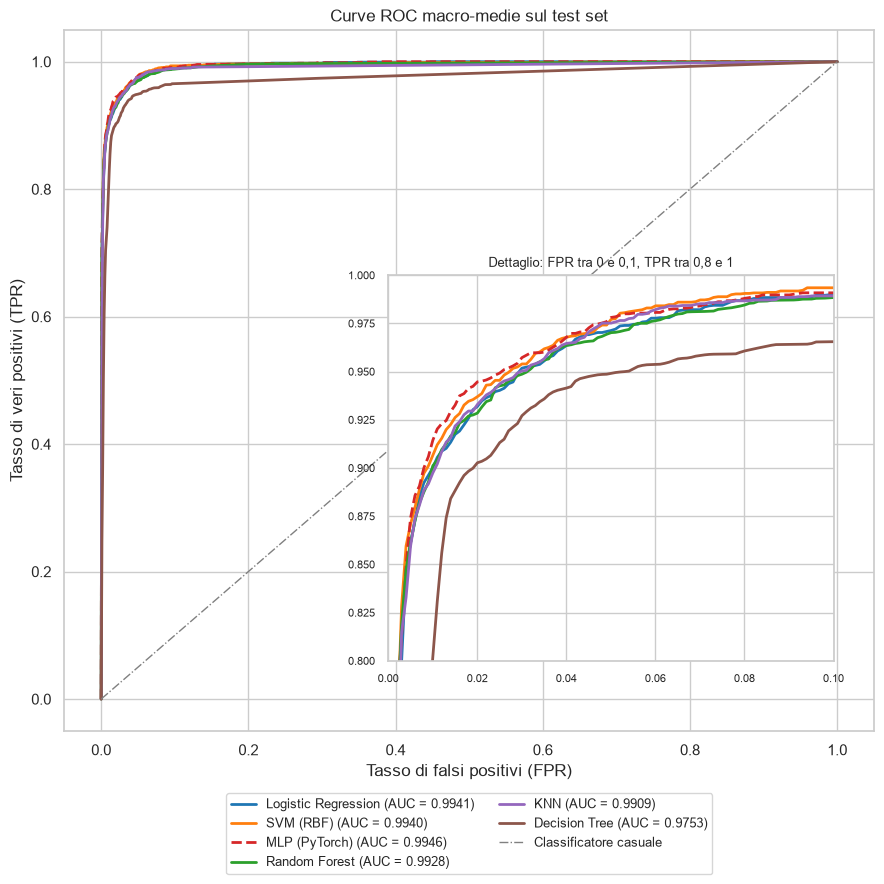

In [52]:
fig, ax = plt.subplots(figsize=(9, 9))
riquadro = ax.inset_axes([0.4, 0.1, 0.55, 0.55])
for nome in tabella_finale.index:
    fpr, tpr, valore_auc = CURVE_ROC[nome]
    stile = "--" if TIPO_MODELLO[nome] == "deep learning" else "-"
    ax.plot(fpr, tpr, stile, lw=2, color=COLORI_MODELLI[nome], label=f"{nome} (AUC = {valore_auc:.4f})")
    riquadro.plot(fpr, tpr, stile, lw=2, color=COLORI_MODELLI[nome])
ax.plot([0, 1], [0, 1], color="grey", lw=1, linestyle="-.", label="Classificatore casuale")
riquadro.set_xlim(0, 0.1)
riquadro.set_ylim(0.8, 1.0)
riquadro.set_title("Dettaglio: FPR tra 0 e 0,1, TPR tra 0,8 e 1", fontsize=9)
riquadro.tick_params(labelsize=8)
ax.set_xlabel("Tasso di falsi positivi (FPR)")
ax.set_ylabel("Tasso di veri positivi (TPR)")
ax.set_title("Curve ROC macro-medie sul test set")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=9)
fig.tight_layout()
salva_figura(fig, "07_confronto_roc")
plt.show()

### 7.4 F1 per classe
La mappa di calore mostra l'F1 di ciascuna varietà per ogni modello: permette di capire se le differenze
tra modelli dipendono da classi specifiche o sono distribuite.

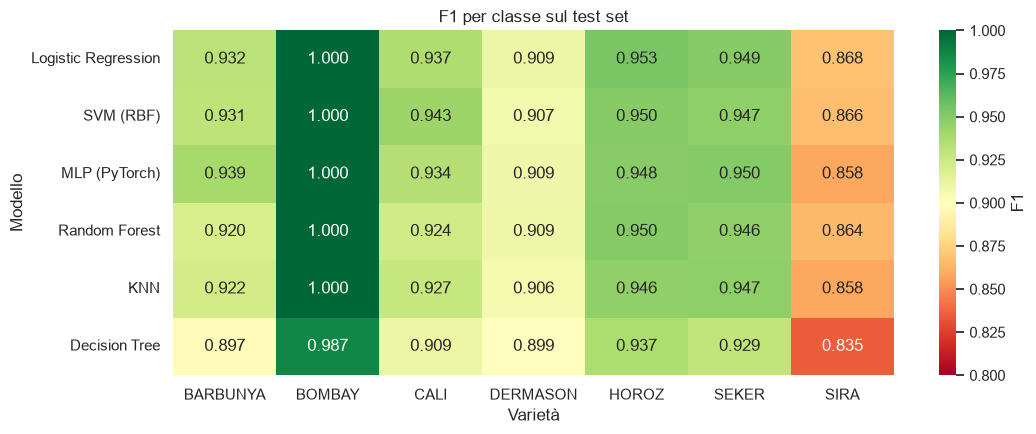

In [53]:
PREVISIONI_TEST = {nome: y_pred for nome, (y_pred, _) in PREVISIONI_SHALLOW.items()}
PREVISIONI_TEST["MLP (PyTorch)"] = y_pred_mlp

f1_per_classe = pd.DataFrame(
    {nome: f1_score(y_test, PREVISIONI_TEST[nome], average=None) for nome in tabella_finale.index},
    index=NOMI_CLASSI,
).T

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(f1_per_classe, annot=True, fmt=".3f", cmap="RdYlGn", vmin=0.8, vmax=1.0,
            cbar_kws={"label": "F1"}, ax=ax)
ax.set_xlabel("Varietà")
ax.set_ylabel("Modello")
ax.set_title("F1 per classe sul test set")
fig.tight_layout()
salva_figura(fig, "07_f1_per_classe")
plt.show()

### 7.5 Le differenze tra i modelli sono significative?
Il test set ha dimensione finita, quindi ogni accuracy è una stima con un'incertezza. Si usano due strumenti:

- l'**intervallo di confidenza al 95%** dell'accuracy (metodo di Wilson), che dà l'ordine di grandezza
  dell'incertezza dovuta al campione;
- il **test di McNemar** (versione esatta, binomiale), adatto a confrontare due classificatori valutati
  **sugli stessi campioni**. Considera solo i casi in cui i due modelli non sono d'accordo:
  *b* = campioni corretti solo per il primo, *c* = corretti solo per il secondo.
  Sotto l'ipotesi nulla di pari accuratezza, *b* segue una binomiale di parametri (*b* + *c*, 0,5).

Il modello di riferimento è il primo della tabella 7.1, scelto quindi *a posteriori* guardando il test: per questo,
e perché i confronti sono più di uno, accanto al p-value grezzo si riporta quello corretto con **Bonferroni**
(p-value moltiplicato per il numero di confronti), che è la soglia più prudente.

In [54]:
def intervallo_wilson(successi, n, livello=0.95):
    """Intervallo di confidenza di Wilson per una proporzione."""
    z = norm.ppf(1 - (1 - livello) / 2)
    p = successi / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    semiampiezza = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - semiampiezza, centro + semiampiezza


n_test = len(y_test)
corretti = {nome: PREVISIONI_TEST[nome] == y_test for nome in tabella_finale.index}

righe_ic = []
for nome in tabella_finale.index:
    k = int(corretti[nome].sum())
    basso, alto = intervallo_wilson(k, n_test)
    righe_ic.append({"Modello": nome, "Accuracy": k / n_test, "IC 95% inf.": basso, "IC 95% sup.": alto})
intervalli = pd.DataFrame(righe_ic).set_index("Modello")

riferimento = tabella_finale.index[0]
altri_modelli = tabella_finale.index[1:]
righe_mcnemar = []
for nome in altri_modelli:
    b = int((corretti[riferimento] & ~corretti[nome]).sum())
    c = int((~corretti[riferimento] & corretti[nome]).sum())
    p_valore = binomtest(b, b + c, 0.5).pvalue if b + c > 0 else 1.0
    p_bonferroni = min(1.0, p_valore * len(altri_modelli))
    righe_mcnemar.append({"Confronto": f"{riferimento} vs {nome}", "b (solo rif. corretto)": b,
                          "c (solo altro corretto)": c, "p-value": p_valore, "p-value (Bonferroni)": p_bonferroni,
                          "Significativa (α = 0,05, Bonferroni)": "sì" if p_bonferroni < 0.05 else "no"})
mcnemar = pd.DataFrame(righe_mcnemar).set_index("Confronto")

print(f"Intervalli di confidenza al 95% dell'accuracy (n = {n_test})")
display(intervalli.style.format("{:.4f}"))
print(f"\nTest di McNemar esatto rispetto al modello di riferimento: {riferimento}")
display(mcnemar.style.format({"p-value": "{:.4f}", "p-value (Bonferroni)": "{:.4f}"}))

Intervalli di confidenza al 95% dell'accuracy (n = 2032)


,Accuracy,IC 95% inf.,IC 95% sup.
Modello,,,
Logistic Regression,0.9222,0.9098,0.9331
SVM (RBF),0.9213,0.9087,0.9322
MLP (PyTorch),0.9198,0.9072,0.9308
Random Forest,0.9178,0.9051,0.9290
KNN,0.9158,0.9030,0.9271
Decision Tree,0.9011,0.8873,0.9133



Test di McNemar esatto rispetto al modello di riferimento: Logistic Regression


,b (solo rif. corretto),c (solo altro corretto),p-value,p-value (Bonferroni),"Significativa (α = 0,05, Bonferroni)"
Confronto,,,,,
Logistic Regression vs SVM (RBF),27,25,0.8899,1.0000,no
Logistic Regression vs MLP (PyTorch),26,21,0.5601,1.0000,no
Logistic Regression vs Random Forest,41,32,0.3492,1.0000,no
Logistic Regression vs KNN,42,29,0.1539,0.7696,no
Logistic Regression vs Decision Tree,84,41,0.0002,0.0008,sì


Per completare il quadro degli errori, le tre coppie di classi più confuse da ciascun modello (errori nei due
versi sommati) e la recall per classe, cioè la quota di campioni di ogni varietà riconosciuti correttamente.

In [55]:
righe_coppie = []
for nome in tabella_finale.index:
    cm = confusion_matrix(y_test, PREVISIONI_TEST[nome])
    errori_coppie = sorted(
        ((int(cm[i, j] + cm[j, i]), f"{NOMI_CLASSI[i]}–{NOMI_CLASSI[j]}")
         for i in range(len(NOMI_CLASSI)) for j in range(i + 1, len(NOMI_CLASSI))),
        reverse=True)
    riga = {"Modello": nome, "Errori totali": int(cm.sum() - np.trace(cm))}
    for posizione, (n_errori, coppia) in enumerate(errori_coppie[:3], start=1):
        riga[f"{posizione}ª coppia"] = f"{coppia} ({n_errori})"
    righe_coppie.append(riga)
display(pd.DataFrame(righe_coppie).set_index("Modello"))

recall_per_classe = pd.DataFrame(
    {nome: recall_score(y_test, PREVISIONI_TEST[nome], average=None) for nome in tabella_finale.index},
    index=NOMI_CLASSI,
).T
display(recall_per_classe.style.format("{:.3f}"))

,Errori totali,1ª coppia,2ª coppia,3ª coppia
Modello,,,,
Logistic Regression,158,DERMASON–SIRA (80),BARBUNYA–CALI (16),DERMASON–SEKER (13)
SVM (RBF),160,DERMASON–SIRA (82),DERMASON–SEKER (14),BARBUNYA–CALI (14)
MLP (PyTorch),163,DERMASON–SIRA (84),CALI–HOROZ (14),BARBUNYA–CALI (14)
Random Forest,167,DERMASON–SIRA (80),BARBUNYA–CALI (21),DERMASON–SEKER (15)
KNN,171,DERMASON–SIRA (84),BARBUNYA–CALI (18),CALI–HOROZ (15)
Decision Tree,201,DERMASON–SIRA (89),BARBUNYA–CALI (25),SEKER–SIRA (18)


,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
Logistic Regression,0.929,1.000,0.935,0.897,0.953,0.954,0.884
SVM (RBF),0.919,1.000,0.943,0.902,0.953,0.947,0.876
MLP (PyTorch),0.939,1.000,0.927,0.897,0.957,0.941,0.879
Random Forest,0.929,1.000,0.914,0.908,0.950,0.954,0.861
KNN,0.899,1.000,0.935,0.898,0.946,0.944,0.876
Decision Tree,0.879,0.974,0.922,0.915,0.935,0.931,0.818


Gli intervalli di confidenza dei primi cinque modelli si sovrappongono ampiamente (semiampiezza di circa 1,2 punti
percentuali). Il test di McNemar lo conferma: rispetto alla Logistic Regression **nessuna** differenza con SVM,
MLP, Random Forest e KNN è statisticamente significativa (p-value grezzi tra 0,15 e 0,89, ancora più alti dopo
la correzione di Bonferroni). L'unico modello significativamente peggiore è il **Decision Tree** (p ≈ 0,0002,
≈ 0,0008 con Bonferroni): i campioni che sbaglia solo lui sono circa il doppio di quelli sbagliati solo dalla
Logistic Regression.

Le tabelle degli errori mostrano che **Dermason–Sira è la prima coppia confusa per tutti i modelli** e da sola
vale tra il 44% e il 52% degli errori di ciascuno. Le coppie successive hanno molti meno errori (tra 13 e 25) e
cambiano da modello a modello: per lo più Barbunya–Cali, poi Dermason–Seker o Cali–Horoz.

### 7.6 Conclusioni

**Dati e preprocessing.** Il Dry Bean Dataset (13.611 semi, 16 feature geometriche, 7 varietà) è pulito ma
contiene 68 righe duplicate, rimosse prima della suddivisione per evitare che lo stesso campione compaia
sia nel training sia nel test. Lo split stratificato 70/15/15, fissato una volta sola e salvato su file,
è stato usato da tutti i modelli, rete neurale compresa, come richiesto dalla traccia.

**PCA (Task 1).** Le feature sono fortemente ridondanti: le prime due componenti spiegano circa l'82% della
varianza e ne bastano quattro per superare il 95%. Le componenti hanno un'interpretazione chiara (PC1 dimensione,
PC2 forma tondeggiante o allungata, PC3 convessità del contorno). Nel piano PC1–PC2 Bombay, Seker e Horoz sono ben
separate, mentre Dermason–Sira e Barbunya–Cali si sovrappongono. Ridurre i dati a 4 componenti costa però circa
3 punti di accuracy alla Logistic Regression, per questo i modelli lavorano sulle 16 feature standardizzate.

**Classificatori shallow (Task 2–4).** Quattro modelli su cinque (Logistic Regression, SVM RBF, Random Forest e
KNN) ottengono prestazioni equivalenti: accuracy tra 0,916 e 0,922, F1 macro tra 0,930 e 0,936, ROC AUC tra
0,991 e 0,994. L'ordine tra loro non è statisticamente significativo e sul validation era diverso. Il Decision
Tree, unico modello formato da un solo albero, è il più debole su tutte le metriche ed è l'unico
significativamente peggiore.

**Deep learning (Task 5a).** La MLP in PyTorch (13.191 parametri, early stopping sul validation) si colloca nello
stesso gruppo: accuracy ≈ 0,920, F1 macro ≈ 0,934, ROC AUC ≈ 0,995. La differenza con la Logistic Regression non è
significativa (McNemar, p ≈ 0,56), e anche la ROC AUC leggermente più alta (+0,0005) rientra nella variabilità.
Il risultato è coerente con la natura del problema: poche feature tabellari già informative, classi in gran
parte separabili anche da un modello lineare e circa 9.500 campioni di training. In queste condizioni una rete
neurale non ha strutture complesse da sfruttare in più rispetto ai modelli classici.

**Dove sbagliano i modelli.** Per tutti i modelli l'errore principale è lo scambio tra Dermason e Sira, che vale
circa metà degli errori. Le due varietà restano comunque riconosciute nella grande maggioranza dei casi
(recall di Dermason 0,90–0,92, di Sira 0,82–0,88), mentre Bombay è riconosciuta perfettamente dai modelli migliori.
Il fatto che modelli molto diversi, lineari, a distanza, ad alberi e reti neurali, commettano lo stesso errore
suggerisce che il limite stia nelle feature più che nei modelli: Dermason e Sira hanno forma e dimensione
simili e la sola geometria del contorno non basta a separarle del tutto.

**Limiti e possibili sviluppi.**
- Le stime vengono da un solo split: una validazione incrociata ripetuta darebbe intervalli più stretti per il
  confronto tra modelli.
- Alcuni iperparametri scelti cadono sul bordo della griglia (C della Logistic Regression, C e γ della SVM);
  il vantaggio rispetto alle configurazioni vicine è però inferiore a un decimo di punto percentuale di F1 macro.
- Feature aggiuntive estratte dalle immagini (colore, tessitura) potrebbero aiutare a separare Dermason e Sira.
- Ensemble dei modelli migliori o tecniche di spiegabilità come SHAP potrebbero chiarire quali feature
  guidano gli errori residui.